In [1]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:88% !important; }</style>"))

# MC2fit / GALFIT workflow for the PSB sample

This notebook runs a staged **one- to four-component GALFIT analysis** using the `DH_MC2fit` framework. It is organized as an analysis notebook rather than a single, restart-safe pipeline: several cells are optional diagnostics, destructive cleanup commands, or alternative experiments. Read the notes immediately above each cell before running the notebook from top to bottom.

## Main workflow

1. **Initialize the environment and target directories.**
2. **Validate images and PSFs**, and derive PSF-based lower limits for compact Sérsic components.
3. **Fit one-component models** in the g and r bands, including alternative masks.
4. **Use the preferred one-component results as initial guesses** for two-component models.
5. **Repeat the hierarchical procedure** for three- and four-component models.
6. **Post-process and compare models** using fit statistics evaluated over a controlled region of interest.
7. **Inspect individual galaxies** and save reusable `ResPack` objects.

## Important execution conventions

- `Setting` stores global paths, image properties, multiprocessing options, and statistical criteria.
- `Runlist` defines the model family, initial guesses, constraints, and GALFIT component ordering.
- `update_Class()` attaches a `Runlist` and a `DirInfo` object to a setting. Because these objects are deep-copied internally, later changes to the original objects are not automatically propagated.
- `run()` launches GALFIT for each target and runlist entry.
- `extract()` converts or retains the compact result products and may remove large `output_*.fits` files.
- `postprocessing()` computes diagnostic statistics.
- `pack_result()` collects results across the sample and makes them convenient to save and reuse.
| Term | Meaning |
|---|---|
| `DirInfo` | Object that stores the directory structure and target information for each galaxy. |
| `ResPack` | A packed result object containing the fitting outputs and diagnostic quantities. |
| `comp1`, `comp2`, ... | GALFIT component numbers. In this notebook, the sky component may occupy one component number, so check the comments carefully. |
| AIC | Akaike Information Criterion. Lower values generally indicate a better balance between goodness of fit and model complexity. |
| reduced χ² | A goodness-of-fit statistic. It is useful for comparing fits, but should be interpreted carefully when the noise model or masks are imperfect. |

> **Safety note:** Cells containing `remove_proj_folder()` or `multicore_remove_folder()` delete previous fitting outputs. They are intentionally left in the notebook, but should normally remain commented unless a clean rerun is required.



In [2]:
# ============================================================
# Imports
# ============================================================
# Standard numerical and table-handling packages
import numpy as np
import pandas as pd

# Plotting and visualization
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.ticker import AutoMinorLocator

# General utilities
import pickle
import time
import copy
import random
import os
import glob
import shutil
from pathlib import Path
from dataclasses import dataclass
from multiprocessing import Pool
import subprocess
import warnings

# Astropy tools for statistics, FITS I/O, WCS, cutouts, and visualization
from astropy.stats import sigma_clip, sigma_clipped_stats
from astropy.io import fits
from astropy.nddata import Cutout2D
from astropy.utils.data import download_file
from astropy.wcs import WCS
from astropy.visualization import ZScaleInterval, ImageNormalize, AsinhStretch
from astropy.modeling.functional_models import Sersic1D, Sersic2D

# Image processing
import skimage
from skimage.transform import resize

# ============================================================
# Custom MC2fit modules
# Repository: https://github.com/galaxydiver/MC2fit
# ============================================================
# Array/path utilities
import DH_array as dharray
import DH_path as dhpath

# Download Legacy Survey images, PSF files, and related products
import DH_LegacyCrawling as dhcrawl

# File and directory management utilities
import DH_FileCheck as dhfc

# Main MC2fit configuration and execution tools
import DH_MC2fit as dhmc2fit


This machine : SO desktop computer
LegacyCrawling - Loading summary fits south :  /home/donghyeon/ua/udg/galfit/galfit/RawData/survey-bricks-dr9-south.fits
LegacyCrawling - Loading summary fits south (DR10) :  /home/donghyeon/ua/udg/galfit/galfit/RawData/survey-bricks-dr10-south.fits
LegacyCrawling - Loading summary fits north :  /home/donghyeon/ua/udg/galfit/galfit/RawData/survey-bricks-dr9-north.fits


In [3]:
## Create a dedicated working directory for this example and move into it.
dir_main = './Galfit_Run/PSB_new'
os.chdir(dir_main)

In [4]:
# Number of CPU workers to use for multicore tasks.
# Use a moderate value for network downloads. Too many simultaneous requests
# can trigger server-side rate limits or timeout errors.
Ncore = 16

# Legacy Survey pixel scale in arcsec / pixel.
# This is needed when converting pixel-based sizes to angular units.
plate_scale = 0.262

# Cutout size in pixels.
# For image_size=121, each cutout is roughly 121 * 0.262 arcsec across.
image_size = 121

## Estimated sky value 
est_sky=10 

# Load the target catalog.
# The catalog must contain at least RA and dec columns.
fn = "./fulldata.csv"
target_catalog = pd.read_csv(fn)

# Extract sky coordinates used by the Legacy Survey download functions.
# The coordinate array has shape (N_target, 2), with columns [RA, dec].
col = ['ra', 'dec']
coord_array = target_catalog[col].to_numpy().astype(float)

# Quick sanity check: display the RA/Dec array that will be passed to download functions.
len(coord_array)


238

In [5]:
# DIdat manages the raw downloaded survey products.
# Each target gets a folder named according to folder_rule, e.g., gal0000/, gal0001/, ...
DIdat = dhfc.DirInfo(
    './',
    dir_work_base='gal_dat/',           # downloaded files
    folder_rule='gal%04d/',             # four-digit folder names; supports up to 9999 targets
                                      # to use five-digit names, use 'gal%05d/'
    coord_array=coord_array,
    idlist=np.arange(len(coord_array)), # internal target IDs
    catalogname_list=target_catalog['name'], # human-readable target names
)

# Print the number of raw-data target directories.
print(len(DIdat.dir_work_list))

# DI manages the standardized fitting/output directory tree.
# The raw data in gal_dat/ are copied or linked into gal_out/ for fitting.
# You can change the folder name when you want to make another set of the fittings.
# When you want to reset all the GALFIT output, remove 'gal_out'
DI = DIdat.change_work_base('gal_out/', return_new=True)

# Print the number of fitting/output target directories.
print(len(DI.dir_work_list))

238
238


In [6]:
## Check the data
dhfc.generate_checkpixel(DIdat, Ncore=15, fna_image='image_dr9_', regionlist=['n'], silent=True)
dhfc.generate_checkpixel(DIdat, Ncore=15, fna_image='image_dr10_', regionlist=['s'], silent=True)
CheckPixels=dhfc.CheckPixel(DIdat, bad_pixel_crit=1e9)
np.where(CheckPixels.pixel_median<1)

## Keep only the good targets for downstream processing.
DIgood = dhfc.cut_DirInfo(DI, np.invert(CheckPixels.list_bad))

Check pixels: ng:   0%|          | 0/238 [00:00<?, ?it/s]

Done! | Time: 0.1 s


Check pixels: nr:   0%|          | 0/238 [00:00<?, ?it/s]

Done! | Time: 0.1 s


Check pixels: sg:   0%|          | 0/238 [00:00<?, ?it/s]

Done! | Time: 0.1 s


Check pixels: sr:   0%|          | 0/238 [00:00<?, ?it/s]

Done! | Time: 0.1 s
Region - s Band - g  exist : 161
Region - s Band - r  exist : 154
Region - s Total exist : 154
Region - n Band - g  exist : 79
Region - n Band - r  exist : 79
Region - n Total exist : 76
List South : 154
List North : 61
List Bad : 23
Previous : 238  |  New :  215


## PSF-based size limits

GALFIT can sometimes converge to unphysical solutions, especially for compact components. To avoid this, the notebook reads PSF size information and uses it to set lower and upper limits on fitted Sérsic component sizes.

The lower limit is set to half of the PSF FWHM in this example. The upper limit is set to the cutout size.

These limits are especially important when fitting multiple components, because one component may otherwise shrink to a PSF-like solution or expand to absorb the sky background.


In [7]:
psf_lim_g=np.loadtxt('./psf_size_lg.dat', ndmin=2) ## value, uncertainty
psf_lim_r=np.loadtxt('./psf_size_lg.dat', ndmin=2) ## value, uncertainty

psf_lim_g[:,0]*=0.5 ## Min (0.5 FWHM)
psf_lim_r[:,0]*=0.5 ## Min (0.5 FWHM)

psf_lim_g[:,1]=image_size ## Max
psf_lim_r[:,1]=image_size ## Max

len(psf_lim_g)

215

# 1-component fitting (Single Sersic)

The first fitting stage models each galaxy with a single Sérsic component. This fit provides a simple baseline model and also supplies useful initial parameters for later multi-component fits.

In this notebook, the one-component fits are run separately for different bands and masks.

## Why start with one component?

We begin with a single Sérsic model before moving on to more complex models. The purpose of this step is not necessarily to obtain the final galaxy model, but to derive a stable first estimate of the galaxy structure.

The best-fit parameters from the single Sérsic model, such as the galaxy center, total magnitude, effective radius, Sérsic index, axis ratio, and position angle, are then used as the initial conditions for the later multi-component fitting steps.

## Key outputs

The one-component section creates packed result files such as:

- `ResPack_g_1Comp.pkl`
- `ResPack_r_1Comp.pkl`

These files are later reloaded to initialize the two-component fits.


Note that comp1 always represents the sky background. Although the section is titled "1-component fitting (Simple Sérsic)," the Sérsic component is actually comp2.


### Main workflow methods

- **`.run()`** calls the multicore GALFIT wrapper. The default thread backend is appropriate because each worker launches an external GALFIT process.
- **`.extract()`** extracts one useful image extension from each large GALFIT output block and normally removes the original `output_*.fits` files afterward.
- **`.postprocessing()`** computes fit statistics and writes compact per-run result files. Optional radius arrays can request statistics within additional apertures.
- **`.pack_result()`** gathers all targets and model groups into a `ResPack` object for comparison and later reuse.
- **`.result(galid=...)`** reads all available fits for one target.
- **`dhmc2fit.ResultBest(Result, ...)`** selects the preferred fit according to `comp_crit`, while optionally excluding warning cases.
- **`.drawing(...)`** displays the data/model/residual products for a selected fit.

### Frequently changed options

| Option | Effect |
|---|---|
| `proj_folder` | Subdirectory created inside every target folder for this model family |
| `fni_image`, `fni_psf`, `fni_sigma`, `fni_masking` | Input filenames expected inside each target directory |
| `Ncore` | Number of parallel workers |
| `backend` | `"thread"` or `"process"`; threads are generally safer in Jupyter for external GALFIT runs |
| `overwrite` | Re-run fits even when outputs already exist |
| `fast_skip` | Skip a target when its `done_galfit.dat` marker exists |
| `use_sky_grad` | Allow GALFIT to fit x and y sky gradients |
| `re_lim_list` | Per-target effective-radius restriction |
| `comp_crit` | Statistic used to rank models, for example `AIC_50` |
| `tolerance` | Range around the minimum statistic used to define near-best models |



## GALFIT parameter order used throughout the notebook

| Index | Parameter | Meaning |
|---:|---|---|
| 0 | `xpos` | Component center in the x direction, in pixels |
| 1 | `ypos` | Component center in the y direction, in pixels |
| 2 | `mag` | Integrated magnitude for a Sérsic component; total magnitude for a PSF |
| 3 | `reff` | Effective radius, in pixels |
| 4 | `n` | Sérsic index |
| 5 | `ar` | Axis ratio, \(b/a\) |
| 6 | `pa` | Position angle in degrees |

For a PSF component, only position and magnitude are physically used; `reff`, `n`, `ar`, and `pa` are placeholders in the shared seven-parameter array.


## g-band

### Setting

In [8]:
# Purpose: Create an MC2fit settings object for this model family and band.
MC2_g_1comp=dhmc2fit.Setting(proj_folder='g_1comp/',           ## Folder name for this fit
                             fni_image = 'image_lg.fits',      ## image name (in DI.dir_work_list)
                             fni_sigma = 'sigma_lg.fits',      ## sigma name (in DI.dir_work_list)
                             fni_psf = 'psf_model_lg.fits',    ## psf name (in DI.dir_work_list)
                             fni_masking= 'masking_c_nb.fits', ## mask name (in DI.dir_work_list)
                             use_sky_grad=False,               ## Gradient Sky (False: Flat sky)
                             image_size = image_size,          ## Image size
                             plate_scale=plate_scale,          ## Plate scale
                             est_sky=est_sky,                  ## Estimated sky value 
                             Ncore=Ncore,                      ## Number of cores
                             re_lim_list=psf_lim_g,            ## PSF size
                          )
MC2_g_1comp 

Setting completed


Setting(proj_folder='g_1comp/', fn_galfit='/home/donghyeon/galfit3.0.7b/galfit', fni_image='image_lg.fits', fni_psf='psf_model_lg.fits', fni_masking='masking_c_nb.fits', fni_sigma='sigma_lg.fits', is_run_galfit_dir_work=False, est_sky=10, use_sky_grad=False, zeromag=22.5, plate_scale=array([0.262, 0.262]), image_size=array([121, 121]), re_lim_list=array([[  1.93820577, 121.        ],
       [  1.7807898 , 121.        ],
       [  2.4731787 , 121.        ],
       [  2.73035868, 121.        ],
       [  2.42490033, 121.        ],
       [  2.02796206, 121.        ],
       [  1.97970105, 121.        ],
       [  2.35881175, 121.        ],
       [  2.74008716, 121.        ],
       [  2.31302998, 121.        ],
       [  2.65713649, 121.        ],
       [  1.75111282, 121.        ],
       [  1.52491976, 121.        ],
       [  2.65014864, 121.        ],
       [  1.68864696, 121.        ],
       [  1.78237218, 121.        ],
       [  1.9183822 , 121.        ],
       [  1.81971533,

### Build the Runlist

Now, we will create a **Runlist**.  

1. We will first set the initial guess for the magnitude and a list of names (`namelist`)
2. `complist` is the list of components excluding the sky. For a single Sérsic component, use `'sersic2'` or `'sersic'`:
    - `'sersic'`: GALFIT uses **total magnitude**.
    - `'sersic2'`: GALFIT uses **surface brightness** instead.

3. `est_params_array` is an array containing the initial guess parameters, with a size of **(Ncomp - 1) × 7**. Note that we will ignore the sky component for this array.

    ```
    index :   [   0    |   1    |     2     |  3   |  4  |   5   |  6  ]
    params:   [  xpos  |  ypos  |    mag    | reff |  n  |  ar   |  pa ]
    ```
    
    - If a value is set to `np.nan`, **GALFIT** will use its default value for the initial guess.  
    - By default:
        - The position (`xpos`, `ypos`) will be set to the center of the image.  
        - Axis ratio (`ar`) and position angle (`pa`) will default to **0**.
        
4. You can group similar fits by assigning a `group_id`. In the results, you will see both the full output and a summary. The summary includes only the best-fitting result from each group.

5. `size_conv` is the size of the convolution box.

6. You can set limits (upper and lower bounds) for each parameter.  Here are examples of how to define the limits:

- `[[comp2_min, comp2_max], [comp3_min, comp3_max], ...]`  
  → Set limits for individual components.

- `[[compall_min, compall_max]]`  
  → Apply the same limits to all components.

In [9]:
# Purpose: Define the GALFIT model grid, component types, initial guesses, and parameter constraints.

est_mag_list=np.arange(20, 32, 3) ## Estimaged magnitude lists (For 'sersic2', this value is the surface brightness)

##===========================================
## Smaller Reff with several different initial brightness
namelist=dharray.array_attach_string(est_mag_list, 's_fs_', add_at_head=True) ## Attach the string in front of the mag.
## Feel free to change the namelist if you want. This naming does not affect the fitting.
## In my case, for the first part of the namelist, I used the model components (s is for sersic, p is for psf)
## For the second part, I used the configuration (f is for full image, l is for large, s is for small)

# Initial guess
est_params_array=np.array([[np.nan, np.nan, est_mag_list, 30, 1, np.nan, np.nan]], dtype='object')
    # index                      [  0   |  1   |      2     |  3 | 4 |  5   |  6 ]
    # params                    [ xpos | ypos |     mag     |reff| n |  ar  |  pa]
    # Nan means that we will use the default value as the initial guess for this parameter.
    # ** For position, we will use the center of the image as the initial guess.
    # We will use the estimated magnitude as the initial guess.
    # Reff is the effective radius in pixel. We will use 30 pixels as the initial guess.
    # n is the Sersic index. We will use 1 as the initial guess.

    
Runlist1Comp=dhmc2fit.Runlist(namelist=namelist, complist=['sersic2'], ## Input the name list and component list. 'sersic2' means Sersic with surface brightness.
                             est_params_array=est_params_array,  ## Initial guess
                             group_id=0, ## Fitting group. I assigned 0 for all simple Sersic fits.
                             size_conv=image_size, ## Convolution box size 
                             lim_pos=np.array([[51, 71]]), ## Position constraint (from - to)
                             lim_n=[[0, 30]],  ## Sersic index constraint (from - to)
                             lim_reff=np.nan, ## Effective radii constraint (I input Nan for now, because we will use different limits for each run) 
                             lim_ar=[[0.2, 1.1]], ## Axis ratio constraint (from - to)
                            )
Runlist1Comp.show_runlist() ## Show the summary

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,s_fs_20,[sersic2],1,nan,nan,20.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
1,s_fs_23,[sersic2],1,nan,nan,23.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
2,s_fs_26,[sersic2],1,nan,nan,26.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
3,s_fs_29,[sersic2],1,nan,nan,29.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0


In [10]:
## Now I want to add a different set of Runlist.

##===========================================
## Larger Reff with several different initial brightness
namelist=dharray.array_attach_string(est_mag_list, 's_fl_', add_at_head=True)
## Same namelist, but I will use 'l' that stands for 'large' initial guess of the radius

est_params_array=np.array([[np.nan, np.nan, est_mag_list, 90, 1, np.nan, np.nan]], dtype='object')
## Initial guess of the radius is now 90, instead of 30 pixel

Runlist1Comp_Part_l=dhmc2fit.Runlist(namelist=namelist, complist=['sersic2'], ## Input the name list and component list. 'sersic2' means Sersic with surface brightness.
                             est_params_array=est_params_array,  ## Initial guess
                             group_id=0, ## Fitting group. I assigned 0 for all simple Sersic fits.
                             size_conv=image_size, ## Convolution box size 
                             lim_pos=np.array([[51, 71]]), ## Position constraint (from - to)
                             lim_n=[[0, 30]],  ## Sersic index constraint (from - to)
                             lim_reff=np.nan, ## Effective radii constraint (I input Nan for now, because we will use different limits for each run) 
                             lim_ar=[[0.2, 1.1]], ## Axis ratio constraint (from - to)
                            )

##===========================================
## Attach to the main Runlist
Runlist1Comp.add_runlist(Runlist1Comp_Part_l) 
Runlist1Comp.show_runlist() ## Show the summary

## Now Runlist1Comp_Part_l is attached to the previous Runlist. 

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,s_fs_20,[sersic2],1,nan,nan,20.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
1,s_fs_23,[sersic2],1,nan,nan,23.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
2,s_fs_26,[sersic2],1,nan,nan,26.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
3,s_fs_29,[sersic2],1,nan,nan,29.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
4,s_fl_20,[sersic2],1,nan,nan,20.,90.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
5,s_fl_23,[sersic2],1,nan,nan,23.,90.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
6,s_fl_26,[sersic2],1,nan,nan,26.,90.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
7,s_fl_29,[sersic2],1,nan,nan,29.,90.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0


In [11]:
## For the Setting class, update the Runlist and Directory information
MC2_g_1comp.update_Class(Runlist1Comp, DIgood)

### Optional - Remove the previous fitting

If you previously ran the same fitting setup and want to start from scratch, you can remove the existing project folder before rerunning.

Be careful with this step: removing a project folder deletes the previous GALFIT outputs for that setup.

In [12]:
# If you want to remove all Galfit data, use the command below
MC2_g_1comp.remove_proj_folder()

>> Remove the project folder:  g_1comp/


Remove folders:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.0 s


### Run Galfit

In [11]:
MC2_g_1comp.run()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 421.2 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



### Extract data

A standard GALFIT output block contains the input image, model, residual, and other extensions, so storing every full block can be expensive. `extract()` uses `ExtractFits` to copy the requested extension—extension 2 by default—into smaller `result_*.fits` files. With the default `clear_output_files=True`, the original `output_*.fits` files are removed after extraction.

In [12]:
MC2_g_1comp.extract()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 5.4 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



Remove files:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.0 s


### PostProcessing

`postprocessing()` reads the extracted GALFIT products and calculates the statistics listed in `stat_itemlist`, including reduced chi-square and AIC-based quantities. These values are later used by `Result` and `ResPack` to compare the trial models.

The model image must already have been extracted unless the corresponding result files exist from an earlier run.

In [13]:
MC2_g_1comp.postprocessing()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 4.7 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



### Results

`result(galid=...)` collects the available runs for one galaxy. `ResultBest` then identifies the preferred model using the selected comparison statistic. `show_data()` prints the fitted parameters and diagnostic values, while `drawing()` displays the image decomposition.

Change `galid` to inspect a different row of `DIgood.dir_work_list`. A fit that is statistically preferred should still be checked visually for unphysical components, boundary solutions, or residual structure.

---

**1. Select Galaxy ID**
```python
galid = 0
```
- Selects the index of the galaxy to analyze from the list.

---

**2. Load Fitting Results**
```python
ResGal = MC2_g_1comp.Result(...)
```
- Initializes the `ResGal` object for a single galaxy.
- `group_id`: Select the group ID you want to evaluate. Use `None` to include all results.
- `comp_crit`: Criterion used to determine the best fit (e.g., `AIC_50`).

---

**3. Display All Fit Results**
```python
ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=False)
```
- Displays all fit results.
- `only_val=True`: Show only numerical values; if `False`, includes uncertainties and warnings.
- `hide_PA=True`: Hides position angles and axis ratios.
- `hide_fail_read=True`: Skips displaying failed fits.

---

**4. Extract the Best Fit**
```python
ResBest = dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
```
- Extracts the best-fitting result.
- `include_warn=True`: Allows selection from fits with warnings.
- `get_single=True`: Returns a single best result instead of a list.

---

**5. Select Best-Fit Filename**
```python
# fn = ResGal.Data.fnlist[ResGal.best[0]]
fn = ResGal.Data.fnlist[ResGal.best_warn[0]]
print(fn)
```
- Retrieves the filename of the best-fitting result (including those with warnings).
- `best_warn[0]`: Index of the best result considering warning cases.

---

**6. Plot GALFIT Model Image**
```python
MC2_g_1comp.drawing(galid=galid, fn=fn)
plt.show()
```
- Loads the GALFIT model result and applies a masking file.
- Displays the model using `matplotlib`.

---

**7. Display Legacy Survey Image**
```python
MC2_g_1comp.drawing_legacy(galid=galid)
```
- Constructs a URL to download a JPEG cutout from the Legacy Survey.
- Fetches and displays the image centered on the galaxy’s coordinates.


In [16]:
dat = fits.getdata('./gal_out/gal0000/image_lg.fits')

In [18]:
dat_mask = fits.getdata('./gal_out/gal0000/masking_c.fits')

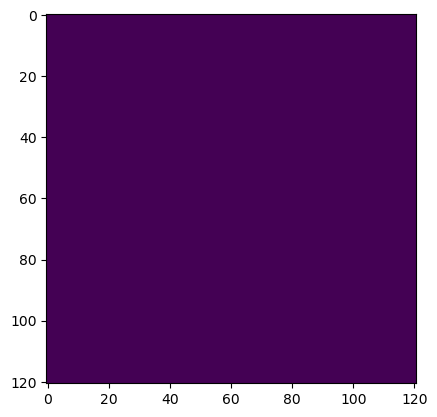

In [19]:
plt.imshow(dat_mask)

In [14]:
DIgood.dir_work_list

array(['./gal_out/gal0000/', './gal_out/gal0001/', './gal_out/gal0002/',
       './gal_out/gal0003/', './gal_out/gal0004/', './gal_out/gal0005/',
       './gal_out/gal0006/', './gal_out/gal0008/', './gal_out/gal0009/',
       './gal_out/gal0010/', './gal_out/gal0011/', './gal_out/gal0012/',
       './gal_out/gal0013/', './gal_out/gal0014/', './gal_out/gal0016/',
       './gal_out/gal0017/', './gal_out/gal0018/', './gal_out/gal0019/',
       './gal_out/gal0020/', './gal_out/gal0021/', './gal_out/gal0022/',
       './gal_out/gal0023/', './gal_out/gal0024/', './gal_out/gal0025/',
       './gal_out/gal0026/', './gal_out/gal0028/', './gal_out/gal0029/',
       './gal_out/gal0030/', './gal_out/gal0031/', './gal_out/gal0032/',
       './gal_out/gal0033/', './gal_out/gal0034/', './gal_out/gal0035/',
       './gal_out/gal0036/', './gal_out/gal0037/', './gal_out/gal0038/',
       './gal_out/gal0039/', './gal_out/gal0040/', './gal_out/gal0041/',
       './gal_out/gal0042/', './gal_out/gal0043/', 

In [12]:
galid=0

## Make the summary
ResGal=MC2_g_1comp.result(galid=galid,
                          group_id=None,  ## Group ID (None means all)
                          comp_crit='AIC_50',  ## Criteria for the best component (AIC_50 means AIC within a circle with a radus of 50 pixels)
                          stat_itemlist=['CHI2NU', 'RChi_F', 'AIC_F', 'LIK_F', 'RChi_50', 'AIC_50', 'LIK_50', ## List of statistics to show
                                          #  'AIC_Rb', 'LIK_Rb', 'AIC_hRb', 'LIK_hRb'
                                           ], 
                         tolerance=1)
## Show the summary
ResGal.show_data(only_val=True,  ## If false, show the uncertainty and warning sign as well.
                 hide_PA=True,  ## Hide the position angle and axis ratio
                 hide_fail_read=False ## Hide the failed galfit run
                    ) 

,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50
s_fs_20,0.000000,0.000000,57.742500,58.216700,22.542500,21.658400,3.291500,15.997900,2.184464,2.184464,31981.278485,0.000000,3.411831,26754.535611,0.000000
s_fs_23,0.000000,0.000000,57.743200,58.215900,22.541800,21.657400,3.290300,15.997800,2.184558,2.184558,31982.645626,0.000000,3.411910,26755.158290,0.000000
s_fs_26,0.000000,0.000000,57.743200,58.215900,22.541800,21.657400,3.290300,15.997800,2.184558,2.184558,31982.651174,0.000000,3.411911,26755.165640,0.000000
s_fs_29,0.000000,0.000000,57.743200,58.215900,22.541800,21.657400,3.290300,15.997800,2.184558,2.184558,31982.646149,0.000000,3.411910,26755.160465,0.000000
s_fl_20,0.000000,0.000000,57.743200,58.215900,22.541800,21.657400,3.290300,15.997800,2.184558,2.184558,31982.643371,0.000000,3.411910,26755.158262,0.000000
s_fl_23,0.000000,0.000000,57.730500,58.220100,25.046800,85.983100,6.416700,15.161100,3.630431,3.630431,53140.112059,0.000000,5.301146,41561.097441,0.000000
s_fl_26,0.000000,0.000000,57.743200,58.215900,22.541800,21.657400,3.290300,15.997800,2.184558,2.184558,31982.648304,0.000000,3.411911,26755.162466,0.000000
s_fl_29,0.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50
s_fs_20,0.000000,0.000000,57.742500,58.216700,22.542500,21.658400,3.291500,0.624200,35.407600,15.997900,2.184464,2.184464,31981.278485,0.000000,3.411831,26754.535611,0.000000


./gal_out/gal0000/g_1comp/result_s_fs_20.fits


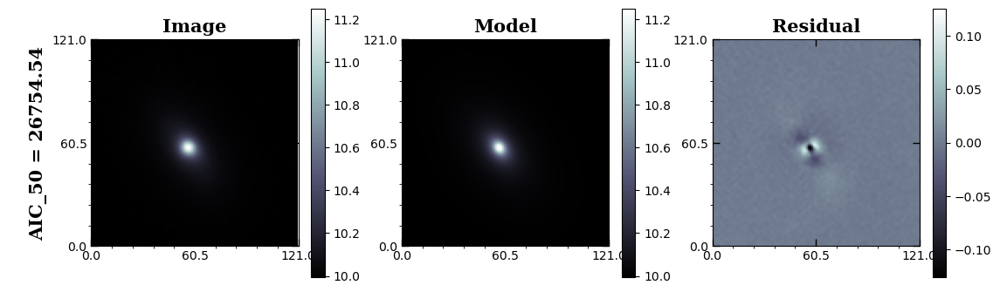

https://www.legacysurvey.org/viewer/jpeg-cutout?ra=198.748944&dec=51.272774&size=200&layer=ls-dr9


HTTPError: HTTP Error 503: Service Temporarily Unavailable

In [13]:
## Make the summary - the best result for each group
## We have only one group now, so it will return a single row.
ResBest=dhmc2fit.ResultBest(ResGal, ## ResGal is the result object
                            include_warn=True, ## Allow the results with warning
                            get_single=True ## When two or more models are the best (converged to the same result), get the single one
                            )

## Show the summary - the best result for each group
ResBest.show_data(only_val=True, hide_PA=False)

## The file name of the best result
fn=ResGal.Data.fnlist[ResGal.best_warn[0]] ## Best result (warning is permitted)
# fn=ResGal.Data.fnlist[ResGal.best[0]] ## Best result (no warning only unless there is no good fitting results)
print(fn) 

## Make the drawing
MC2_g_1comp.drawing(galid=galid, fn=fn) ## Drawing the result
plt.show()
MC2_g_1comp.drawing_legacy(galid=galid) ## Legacy Survey image

### Pack results

`pack_result()` collects the fitting outputs into a single result package. This package is then saved as a pickle file so that later sections can reload the one-component results without rerunning GALFIT.

This saved result is important because it will be used as the initial condition source for the multi-component fits.

In [15]:
ResPack_g_1Comp=MC2_g_1comp.pack_result()
pickle.dump(ResPack_g_1Comp, open(DIgood.dir_base+"ResPack_g_1Comp.pkl", "wb"))

Pack the results
>> comp_crit: AIC_50
>> backend: thread
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 2.5 s


In [16]:
## Load the results
ResPack_g_1Comp=pickle.load(open(DIgood.dir_base+"ResPack_g_1Comp.pkl", "rb"))
ResPack_g_1Comp.preset_generate_onlyval(is_mag=False)

>> Get all submodels


## g-band with central masking


This section repeats the single-Sérsic fitting procedure using a **central mask**.

The goal is to test whether compact central structures, nuclear sources, or bright inner residuals significantly affect the fitted parameters of the outer galaxy. The resulting fit can also be used as an alternative set of initial conditions for later multi-component models.

This section demonstrates two equivalent ways to define the new setup:

1. **Define the setup manually**  
   Manually specify the parameters and file names, following the same structure as in the previous single-Sérsic fitting section.

2. **Copy and modify the previous setup**  
   Copy the previous setup and change only the values that need to be different, such as the project folder name or the masking image.

Both approaches should produce the same result if the final settings are identical. In practice, the second approach is often more convenient because it reduces the chance of accidentally changing unrelated parameters.

If you modify this fitting setup later, make sure that the same changes are applied consistently in whichever method you use.

### Setting Method 1 (Manually - similar to the previous section)

In [11]:
MC2_g_1comp_m=dhmc2fit.Setting(proj_folder='g_1comp_m/',           ## Folder name for this fit
                             fni_image = 'image_lg.fits',      ## image name (in DI.dir_work_list)
                             fni_sigma = 'sigma_lg.fits',      ## sigma name (in DI.dir_work_list)
                             fni_psf = 'psf_model_lg.fits',    ## psf name (in DI.dir_work_list)
                             fni_masking= 'masking_c_nb.fits', ## mask name (in DI.dir_work_list)
                             use_sky_grad=False,               ## Gradient Sky (False: Flat sky)
                             image_size = image_size,          ## Image size
                             plate_scale=plate_scale,          ## Plate scale
                             est_sky=est_sky,                  ## Estimated sky value 
                             Ncore=Ncore                       ## Number of cores
                                
                          )
MC2_g_1comp_m

Setting completed


Setting(proj_folder='g_1comp_m/', fn_galfit='/home/donghyeon/galfit3.0.7b/galfit', fni_image='image_lg.fits', fni_psf='psf_model_lg.fits', fni_masking='masking_c_nb.fits', fni_sigma='sigma_lg.fits', is_run_galfit_dir_work=False, est_sky=10, use_sky_grad=False, zeromag=22.5, plate_scale=array([0.262, 0.262]), image_size=array([121, 121]), re_lim_list=None, Ncore=16, fast_skip=False, overwrite=True, remove_galfit_interval=30, debug=False, use_try=True, extract_sigma=False, output_block=True, show_progress=-1, silent=True, tolerance=11.83, is_tolerance_frac=False, comp_crit='AIC_50', stat_itemlist=['CHI2NU', 'RChi_F', 'AIC_F', 'LIK_F', 'RChi_50', 'AIC_50', 'LIK_50'], ignore_no_files=True)

### Setting Method 2 (Copy and modify the previous setup)

In [12]:
## Here, we will copy the previous setting, and make a necessary change
MC2_g_1comp_m=copy.deepcopy(MC2_g_1comp)
MC2_g_1comp_m.class_update_keys(proj_folder='g_1comp_m/', fni_masking= 'masking_c_d.fits')

### Modify the runlist

In [13]:
## Use the previous Runlist, change the term 'f' to 'm' (full -> masked)
## Again, these namings do not affect the fitting.
Runlist1Comp_m=copy.deepcopy(Runlist1Comp)
for i, text in enumerate(Runlist1Comp_m.runlist['name']):
    newtext=text.split("_")
    newtext[1]="m"+newtext[1][1:]
    Runlist1Comp_m.runlist['name'][i]='_'.join(newtext)
    
MC2_g_1comp_m.update_Class(Runlist1Comp_m, DIgood)
MC2_g_1comp_m.RunlistClass.show_runlist()

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,s_ms_20,[sersic2],1,nan,nan,20.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
1,s_ms_23,[sersic2],1,nan,nan,23.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
2,s_ms_26,[sersic2],1,nan,nan,26.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
3,s_ms_29,[sersic2],1,nan,nan,29.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
4,s_ml_20,[sersic2],1,nan,nan,20.,90.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
5,s_ml_23,[sersic2],1,nan,nan,23.,90.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
6,s_ml_26,[sersic2],1,nan,nan,26.,90.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
7,s_ml_29,[sersic2],1,nan,nan,29.,90.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0


### run, postprocess, pack

In [23]:
# If you want to remove all Galfit data, use the command below
# MC2_g_1comp_m.remove_proj_folder()

In [21]:
MC2_g_1comp_m.run()
MC2_g_1comp_m.extract()
MC2_g_1comp_m.postprocessing()
ResPack_g_1Comp_m=MC2_g_1comp_m.pack_result()
pickle.dump(ResPack_g_1Comp_m, open(DIgood.dir_base+"ResPack_g_1Comp_m.pkl", "wb"))
ResPack_g_1Comp_m=pickle.load(open(DIgood.dir_base+"ResPack_g_1Comp_m.pkl", "rb"))
ResPack_g_1Comp_m.preset_generate_onlyval(is_mag=False)

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 412.8 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 5.6 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



Remove files:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.0 s
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 5.3 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

Pack the results
>> comp_crit: AIC_50
>> backend: thread
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 2.5 s
>> Get all submodels


### Result

,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50
s_ms_20,0.000000,0.000000,62.062500,61.136400,31.525400,89.269900,30.000000,20.735300,0.704437,0.704437,9759.778414,1.000000,0.735779,5631.482899,1.000000
s_ms_23,0.000000,0.000000,62.077000,61.145500,30.499300,53.365900,30.000000,20.852400,0.704170,0.704170,9756.090580,1.000000,0.735292,5627.767465,1.000000
s_ms_26,0.000000,0.000000,62.088900,61.170600,28.795700,21.666100,30.000000,21.011300,0.703765,0.703765,9750.483989,1.000000,0.734546,5622.076302,1.000000
s_ms_29,0.000000,0.000000,62.091600,61.170000,28.672100,20.600000,30.000000,21.018500,0.703722,0.703722,9749.899236,1.000000,0.734474,5621.526588,1.000000
s_ml_20,0.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
s_ml_23,0.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
s_ml_26,0.000000,0.000000,62.048300,61.139200,31.975600,107.512100,30.000000,20.686600,0.704593,0.704593,9761.947356,1.000000,0.736062,5633.645181,1.000000
s_ml_29,0.000000,0.000000,62.088100,61.146800,29.864300,40.007500,30.000000,20.913900,0.704012,0.704012,9753.908273,1.000000,0.735004,5625.571048,1.000000


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50
s_ms_29,0.000000,0.000000,62.091600,61.170000,28.672100,20.600000,30.000000,0.646800,76.499500,21.018500,0.703722,0.703722,9749.899236,1.000000,0.734474,5621.526588,1.000000


./gal_out/gal0004/g_1comp_m/result_s_ms_29.fits


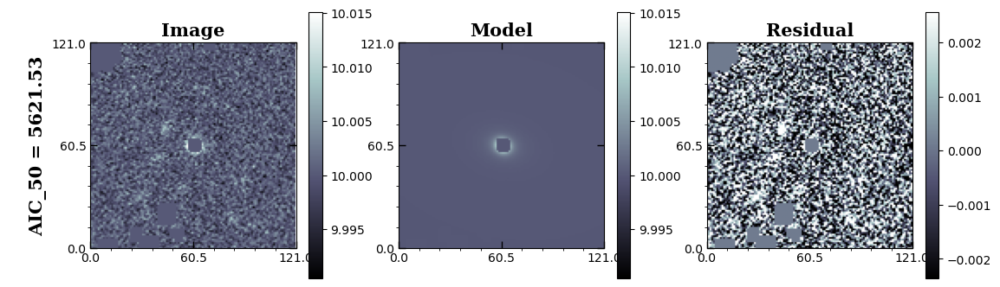

In [22]:
galid=4

ResGal=MC2_g_1comp_m.result(galid=galid, group_id=None)
ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=False) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]] ## avoid warning results if possible 
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]  ## Best results regardlenss of warning
print(fn)

MC2_g_1comp_m.drawing(galid=galid, fn=fn)
plt.show()
# MC2_g_1comp_m.drawing_legacy(galid=galid)

In the case when you want to check the image with different masking,

change the masking file as follows:

```python
MC2_g_1comp_m.drawing(galid=galid, fn=fn, fni_masking='masking_c_nb.fits')
```

- `fni_masking`: change the file name rule of the masking files

This only changes the masking, not the statistical values, such as AIC


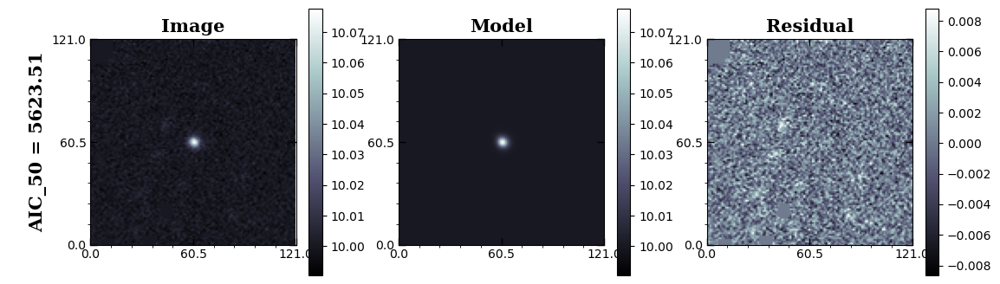

In [68]:
MC2_g_1comp_m.drawing(galid=galid, fn=fn, fni_masking='masking_c.fits')
plt.show()
# MC2_1Comp_gm.drawing_legacy(galid=galid)

## Outer-region mask

This section tests another masking strategy in which all regions outside the main body of the galaxy are masked.

By restricting the fit to the galaxy itself, we examine whether nearby sources, diffuse outer structures, or residual background features outside the galaxy are influencing the fitted Sérsic parameters.

In [14]:
MC2_g_1comp_o=copy.deepcopy(MC2_g_1comp)
MC2_g_1comp_o.class_update_keys(proj_folder='g_1comp_o/', fni_masking= 'masking_c_o.fits')

ThisRunlist=copy.deepcopy(MC2_g_1comp.RunlistClass)
for i, text in enumerate(ThisRunlist.runlist['name']):
    newtext=text.split("_")
    newtext[1]="o"+newtext[1][1:]
    ThisRunlist.runlist['name'][i]='_'.join(newtext)
MC2_g_1comp_o.update_Class(ThisRunlist, DIgood)
MC2_g_1comp_o.RunlistClass.show_runlist()


,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,s_os_20,[sersic2],1,nan,nan,20.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
1,s_os_23,[sersic2],1,nan,nan,23.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
2,s_os_26,[sersic2],1,nan,nan,26.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
3,s_os_29,[sersic2],1,nan,nan,29.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
4,s_ol_20,[sersic2],1,nan,nan,20.,90.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
5,s_ol_23,[sersic2],1,nan,nan,23.,90.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
6,s_ol_26,[sersic2],1,nan,nan,26.,90.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
7,s_ol_29,[sersic2],1,nan,nan,29.,90.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0


In [25]:
MC2_g_1comp_o.run()
MC2_g_1comp_o.extract()
MC2_g_1comp_o.postprocessing()
ResPack_g_1Comp_o=MC2_g_1comp_o.pack_result()
pickle.dump(ResPack_g_1Comp_o, open(DIgood.dir_base+"ResPack_g_1Comp_o.pkl", "wb"))
ResPack_g_1Comp_o=pickle.load(open(DIgood.dir_base+"ResPack_g_1Comp_o.pkl", "rb"))
ResPack_g_1Comp_o.preset_generate_onlyval(is_mag=False)

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 400.4 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 4.7 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



Remove files:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.0 s
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0033/g_1comp_o/result_s_os_20.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0057/g_1comp_o/result_s_os_20.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0119/g_1comp_o/result_s_os_20.fits
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.)>> Warning! No safe_itemlist!
 ./gal_out/gal0122/g_1comp_o/result_s_os_20.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0139/g_1comp_o/result_s_os_20.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0211/g_1comp_o/result_s_os_20.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0212/g_1comp_o/result_s_os_20.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.)./gal_out/gal0220/g_1comp_o/result_s_os_20.fits 
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_o

partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0033/g_1comp_o/result_s_os_20.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0057/g_1comp_o/result_s_os_20.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0119/g_1comp_o/result_s_os_20.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0122/g_1comp_o/result_s_os_20.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0139/g_1comp_o/result_s_os_20.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0211/g_1comp_o/result_s_os_20.fits
>> Warning! No s

In [ ]:
galid=4

ResGal=MC2_g_1comp_o.result(galid=galid, group_id=None)
ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=False) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]] ## avoid warning results if possible 
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]  ## Best results regardlenss of warning
print(fn)

MC2_g_1comp_o.drawing(galid=galid, fn=fn)
plt.show()
# MC2_g_1comp_o.drawing_legacy(galid=galid)

## r-band

After completing the g-band single-Sérsic fits, the same basic workflow is applied to the r-band image.

The r-band setup usually reuses the same logic as the g-band setup, but with r-band image, sigma, PSF, and mask files.

Running the one-component model in both bands allows later comparison of structural parameters and colors.

In [ ]:
## Setting method 1: Manual setting

# MC2_r_1comp=dhmc2fit.Setting(proj_folder='r_1comp/',           ## Folder name for this fit
#                              fni_image = 'image_lr.fits',      ## image name (in DI.dir_work_list)
#                              fni_sigma = 'sigma_lr.fits',      ## sigma name (in DI.dir_work_list)
#                              fni_psf = 'psf_model_lr.fits',    ## psf name (in DI.dir_work_list)
#                              fni_masking= 'masking_c_nb.fits', ## mask name (in DI.dir_work_list)
#                              use_sky_grad=False,               ## Gradient Sky (False: Flat sky)
#                              image_size = image_size,          ## Image size
#                              plate_scale=plate_scale,          ## Plate scale
#                              est_sky=est_sky,                  ## Estimated sky value 
#                              Ncore=Ncore                       ## Number of cores
#                              re_lim_list=psf_lim_r
                                
#                           )
# MC2_r_1comp

In [15]:
## Setting method 2: use the previous setting
## Here, we will use the previous setting, and make a necessary change
MC2_r_1comp=copy.deepcopy(MC2_g_1comp)
MC2_r_1comp.class_update_keys(proj_folder='r_1comp/',           ## Folder name for this fit
                             fni_image = 'image_lr.fits',      ## image name (in DI.dir_work_list)
                             fni_sigma = 'sigma_lr.fits',      ## sigma name (in DI.dir_work_list)
                             fni_psf = 'psf_model_lr.fits',    ## psf name (in DI.dir_work_list)
                             re_lim_list=psf_lim_r, ## PSF size
                             )
MC2_r_1comp.RunlistClass.show_runlist()

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,s_fs_20,[sersic2],1,nan,nan,20.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
1,s_fs_23,[sersic2],1,nan,nan,23.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
2,s_fs_26,[sersic2],1,nan,nan,26.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
3,s_fs_29,[sersic2],1,nan,nan,29.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
4,s_fl_20,[sersic2],1,nan,nan,20.,90.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
5,s_fl_23,[sersic2],1,nan,nan,23.,90.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
6,s_fl_26,[sersic2],1,nan,nan,26.,90.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
7,s_fl_29,[sersic2],1,nan,nan,29.,90.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0


In [28]:
MC2_r_1comp.run()
MC2_r_1comp.extract()
MC2_r_1comp.postprocessing()
ResPack_r_1Comp=MC2_r_1comp.pack_result()
pickle.dump(ResPack_r_1Comp, open(DIgood.dir_base+"ResPack_r_1Comp.pkl", "wb"))
ResPack_r_1Comp=pickle.load(open(DIgood.dir_base+"ResPack_r_1Comp.pkl", "rb"))
ResPack_r_1Comp.preset_generate_onlyval(is_mag=False)

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 438.3 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 5.5 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



Remove files:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.0 s
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 5.4 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

Pack the results
>> comp_crit: AIC_50
>> backend: thread
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 2.5 s
>> Get all submodels


In [ ]:
galid=4

ResGal=MC2_r_1comp.result(galid=galid, group_id=None)
ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=False) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]] ## avoid warning results if possible 
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]  ## Best results regardlenss of warning
print(fn)

MC2_r_1comp.drawing(galid=galid, fn=fn)
plt.show()
# MC2_r_1comp.drawing_legacy(galid=galid)

## r-band central masking

In [16]:
## Here, we will use the previous setting, and make a necessary change
MC2_r_1comp_m=copy.deepcopy(MC2_g_1comp_m)
MC2_r_1comp_m.class_update_keys(proj_folder='r_1comp/',           ## Folder name for this fit
                             fni_image = 'image_lr.fits',      ## image name (in DI.dir_work_list)
                             fni_sigma = 'sigma_lr.fits',      ## sigma name (in DI.dir_work_list)
                             fni_psf = 'psf_model_lr.fits',    ## psf name (in DI.dir_work_list)
                             )
MC2_r_1comp_m.RunlistClass.show_runlist()

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,s_ms_20,[sersic2],1,nan,nan,20.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
1,s_ms_23,[sersic2],1,nan,nan,23.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
2,s_ms_26,[sersic2],1,nan,nan,26.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
3,s_ms_29,[sersic2],1,nan,nan,29.,30.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
4,s_ml_20,[sersic2],1,nan,nan,20.,90.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
5,s_ml_23,[sersic2],1,nan,nan,23.,90.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
6,s_ml_26,[sersic2],1,nan,nan,26.,90.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0
7,s_ml_29,[sersic2],1,nan,nan,29.,90.,1.0,nan,nan,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 30.0),(0.2 1.1),(nan nan),True,0


In [31]:
MC2_r_1comp_m.run()
MC2_r_1comp_m.extract()
MC2_r_1comp_m.postprocessing()
ResPack_r_1Comp_m=MC2_r_1comp_m.pack_result()
pickle.dump(ResPack_r_1Comp_m, open(DIgood.dir_base+"ResPack_r_1Comp_m.pkl", "wb"))
ResPack_r_1Comp_m=pickle.load(open(DIgood.dir_base+"ResPack_r_1Comp_m.pkl", "rb"))
ResPack_r_1Comp_m.preset_generate_onlyval(is_mag=False)

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 412.4 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 5.5 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



Remove files:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.0 s
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 5.4 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

Pack the results
>> comp_crit: AIC_50
>> backend: thread
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 2.5 s
>> Get all submodels


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50
s_ms_20,0.000000,0.000000,60.384900,61.306700,23.737400,13.066800,30.000000,16.904700,0.802385,0.802385,11141.074759,1.000000,0.821317,6121.693624,1.000000
s_ms_23,0.000000,0.000000,60.472700,61.369000,21.669600,5.567800,3.603400,17.758500,0.794334,0.794334,11029.448211,1.000000,0.812090,6053.093565,1.000000
s_ms_26,0.000000,0.000000,60.399700,61.294300,25.544800,30.531000,30.000000,16.859500,0.806741,0.806741,11201.475472,1.000000,0.828579,6175.678566,1.000000
s_ms_29,0.000000,0.000000,60.417200,61.284800,26.818100,56.545800,30.000000,16.790800,0.810032,0.810032,11247.104700,1.000000,0.833555,6212.668808,1.000000
s_ml_20,0.000000,0.000000,51.000000,55.582100,76.028900,121.000000,30.000000,64.600000,1.770918,1.770918,24569.793942,0.000000,2.632989,19589.662381,0.000000
s_ml_23,0.000000,0.000000,60.388300,61.283100,28.343700,109.986200,30.000000,16.892900,0.850344,0.850344,11806.036844,1.000000,0.910710,6786.240923,1.000000
s_ml_26,0.000000,0.000000,60.355300,61.296300,26.357500,42.711100,30.000000,16.977900,0.830319,0.830319,11528.380902,1.000000,0.874806,6519.324612,1.000000
s_ml_29,0.000000,0.000000,60.352600,61.297400,26.155900,38.889500,30.000000,16.981600,0.828274,0.828274,11500.032395,1.000000,0.870993,6490.979369,1.000000


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50
s_ms_23,0.000000,0.000000,60.472700,61.369000,21.669600,5.567800,3.603400,0.799700,16.122100,17.758500,0.794334,0.794334,11029.448211,1.000000,0.812090,6053.093565,1.000000


./gal_out/gal0009/r_1comp/result_s_ms_23.fits


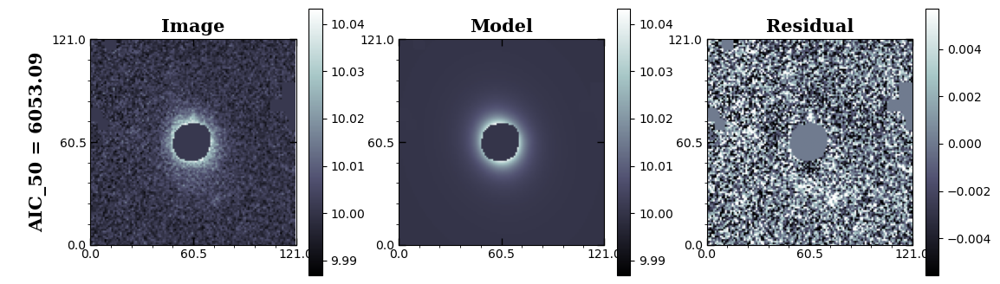

In [32]:
galid=4

ResGal=MC2_r_1comp_m.result(galid=galid, group_id=None)
ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=False) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]]
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]
print(fn)

MC2_r_1comp_m.drawing(galid=galid, fn=fn)
plt.show()
# MC2_r_1comp_m.drawing_legacy(galid=galid)


# 2-component fitting


The two-component stage builds on the single-Sérsic results.

The key idea is:

1. load the best or useful output from the one-component fit,
2. use those parameters as initial conditions,
3. add a second structural component, and
4. test whether the additional component improves the model.

This is where the workflow becomes more complex. The single-Sérsic output is no longer just a result; it becomes the starting point for the next model.

## Load the data

This cell restores an earlier `ResPack` object from disk. These are loaded from the saved one-component result packages.

This avoids manually typing initial guesses for every galaxy and makes the fitting procedure more reproducible.

It provides the starting parameters or model selection used by the following fitting stage. Confirm that the file belongs to the same target sample, directory ordering, and code version.


In [8]:
ResPack_g_1Comp=pickle.load(open(DIgood.dir_base+"ResPack_g_1Comp.pkl", "rb"))
ResPack_g_1Comp.preset_generate_onlyval(is_mag=False)

ResPack_g_1Comp_m=pickle.load(open(DIgood.dir_base+"ResPack_g_1Comp_m.pkl", "rb"))
ResPack_g_1Comp_m.preset_generate_onlyval(is_mag=False)

>> Get all submodels
>> Get all submodels


In [9]:
ResPack_r_1Comp=pickle.load(open(DIgood.dir_base+"ResPack_r_1Comp.pkl", "rb"))
ResPack_r_1Comp.preset_generate_onlyval(is_mag=False)

ResPack_r_1Comp_m=pickle.load(open(DIgood.dir_base+"ResPack_r_1Comp_m.pkl", "rb"))
ResPack_r_1Comp_m.preset_generate_onlyval(is_mag=False)

>> Get all submodels
>> Get all submodels


## Get Re - statistic radii

The best one-component Sérsic radius is used to define apertures for later model comparison. `rad_list()` replaces invalid or very small values with `minre`, preventing an unrealistically small fitting region.

We use the region within this radius as the region of interest for calculating the AICc and other statistical measures.

Subsequent post-processing can then evaluate AIC/AICc and related statistics within a consistent, galaxy-centered region rather than over every available image pixel.

`stat_radius_array_g` and `stat_radius_array_r` have values of \(1R_e\) and \(0.5R_e\) in each filter.

In [10]:
def rad_list(original_array, minre=40):
    usinglist=np.copy(original_array)
    usinglist[np.isnan(usinglist)]=minre
    usinglist[usinglist<minre]=minre # Prevent to small Re
    return usinglist

minre=20 ## Minimum effective radius

stat_item_name_array=['hRb', 'Rb'] ## Half R_e, R_e

# Base Sersic - r band (Based on AIC_50)
radius_list_base_g=rad_list(ResPack_g_1Comp.bob_onlyval['2_RE'], minre) 
radius_list_base_gw=rad_list(ResPack_g_1Comp.bobwarn_onlyval['2_RE'], minre) 
stat_radius_array_g=np.vstack((radius_list_base_g/2, radius_list_base_g,
                           )).T

radius_list_base_r=rad_list(ResPack_r_1Comp.bob_onlyval['2_RE'], minre) 
radius_list_base_rw=rad_list(ResPack_r_1Comp.bobwarn_onlyval['2_RE'], minre) 
stat_radius_array_r=np.vstack((radius_list_base_r/2, radius_list_base_r,
                           )).T

## g-band

### Setting

In [11]:
MC2_g_2comp=dhmc2fit.Setting(proj_folder='g_2comp/',           ## Folder name for this fit
                             fni_image = 'image_lg.fits',      ## image name (in DI.dir_work_list)
                             fni_sigma = 'sigma_lg.fits',      ## sigma name (in DI.dir_work_list)
                             fni_psf = 'psf_model_lg.fits',    ## psf name (in DI.dir_work_list)
                             fni_masking= 'masking_c_nb.fits', ## mask name (in DI.dir_work_list)
                             use_sky_grad=False,               ## Gradient Sky (False: Flat sky)
                             image_size = image_size,          ## Image size
                             plate_scale=plate_scale,          ## Plate scale
                             est_sky=est_sky,                  ## Estimated sky value 
                             Ncore=Ncore,                       ## Number of cores
                             stat_itemlist=['CHI2NU', 'RChi_F', 'AIC_F', 'LIK_F', 'RChi_50', 'AIC_50', 'LIK_50',
                                            'AIC_Rb', 'LIK_Rb', 'AIC_hRb', 'LIK_hRb' ## List of statistics within Re and 0.5 Re
                                           ],
                             comp_crit='AIC_Rb',
                             re_lim_list=psf_lim_g, ## PSF size
                          )


Setting completed


### Runlist

The Runlist now contains two galaxy components instead of one. The initial values are based on the previous one-component result, with additional variations for the second component.

This is important because multi-component GALFIT models are more sensitive to initial conditions than single-component models.

#### Double Sersic (group_id=1)

In [12]:
## Variation in their magnitude
mag_offset2 = np.arange(-3, 4, 3) ## mag variation for Comp2 (1st comp for the gal) ** Comp1 is the Sky
mag_offset3 = np.arange(-3, 4, 3) ## mag variation for Comp3 (2nd comp for the gal)
mag_offset3=mag_offset3[mag_offset3!=0]

## Make a name list. p is for positive, m is for negative. p3m3 means +3 and -3
mag_offset2_str = [f"p{abs(x)}" if x >= 0 else f"m{abs(x)}" for x in mag_offset2] 
mag_offset3_str = [f"p{abs(x)}" if x >= 0 else f"m{abs(x)}" for x in mag_offset3]

##===========================================
for i, this_offset2 in enumerate(mag_offset2):
    ## Double Sersic (Group 1)
    
    namelist=dharray.array_attach_string(mag_offset3_str, 'ss_fo_'+str(mag_offset2_str[i]), add_at_head=True)
    ## For the first part of the namelist, we will use the model components (here, ss is for double Sersic)
    ## For the second part, we will use the other configuration (f is for full image, o is for original)

    ## Estimated parameters are slightly different from the 1 comp case
    ## Here, I want to use the result of the 1 comp case as the initial guess. 
    ## Thus, I would like to input the "offset" value from the 1 comp case. Those values will be added to the previous fitting results.
    ## However, you can also 'replace' instead of 'add' by using base_params_add == False. See 'update_Class' later.
    est_params_array=np.array([[0, 0, this_offset2, 0, 0, 0, 0],  ## Comp2 (1st comp for the gal): This will be added --> All values = 0 except for est_mag.
                               [0, 0, mag_offset3, 10, 4, 0, 0],   ## Comp3 (2nd comp for the gal)
                              ],  
                              dtype='object') 
    # index                      [  0   |  1   |      2     |  3 | 4 |  5   |  6 ]
    # params                    [ xpos | ypos |     mag     |reff| n |  ar  |  pa]    
    # Nan means that we will use the default value as the initial guess for this parameter.
    # ** For position, we will use the center of the image as the initial guess.
    # ** Even we set to add offset to the 1st component result, if we set the value to Nan, Galfit will use the default value. 


    Runlist2Comp_Part_g1_raw=dhmc2fit.Runlist(namelist=namelist, complist=['sersic2','sersic2'], ## Input the name list and component list.
                                            est_params_array=est_params_array,                ## Initial guess
                                            group_id=1,                                       ## Fitting group. 
                                            size_conv=image_size,                                    ## Convolution box size    
                                            lim_pos=np.array([[51, 71], [51, 71]]),         ## Position constraint (from - to)
                                            lim_n=[[0, 10], [0.1, 10]],                       ## Sersic index constraint (from - to)  
                                            lim_reff=None,                                    ## Effective radii constraint
                                            lim_ar=[[0.2, 1.1], [0.3, 1.1]],                  ## Axis ratio constraint (from - to)
                                            )
    if(i==0): Runlist2Comp_Part_g1=copy.deepcopy(Runlist2Comp_Part_g1_raw)
    else: Runlist2Comp_Part_g1.add_runlist(Runlist2Comp_Part_g1_raw)
Runlist2Comp_Part_g1.show_runlist()

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,ss_fo_m3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
1,ss_fo_m3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
2,ss_fo_p0m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
3,ss_fo_p0p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
4,ss_fo_p3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
5,ss_fo_p3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1


#### Sersic+PSF (group_id=2)

In [13]:
## Variation in their magnitude
mag_offset2 = np.arange(-3, 4, 3) ## mag variation for Comp2 (1st comp for the gal) ** Comp1 is the Sky
mag_offset3 = np.arange(-3, 4, 3) ## mag variation for Comp3 (2nd comp for the gal)
mag_offset3=mag_offset3[mag_offset3!=0]

## Make a name list. p is for positive, m is for negative. p3m3 means +3 and -3
mag_offset2_str = [f"p{abs(x)}" if x >= 0 else f"m{abs(x)}" for x in mag_offset2] 
mag_offset3_str = [f"p{abs(x)}" if x >= 0 else f"m{abs(x)}" for x in mag_offset3]

##===========================================
for i, this_offset2 in enumerate(mag_offset2):
    ## Sersic + PSF (Group 2)
    namelist=dharray.array_attach_string(mag_offset3_str, 'sp_fo_'+str(mag_offset2_str[i]), add_at_head=True)
    est_params_array=np.array([[0, 0, this_offset2, 0, 0, 0, 0],  ## Comp2 (1st comp for the gal): This will be added --> All values = 0 except for est_mag.
                               [0, 0, mag_offset3, 10, 4, 0, 0],   ## Comp3 (2nd comp for the gal)
                              ],  
                              dtype='object') 
        
    Runlist2Comp_Part_g2_raw=dhmc2fit.Runlist(namelist=namelist, complist=['sersic2','psf'],     ## Input the name list and component list.
                                            est_params_array=est_params_array,                ## Initial guess
                                            group_id=2,                                       ## Fitting group. 
                                            size_conv=image_size,                                    ## Convolution box size    
                                            lim_pos=np.array([[51, 71], [51, 71]]),         ## Position constraint (from - to)
                                            lim_n=[[0, 10], [0.1, 10]],                       ## Sersic index constraint (from - to)  
                                            lim_reff=None,                                    ## Effective radii constraint
                                            lim_ar=[[0.2, 1.1], [0.3, 1.1]],                  ## Axis ratio constraint (from - to)
                                            )
    ## I copied the previous Runlist setting.
    ## For PSF component, initial sersic index, ar will be considered as NaN.

    if(i==0): Runlist2Comp_Part_g2=copy.deepcopy(Runlist2Comp_Part_g2_raw)
    else: Runlist2Comp_Part_g2.add_runlist(Runlist2Comp_Part_g2_raw)
  
Runlist2Comp_Part_g2.show_runlist()

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,sp_fo_m3m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
1,sp_fo_m3p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
2,sp_fo_p0m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
3,sp_fo_p0p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
4,sp_fo_p3m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","3.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
5,sp_fo_p3p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","3.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2


#### Single PSF (group_id=3)

In [14]:
mag_offset2 = np.arange(-3, 4, 3) ## mag variation for Comp2 (1st comp for the gal) ** Comp1 is the Sky
mag_offset2_str = [f"p{abs(x)}" if x >= 0 else f"m{abs(x)}" for x in mag_offset2] 


namelist=dharray.array_attach_string(mag_offset2_str, 'p_fo_', add_at_head=True)
est_params_array=np.array([[0, 0, this_offset2, 0, 0, 0, 0],  ## Comp2 (1st comp for the gal): This will be added --> All values = 0 except for est_mag.
                          ],  
                          dtype='object') 
Runlist2Comp_Part_g3=dhmc2fit.Runlist(namelist=namelist, complist=['psf'],
                                        est_params_array=est_params_array,
                                        group_id=3, 
                                        size_conv=image_size,                                    ## Convolution box size    
                                        lim_pos=np.array([[51, 71], [51, 71]]),         ## Position constraint (from - to)
                                        lim_n=[[0, 10], [0.1, 10]],                       ## Sersic index constraint (from - to)  
                                        lim_reff=None,                                    ## Effective radii constraint
                                        lim_ar=[[0.2, 1.1], [0.3, 1.1]],                  ## Axis ratio constraint (from - to)
                                        )
## I copied the previous Runlist setting.
## For PSF component, initial sersic index, ar will be considered as NaN.

Runlist2Comp_Part_g3.show_runlist()

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,p_fo_m3,[psf],1,0.0,0.0,3.0,0.0,0.0,0.0,0.0,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 10.0),(0.2 1.1),(nan nan),True,3
1,p_fo_p0,[psf],1,0.0,0.0,3.0,0.0,0.0,0.0,0.0,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 10.0),(0.2 1.1),(nan nan),True,3
2,p_fo_p3,[psf],1,0.0,0.0,3.0,0.0,0.0,0.0,0.0,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 10.0),(0.2 1.1),(nan nan),True,3


#### Single Sersic (group_id=0)

In [15]:
mag_offset2 = np.arange(-3, 4, 3) ## mag variation for Comp2 (1st comp for the gal) ** Comp1 is the Sky
mag_offset2_str = [f"p{abs(x)}" if x >= 0 else f"m{abs(x)}" for x in mag_offset2] 


namelist=dharray.array_attach_string(mag_offset2_str, 's_fo_', add_at_head=True)
est_params_array=np.array([[0, 0, this_offset2, 0, 0, 0, 0],  ## Comp2 (1st comp for the gal): This will be added --> All values = 0 except for est_mag.
                          ],  
                          dtype='object') 
Runlist2Comp_Part_g0=dhmc2fit.Runlist(namelist=namelist, complist=['sersic2'],
                                        est_params_array=est_params_array,
                                        group_id=0, 
                                        size_conv=image_size,                                    ## Convolution box size    
                                        lim_pos=np.array([[51, 71], [51, 71]]),         ## Position constraint (from - to)
                                        lim_n=[[0, 10], [0.1, 10]],                       ## Sersic index constraint (from - to)  
                                        lim_reff=None,                                    ## Effective radii constraint
                                        lim_ar=[[0.2, 1.1], [0.3, 1.1]],                  ## Axis ratio constraint (from - to)
                                        )
## I copied the previous Runlist setting.
## For PSF component, initial sersic index, ar will be considered as NaN.

Runlist2Comp_Part_g0.show_runlist()

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,s_fo_m3,[sersic2],1,0.0,0.0,3.0,0.0,0.0,0.0,0.0,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 10.0),(0.2 1.1),(nan nan),True,0
1,s_fo_p0,[sersic2],1,0.0,0.0,3.0,0.0,0.0,0.0,0.0,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 10.0),(0.2 1.1),(nan nan),True,0
2,s_fo_p3,[sersic2],1,0.0,0.0,3.0,0.0,0.0,0.0,0.0,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 10.0),(0.2 1.1),(nan nan),True,0


#### Combine all

In [16]:
Runlist2Comp = copy.deepcopy(Runlist2Comp_Part_g1)
Runlist2Comp.add_runlist(Runlist2Comp_Part_g2)
Runlist2Comp.add_runlist(Runlist2Comp_Part_g3)
Runlist2Comp.add_runlist(Runlist2Comp_Part_g0)
Runlist2Comp.show_runlist()

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,ss_fo_m3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
1,ss_fo_m3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
2,ss_fo_p0m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
3,ss_fo_p0p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
4,ss_fo_p3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
5,ss_fo_p3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
6,sp_fo_m3m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
7,sp_fo_m3p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
8,sp_fo_p0m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
9,sp_fo_p0p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2


### Use the one-component result as the initial condition

`ResPack.params_array` has the shape of

```text
(number of targets, number of galaxy components, 7 parameters)
```

For the two-component run, the first galaxy component inherits the one-component solution. The second component is initialized from a copy of that solution plus the offsets defined in the Runlist.

`base_params_array_set` supplies a different base parameter array for every target. `base_params_add` controls the combination parameter by parameter:

- `True`: Runlist value is added to the base value.
- `False`: Runlist value is replaced by the supplied base value.

This distinction is especially important for fixed positions or fixed Sérsic indices.

In [26]:
## First copy the result of the 1 component
## For the galfit, 'est_params_array' we set above will be added to the previous result (PrevRes)
PrevRes=copy.deepcopy(ResPack_g_1Comp.params_array) # previous result. Shape: (N_Target(DI), Comp, item (7) )
PrevRes

array([[[ 57.7425,  58.2167,  22.5425, ...,   3.2915,   0.6242,
          35.4076],
        [     nan,      nan,      nan, ...,      nan,      nan,
              nan]],

       [[ 62.2928,  62.0155,  23.0185, ...,   6.0995,   0.4517,
         -88.9577],
        [     nan,      nan,      nan, ...,      nan,      nan,
              nan]],

       [[ 60.0385,  61.3511,  27.2622, ...,  15.336 ,   0.7187,
          60.8934],
        [     nan,      nan,      nan, ...,      nan,      nan,
              nan]],

       ...,

       [[ 61.8176,  59.9963,  21.1764, ...,   0.9397,   0.4663,
         -66.175 ],
        [     nan,      nan,      nan, ...,      nan,      nan,
              nan]],

       [[ 61.0353,  54.1125,  20.7419, ...,  30.    ,   0.7903,
          30.1978],
        [     nan,      nan,      nan, ...,      nan,      nan,
              nan]],

       [[ 71.    ,  51.    ,  24.134 , ...,   0.7425,   0.9251,
         -13.9312],
        [     nan,      nan,      nan, ...,      nan,

In [27]:
## We will not change the parameter for the 1st component (Comp2) // Comp1 : Sky
## PrevRes[:,0,:] 

## For 2nd component (Comp3), we will copy the 1st component mags as the initial guess
PrevRes[:,1,:]=np.nan # Reset all the parameters for Comp3 (2nd comp for the gal)
PrevRes[:,1,0]=np.nan # By using Nan for the position, the position will be set to the center of the image
PrevRes[:,1,1]=np.nan # By using Nan for the position, the position will be set to the center of the image
PrevRes[:,1,2]=PrevRes[:,0,2] # Copy the mag
PrevRes[:,1,3] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes[:,1,4] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes[:,1,5:] = np.nan # Set the other values as Nan (default value)

In [28]:
# Attach the two-component Runlist and the per-target one-component starting parameters.
MC2_g_2comp.update_Class(Runlist2Comp, DIgood, 
                         base_params_array_set=PrevRes,  # one base parameter array per target
                         base_params_add=True,            # Runlist values are offsets from PrevRes
                        )

### Optional - Add alternative starting points from detected sources

Some galaxies may have bright off-center clumps, nuclei, or nearby structures that can be useful starting positions for an additional component.

This section searches for detected bright sources and uses their positions as alternative initial guesses. This helps the two-component model explore more possible solutions.

In [29]:
# Search settings for an optional off-center starting position.
# Distances and box sizes are in image pixels.
min_dist = 5 ## minimum offset from the center
box_halfsize = 20 ## Box size from the center. Search size.

In [30]:
# Select the brightest detected source near—but not at—the image center.
# A target remains NaN when no suitable source is available; that target is skipped later.
img_center = image_size/2
min_loc = img_center-box_halfsize
max_loc = img_center+box_halfsize

## Find out the detected bright sources in the image --> Use their location as a new starting point
objpos=np.full((len(DIgood.dir_work_list), 2), np.nan)
for i in range (len(DIgood.dir_work_list)):
    if(i%1000==0): print(i)
    objdat=np.load(DIgood.dir_work_list[i]+'maskobj_r_d.npy') ## Masked object data (we will use the center of the object)

    try:
        objdat=objdat[(objdat['x']>min_loc) & (objdat['y']>min_loc) 
                    & (objdat['x']<max_loc) & (objdat['y']<max_loc)]  ## Within the position limit
        dist=((objdat['x']-image_size/2)**2+(objdat['y']-image_size/2)**2)**0.5
        objdat=objdat[dist>min_dist] ## separation from the center larget than 5 pixels
        
        thisobj=objdat[objdat['flux']==np.nanmax(objdat['flux'])][0] ## select the brightest object
        objpos[i]=thisobj['x'], thisobj['y']
    except: pass
objpos

0


array([[56.85461436, 56.55784087],
       [70.99937324, 42.37238172],
       [        nan,         nan],
       [        nan,         nan],
       [        nan,         nan],
       [69.04650196, 56.71895081],
       [        nan,         nan],
       [        nan,         nan],
       [        nan,         nan],
       [        nan,         nan],
       [        nan,         nan],
       [        nan,         nan],
       [        nan,         nan],
       [        nan,         nan],
       [78.51590697, 58.22723004],
       [        nan,         nan],
       [        nan,         nan],
       [        nan,         nan],
       [        nan,         nan],
       [        nan,         nan],
       [        nan,         nan],
       [        nan,         nan],
       [        nan,         nan],
       [        nan,         nan],
       [        nan,         nan],
       [        nan,         nan],
       [        nan,         nan],
       [        nan,         nan],
       [        nan,

In [31]:
# Duplicate the standard Runlist and change only the run names.
# The names identify the alternative-position trials; they do not affect GALFIT.
## Here I make a copy of the original Runlist
## The new version will be used for the new initial guess for the 2nd component
Runlist2Comp_pos=copy.deepcopy(Runlist2Comp) ## new position
for i, text in enumerate(Runlist2Comp_pos.runlist['name']):
    newtext=text.split("_")
    newtext[1]=newtext[1][:1]+'p'+newtext[1][2:]  ## use 'p' for new positions
    Runlist2Comp_pos.runlist['name'][i]='_'.join(newtext)
Runlist2Comp_pos.show_runlist()

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,ss_fp_m3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
1,ss_fp_m3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
2,ss_fp_p0m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
3,ss_fp_p0p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
4,ss_fp_p3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
5,ss_fp_p3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
6,sp_fp_m3m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
7,sp_fp_m3p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
8,sp_fp_p0m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
9,sp_fp_p0p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2


In [32]:
# Replace the second component's initial x/y position with the detected source position.
# skiplist prevents GALFIT from running when no valid alternative position was found.
PrevRes_objpos=copy.deepcopy(PrevRes) # Copy the previous setting
for i in range(len(PrevRes_objpos)):
    PrevRes_objpos[i,1,0]=objpos[i,0] # Update the X position instead of Nan
    PrevRes_objpos[i,1,1]=objpos[i,1] # Update the Y position instead of Nan

## Make a new Setting class
MC2_g_2comp_pos=copy.deepcopy(MC2_g_2comp)
MC2_g_2comp_pos.update_Class(Runlist2Comp_pos, DIgood, 
                             base_params_array_set=PrevRes_objpos,  # one base parameter array per target
                             base_params_add=True,            # Runlist values are offsets from PrevRes
                             skiplist=np.isnan(PrevRes_objpos[:,1,0]), ## skip when newpos == Nan
                            )


In [33]:
## Stack all the Runlists
Runlist2Comp_all=copy.deepcopy(Runlist2Comp)
Runlist2Comp_all.add_runlist(Runlist2Comp_pos)
Runlist2Comp_all.show_runlist()

## Make a combined Setting class
MC2_g_2comp_all=copy.deepcopy(MC2_g_2comp)
MC2_g_2comp_all.update_Class(Runlist2Comp_all, DIgood)

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,ss_fo_m3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
1,ss_fo_m3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
2,ss_fo_p0m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
3,ss_fo_p0p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
4,ss_fo_p3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
5,ss_fo_p3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
6,sp_fo_m3m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
7,sp_fo_m3p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
8,sp_fo_p0m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
9,sp_fo_p0p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2


### Galfit Run, extract, post process

The normal-center and alternative-position trials use different per-target `base_params_array_set` values, so they are executed as separate Setting objects. 

After both runs finish, a combined Setting (MC2_g_2comp_all) can be used for extraction, post-processing, and result packing because those steps only need the filenames and model definitions.


In [34]:
## Run galfit separately
MC2_g_2comp_pos.run()

## Run galfit
MC2_g_2comp.run()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 126.9 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 731.9 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



The extraction and post processing do not linked with the base_params_array_set. We could use the combined setting.

In [35]:
## For the rest of the part, use the combined setting.
## If you did not use MC2_g_2comp_pos, use MC2_g_2comp instead of MC2_g_2comp_all
MC2_g_2comp_all.extract()
MC2_g_2comp_all.postprocessing()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 11.7 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



Remove files:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.1 s
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

/home/donghyeon/ua/core_code/DH_MC2fit.py:1863: RuntimeWarning: All-NaN slice encountered
  min_stat=np.nanmin(statlist[usingindex])
/home/donghyeon/ua/core_code/DH_MC2fit.py:1863: RuntimeWarning: All-NaN slice encountered
  min_stat=np.nanmin(statlist[usingindex])
/home/donghyeon/ua/core_code/DH_MC2fit.py:1863: RuntimeWarning: All-NaN slice encountered
  min_stat=np.nanmin(statlist[usingindex])
/home/donghyeon/ua/core_code/DH_MC2fit.py:1863: RuntimeWarning: All-NaN slice encountered
  min_stat=np.nanmin(statlist[usingindex])
/home/donghyeon/ua/core_code/DH_MC2fit.py:1863: RuntimeWarning: All-NaN slice encountered
  min_stat=np.nanmin(statlist[usingindex])
/home/donghyeon/ua/core_code/DH_MC2fit.py:1863: RuntimeWarning: All-NaN slice encountered
  min_stat=np.nanmin(statlist[usingindex])
/home/donghyeon/ua/core_code/DH_MC2fit.py:1863: RuntimeWarning: All-NaN slice encountered
  min_stat=np.nanmin(statlist[usingindex])
/home/donghyeon/ua/core_code/DH_MC2fit.py:1863: RuntimeWarning: All-N

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0226/g_2comp/result_ss_fo_m3m3.fits
>> Warning! No safe_itemlist!


/home/donghyeon/ua/core_code/DH_MC2fit.py:1863: RuntimeWarning: All-NaN slice encountered
  min_stat=np.nanmin(statlist[usingindex])
/home/donghyeon/ua/core_code/DH_MC2fit.py:1863: RuntimeWarning: All-NaN slice encountered
  min_stat=np.nanmin(statlist[usingindex])
/home/donghyeon/ua/core_code/DH_MC2fit.py:1863: RuntimeWarning: All-NaN slice encountered
  min_stat=np.nanmin(statlist[usingindex])
/home/donghyeon/ua/core_code/DH_MC2fit.py:1863: RuntimeWarning: All-NaN slice encountered
  min_stat=np.nanmin(statlist[usingindex])
/home/donghyeon/ua/core_code/DH_MC2fit.py:1863: RuntimeWarning: All-NaN slice encountered
  min_stat=np.nanmin(statlist[usingindex])
/home/donghyeon/ua/core_code/DH_MC2fit.py:1863: RuntimeWarning: All-NaN slice encountered
  min_stat=np.nanmin(statlist[usingindex])
/home/donghyeon/ua/core_code/DH_MC2fit.py:1863: RuntimeWarning: All-NaN slice encountered
  min_stat=np.nanmin(statlist[usingindex])
/home/donghyeon/ua/core_code/DH_MC2fit.py:1863: RuntimeWarning: All-N

Done! | Time: 11.6 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



Here we add the statistic measurement within the given area (1 and 0.5 effective radii)

### Calculate AIC within Re and 0.5Re

In [36]:
MC2_g_2comp_all.postprocessing(stat_radius_array_set=stat_radius_array_g,
                           stat_item_namelist=stat_item_name_array) ## additional Stat regions

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0226/g_2comp/result_ss_fo_m3m3.fits
>> Warning! No safe_itemlist!
Done! | Time: 11.5 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



(optional) We can calculate the values for 1 comp fittings.

In [37]:
## Post processing for 1comp model
MC2_g_1comp.postprocessing(stat_radius_array_set=stat_radius_array_g,
                           stat_item_namelist=stat_item_name_array) ## additional Stat regions

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 6.0 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



### Pack

In [38]:
ResPack_g_2Comp=MC2_g_2comp_all.pack_result()
pickle.dump(ResPack_g_2Comp, open(DIgood.dir_base+"ResPack_g_2Comp.pkl", "wb"))
ResPack_g_2Comp=pickle.load(open(DIgood.dir_base+"ResPack_g_2Comp.pkl", "rb"))
ResPack_g_2Comp.preset_generate_onlyval(is_mag=False)

Pack the results
>> comp_crit: AIC_Rb
>> backend: thread
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0226/g_2comp/result_ss_fo_m3m3.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
Done! | Time: 4.9 s
>> Get all submodels


### Result

,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
ss_fo_m3m3,1.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
ss_fo_m3p3,1.000000,0.000000,61.835600,61.338500,24.854500,15.268100,10.000000,18.603000,51.000000,51.000000,124.969700,2.420000,10.000000,123.391900,8.372446,8.372447,116289.827397,0.000000,14.572959,112037.823774,0.000000,106503.562076,0.000000,101695.139910,0.000000
ss_fo_p0m3,1.000000,0.000000,62.035600,61.456300,26.582400,6.159900,10.000000,22.872000,62.101400,61.395700,24.823200,4.580100,10.000000,21.028500,0.726982,0.726982,10124.902436,1.000000,0.776205,5995.971656,1.000000,1330.378576,0.123175,546.252002,0.000000
ss_fo_p0p3,1.000000,0.000000,62.088100,61.408100,27.643000,17.099800,10.000000,21.000900,60.500000,60.500000,30.643000,10.000000,4.000000,25.163100,0.722050,0.839961,11693.734400,1.000000,0.980068,7562.868939,0.892237,2906.318769,0.000000,2120.622487,0.000000
ss_fo_p3m3,1.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
ss_fo_p3p3,1.000000,0.000000,62.112200,61.395900,27.456400,16.270900,10.000000,21.398800,62.065200,61.409900,27.471300,14.874200,10.000000,21.364100,0.762418,0.762418,10616.964587,1.000000,0.839834,6485.028951,1.000000,1817.917109,0.000000,1012.211648,0.000000
sp_fo_m3m3,2.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
sp_fo_m3p3,2.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
sp_fo_p0m3,2.000000,0.000000,62.088100,61.408100,27.643000,17.099800,10.000000,21.000900,60.500000,60.500000,nan,nan,nan,24.643000,0.720843,0.821895,11438.141165,1.000000,0.947376,7307.357726,0.999545,2650.807711,0.000000,1866.819290,0.000000
sp_fo_p0p3,2.000000,0.000000,62.088100,61.408100,27.643000,17.099800,10.000000,21.000900,60.500000,60.500000,nan,nan,nan,30.643000,0.721257,0.842774,11728.145823,1.000000,0.985088,7597.362385,0.822233,2940.813099,0.000000,2157.327804,0.000000


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
s_fo_m3,0.000000,0.000000,62.090900,61.401800,27.204200,17.248800,10.000000,0.712300,67.958700,20.422800,nan,nan,nan,nan,nan,nan,nan,nan,0.761490,0.761490,10595.387334,1.000000,0.837563,6459.390277,1.000000,1787.827352,0.000000,957.047633,0.000000
ss_fo_p0m3,1.000000,0.000000,62.035600,61.456300,26.582400,6.159900,10.000000,0.330100,-44.195800,22.872000,62.101400,61.395700,24.823200,4.580100,10.000000,0.645300,61.053100,21.028500,0.726982,0.726982,10124.902436,1.000000,0.776205,5995.971656,1.000000,1330.378576,0.123175,546.252002,0.000000
sp_fo_p0m3,2.000000,0.000000,62.088100,61.408100,27.643000,17.099800,10.000000,0.637500,61.951400,21.000900,60.500000,60.500000,nan,nan,nan,nan,nan,24.643000,0.720843,0.821895,11438.141165,1.000000,0.947376,7307.357726,0.999545,2650.807711,0.000000,1866.819290,0.000000
p_fo_m3,3.000000,0.000000,62.095400,61.429000,nan,nan,nan,nan,nan,21.565500,nan,nan,nan,nan,nan,nan,nan,nan,0.701318,0.701318,9754.218790,1.000000,0.729571,5623.512610,1.000000,965.377815,1.000000,222.195383,0.999996


./gal_out/gal0004/g_2comp/result_p_fo_m3.fits


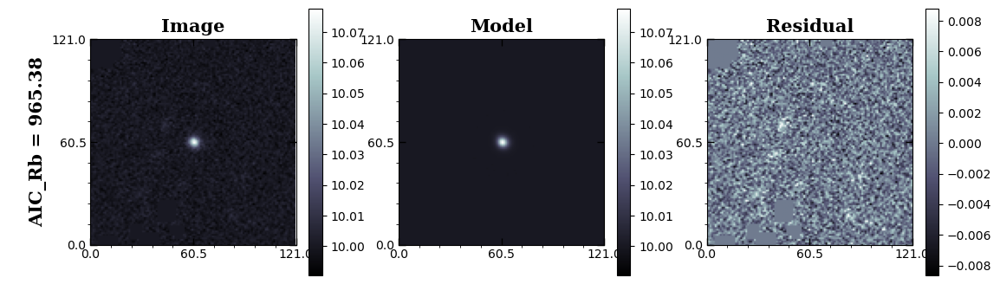

In [69]:
galid=4

ResGal=MC2_g_2comp_all.result(galid=galid, group_id=None)
ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=False) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]] ## avoid warning results if possible 
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]  ## Best results regardlenss of warning
print(fn)

MC2_g_2comp_all.drawing(galid=galid, fn=fn)
plt.show()
# MC2_g_2comp_all.drawing_legacy(galid=galid)

## g-band from 1comp-central masking

This section repeats the two-component fitting, but uses the one-component central-mask result as the initial condition source.

This tests whether the multi-component solution depends strongly on how the initial single-Sérsic model was obtained.


In [42]:
MC2_g_2comp_m=copy.deepcopy(MC2_g_2comp)
## Even though the first run was based on the central masking,
## The second one will not use the central masking to fit the central bright source.

MC2_g_2comp_m.class_update_keys(proj_folder='g_2comp_m/')

In [43]:
## Copy the result of the 1 component
PrevRes_m=copy.deepcopy(ResPack_g_1Comp_m.params_array) # previous result. Shape: (N_Target(DI), Comp, item (7) )

## We will not change the parameter for the 1st component (Comp2) // Comp1 : Sky
## PrevRes[:,0,:] 

## For 2nd component (Comp3), we will copy the 1st component mags as the initial guess
PrevRes_m[:,1,:]=np.nan # Reset all the parameters for Comp3 (2nd comp for the gal)
PrevRes_m[:,1,0]=np.nan # By using Nan for the position, the position will be set to the center of the image
PrevRes_m[:,1,1]=np.nan # By using Nan for the position, the position will be set to the center of the image
PrevRes_m[:,1,2]=PrevRes_m[:,0,2] # Copy the mag
PrevRes_m[:,1,3] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_m[:,1,4] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_m[:,1,5:] = np.nan # Set the other values as Nan (default value)

In [44]:
Runlist2Comp_m=copy.deepcopy(MC2_g_2comp.RunlistClass)  # Copy the Runlist class 
for i, text in enumerate(Runlist2Comp_m.runlist['name']):
    newtext=text.split("_")
    newtext[1]="m"+newtext[1][1:]   ## As an example, I used 'm' for 'masking' instead of 'f' (full)
    Runlist2Comp_m.runlist['name'][i]='_'.join(newtext)
Runlist2Comp_m.show_runlist()

## For the Setting class, update the Runlist, Directory information, and initial guesses
MC2_g_2comp_m.update_Class(Runlist2Comp_m, DIgood, 
                             base_params_array_set=PrevRes_objpos,  # one base parameter array per target
                             base_params_add=True,            # Runlist values are offsets from PrevRes
                        )

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,ss_mo_m3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
1,ss_mo_m3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
2,ss_mo_p0m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
3,ss_mo_p0p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
4,ss_mo_p3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
5,ss_mo_p3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
6,sp_mo_m3m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
7,sp_mo_m3p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
8,sp_mo_p0m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
9,sp_mo_p0p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2


In [45]:
### Optional - alternative starting points

Runlist2Comp_m_pos=copy.deepcopy(Runlist2Comp_m) ## new position
for i, text in enumerate(Runlist2Comp_m_pos.runlist['name']):
    newtext=text.split("_")
    newtext[1]=newtext[1][:1]+'p'+newtext[1][2:]  ## use 'p' for new positions
    Runlist2Comp_m_pos.runlist['name'][i]='_'.join(newtext)
Runlist2Comp_m_pos.show_runlist()

PrevRes_objpos_m=copy.deepcopy(PrevRes_m) # Copy the previous setting
for i in range(len(PrevRes_objpos)):
    PrevRes_objpos_m[i,1,0]=objpos[i,0] # Update the X position instead of Nan
    PrevRes_objpos_m[i,1,1]=objpos[i,1] # Update the Y position instead of Nan


## Make a new Setting class
MC2_g_2comp_m_pos=copy.deepcopy(MC2_g_2comp_m)
MC2_g_2comp_m_pos.update_Class(Runlist2Comp_m_pos, DIgood, 
                             base_params_array_set=PrevRes_objpos_m,  # one base parameter array per target
                             base_params_add=True,            # Runlist values are offsets from PrevRes
                             skiplist=np.isnan(PrevRes_objpos_m[:,1,0]), ## skip when newpos == Nan
                                  )

## Stack all the Runlists
Runlist2Comp_m_all=copy.deepcopy(Runlist2Comp_m)
Runlist2Comp_m_all.add_runlist(Runlist2Comp_m_pos)
Runlist2Comp_m_all.show_runlist()

## Make a combined Setting class
MC2_g_2comp_m_all=copy.deepcopy(MC2_g_2comp_m)
MC2_g_2comp_m_all.update_Class(Runlist2Comp_m_all, DIgood)

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,ss_mp_m3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
1,ss_mp_m3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
2,ss_mp_p0m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
3,ss_mp_p0p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
4,ss_mp_p3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
5,ss_mp_p3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
6,sp_mp_m3m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
7,sp_mp_m3p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
8,sp_mp_p0m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
9,sp_mp_p0p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2


,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,ss_mo_m3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
1,ss_mo_m3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
2,ss_mo_p0m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
3,ss_mo_p0p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
4,ss_mo_p3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
5,ss_mo_p3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
6,sp_mo_m3m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
7,sp_mo_m3p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
8,sp_mo_p0m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
9,sp_mo_p0p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2


In [46]:
## Run galfit separately
MC2_g_2comp_m_pos.run()

## Run galfit
MC2_g_2comp_m.run()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 148.0 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 799.6 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



In [47]:
## For the rest of the part, use the combined one
MC2_g_2comp_m_all.extract()
MC2_g_2comp_m_all.postprocessing()
MC2_g_2comp_m_all.postprocessing(stat_radius_array_set=stat_radius_array_g,
                           stat_item_namelist=stat_item_name_array) ## additional Stat regions

ResPack_g_2Comp_m=MC2_g_2comp_m_all.pack_result()
pickle.dump(ResPack_g_2Comp_m, open(DIgood.dir_base+"ResPack_g_2Comp_m.pkl", "wb"))
ResPack_g_2Comp_m=pickle.load(open(DIgood.dir_base+"ResPack_g_2Comp_m.pkl", "rb"))
ResPack_g_2Comp_m.preset_generate_onlyval(is_mag=False)

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 11.6 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



Remove files:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.1 s
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

... (5 outputs left out)

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0226/g_2comp_m/result_ss_mo_m3m3.fits
>> Warning! No safe_itemlist!
Done! | Time: 14.2 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

Pack the results
>> comp_crit: AIC_Rb
>> backend: thread
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

/home/donghyeon/ua/core_code/DH_MC2fit.py:4564: RuntimeWarning: All-NaN slice encountered
  self.war_tot=np.nanmax(imsidat, axis=1)


>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0226/g_2comp_m/result_ss_mo_m3m3.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
Done! | Time: 6.0 s
>> Get all submodels


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
s_mo_m3,0.000000,0.000000,62.092300,61.399000,28.300100,33.101100,10.000000,0.696100,66.895500,20.128300,nan,nan,nan,nan,nan,nan,nan,nan,0.781528,0.781528,10873.778263,1.000000,0.873038,6732.303544,1.000000,2056.984257,0.000000,1194.596797,0.000000
ss_mo_p0m3,1.000000,0.000000,62.111600,61.403000,27.529800,10.097600,10.000000,0.318400,52.555200,22.785300,62.085700,61.404600,25.538400,5.754600,10.000000,0.892900,-86.317200,20.895400,0.734167,0.734167,10224.677537,1.000000,0.788985,6094.204606,1.000000,1427.459263,0.001333,629.672933,0.000000
sp_mo_p3m3,2.000000,0.000000,59.393100,60.620200,30.588600,44.143400,9.903600,0.200000,58.314100,23.150900,62.156500,61.460800,nan,nan,nan,nan,nan,21.602900,0.701118,0.701118,9760.544361,1.000000,0.729404,5631.154193,1.000000,974.351458,1.000000,232.666304,0.999994
p_mo_m3,3.000000,0.000000,62.095400,61.429000,nan,nan,nan,nan,nan,21.565500,nan,nan,nan,nan,nan,nan,nan,nan,0.701318,0.701318,9754.218437,1.000000,0.729571,5623.512256,1.000000,965.375620,1.000000,222.192781,0.999996


./gal_out/gal0004/g_2comp_m/result_p_mo_m3.fits


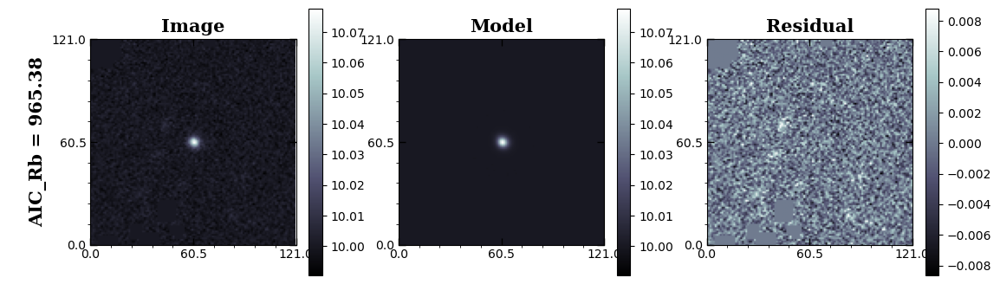

In [48]:
galid=4

ResGal=MC2_g_2comp_m_all.result(galid=galid, group_id=None)
#ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=True) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]]
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]
print(fn)

MC2_g_2comp_m_all.drawing(galid=galid, fn=fn)
plt.show()
# MC2_g_2comp_m_all.drawing_legacy(galid=galid)

## g-band total - Combine all g-band two-component trials

This section does **not** rerun GALFIT. It builds a combined Runlist and creates symbolic links to results produced in the separate unmasked and central-mask branches. The combined Setting can then compare all trials through one `ResPack`.

Run this section only after the source model families have been extracted and post-processed.

In [49]:
MC2_g_2comp_t=copy.deepcopy(MC2_g_2comp_all)
MC2_g_2comp_t.class_update_keys(proj_folder='g_2comp_t/')

## Combine all Runlists
Runlist2Comp_tot = copy.deepcopy(MC2_g_2comp_all.RunlistClass)
Runlist2Comp_tot.add_runlist(MC2_g_2comp_m_all.RunlistClass)
MC2_g_2comp_t.update_Class(Runlist2Comp_tot, DIgood)
Runlist2Comp_tot.show_runlist()

## Copy the data to the new folder by using symbolic links
res = dhfc.multicore_generate_link_galfit(DIgood, MC2_g_2comp_all, MC2_g_2comp_t)
res = dhfc.multicore_generate_link_galfit(DIgood, MC2_g_2comp_m_all, MC2_g_2comp_t)

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,ss_fo_m3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
1,ss_fo_m3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
2,ss_fo_p0m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
3,ss_fo_p0p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
4,ss_fo_p3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
5,ss_fo_p3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
6,sp_fo_m3m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
7,sp_fo_m3p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
8,sp_fo_p0m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
9,sp_fo_p0p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2


Generate GALFIT links:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.1 s
Links created: 2829
Missing source files: 1041


Generate GALFIT links:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.1 s
Links created: 3241
Missing source files: 4499


In [50]:
## Pack the results
ResPack_g_2Comp_t=MC2_g_2comp_t.pack_result()
pickle.dump(ResPack_g_2Comp_t, open(DIgood.dir_base+"ResPack_g_2Comp_t.pkl", "wb"))
ResPack_g_2Comp_t=pickle.load(open(DIgood.dir_base+"ResPack_g_2Comp_t.pkl", "rb"))
ResPack_g_2Comp_t.preset_generate_onlyval(is_mag=False)

Pack the results
>> comp_crit: AIC_Rb
>> backend: thread
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0226/g_2comp_t/result_ss_fo_m3m3.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
Done! | Time: 10.4 s
>> Get all submodels


In [19]:
galid=11

ResGal=MC2_g_2comp_t.result(galid=galid, group_id=None)
ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=False) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]] ## avoid warning results if possible 
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]  ## Best results regardlenss of warning
print(fn)

MC2_g_2comp_t.drawing(galid=galid, fn=fn)
plt.show()
# MC2_g_2comp_t.drawing_legacy(galid=galid)

NameError: name 'MC2_g_2comp_t' is not defined

,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
ss_fo_m3m3,1.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
ss_fo_m3p3,1.000000,0.000000,61.835600,61.338500,24.854500,15.268100,10.000000,18.603000,51.000000,51.000000,124.969700,2.420000,10.000000,123.391900,8.372446,8.372447,116289.827397,0.000000,14.572959,112037.823774,0.000000,106503.562076,0.000000,101695.139910,0.000000
ss_fo_p0m3,1.000000,0.000000,62.035600,61.456300,26.582400,6.159900,10.000000,22.872000,62.101400,61.395700,24.823200,4.580100,10.000000,21.028500,0.726982,0.726982,10124.902436,1.000000,0.776205,5995.971656,1.000000,1330.378576,0.123175,546.252002,0.000000
ss_fo_p0p3,1.000000,0.000000,62.088100,61.408100,27.643000,17.099800,10.000000,21.000900,60.500000,60.500000,30.643000,10.000000,4.000000,25.163100,0.722050,0.839961,11693.734400,1.000000,0.980068,7562.868939,0.892237,2906.318769,0.000000,2120.622487,0.000000
ss_fo_p3m3,1.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
ss_fo_p3p3,1.000000,0.000000,62.112200,61.395900,27.456400,16.270900,10.000000,21.398800,62.065200,61.409900,27.471300,14.874200,10.000000,21.364100,0.762418,0.762418,10616.964587,1.000000,0.839834,6485.028951,1.000000,1817.917109,0.000000,1012.211648,0.000000
sp_fo_m3m3,2.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
sp_fo_m3p3,2.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
sp_fo_p0m3,2.000000,0.000000,62.088100,61.408100,27.643000,17.099800,10.000000,21.000900,60.500000,60.500000,nan,nan,nan,24.643000,0.720843,0.821895,11438.141165,1.000000,0.947376,7307.357726,0.999545,2650.807711,0.000000,1866.819290,0.000000
sp_fo_p0p3,2.000000,0.000000,62.088100,61.408100,27.643000,17.099800,10.000000,21.000900,60.500000,60.500000,nan,nan,nan,30.643000,0.721257,0.842774,11728.145823,1.000000,0.985088,7597.362385,0.822233,2940.813099,0.000000,2157.327804,0.000000


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
s_fo_m3,0.000000,0.000000,62.090900,61.401800,27.204200,17.248800,10.000000,0.712300,67.958700,20.422800,nan,nan,nan,nan,nan,nan,nan,nan,0.761490,0.761490,10595.387334,1.000000,0.837563,6459.390277,1.000000,1787.827352,0.000000,957.047633,0.000000
ss_fo_p0m3,1.000000,0.000000,62.035600,61.456300,26.582400,6.159900,10.000000,0.330100,-44.195800,22.872000,62.101400,61.395700,24.823200,4.580100,10.000000,0.645300,61.053100,21.028500,0.726982,0.726982,10124.902436,1.000000,0.776205,5995.971656,1.000000,1330.378576,0.123175,546.252002,0.000000
sp_mo_p3m3,2.000000,0.000000,59.393100,60.620200,30.588600,44.143400,9.903600,0.200000,58.314100,23.150900,62.156500,61.460800,nan,nan,nan,nan,nan,21.602900,0.701118,0.701118,9760.544361,1.000000,0.729404,5631.154193,1.000000,974.351458,1.000000,232.666304,0.999994
p_mo_m3,3.000000,0.000000,62.095400,61.429000,nan,nan,nan,nan,nan,21.565500,nan,nan,nan,nan,nan,nan,nan,nan,0.701318,0.701318,9754.218437,1.000000,0.729571,5623.512256,1.000000,965.375620,1.000000,222.192781,0.999996


./gal_out/gal0004/g_2comp_t/result_p_mo_m3.fits


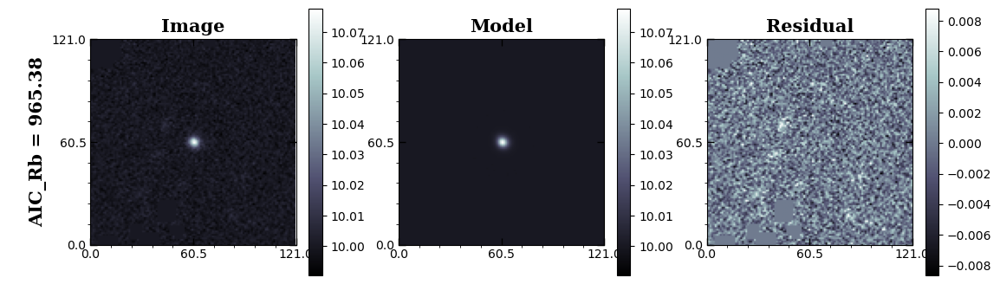

https://www.legacysurvey.org/viewer/jpeg-cutout?ra=202.3219798&dec=19.6709745&size=200&layer=ls-dr9


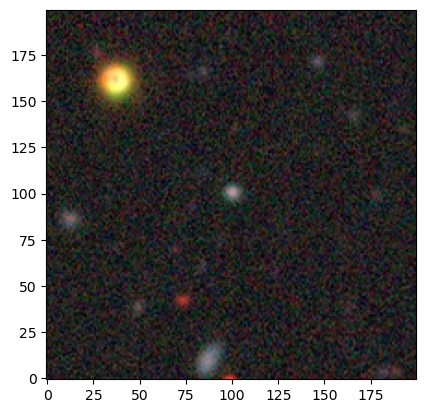

In [24]:
galid=4

ResGal=ResPack_g_2Comp_t.MC2fitSettingClass.result(galid=galid, group_id=None)
ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=False) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]] ## avoid warning results if possible 
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]  ## Best results regardlenss of warning
print(fn)

ResPack_g_2Comp_t.MC2fitSettingClass.drawing(galid=galid, fn=fn)
plt.show()
ResPack_g_2Comp_t.MC2fitSettingClass.drawing_legacy(galid=galid)

## g-band with fixed Sérsic index

This branch tests prescribed profile shapes. The first Sérsic component is initialized with \(n=1\), and the second with \(n=4\). The `is_allow_vary` array fixes the Sérsic-index entries during optimization, while `base_params_add=False` for index 4 makes the supplied values replace—not offset—the previous values.

Fixing `n` can stabilize the fit when the data quality is limited or when too many free parameters lead to unphysical solutions. The trade-off is that the model becomes less flexible.


### previous results & initial guess

Here, note that we set the sersic index of 1 for 1st component, and 4 for 2nd component.

In [52]:
# Build per-target base parameters for fixed-index trials.
# Component 0 receives n=1; component 1 receives n=4.
PrevRes_n=copy.deepcopy(ResPack_g_1Comp.params_array) # previous result. Shape: (N_Target(DI), Comp, item (7) )

## We will 'change' the parameter for the 1st component (Comp2) // Comp1 : Sky
PrevRes_n[:,0,4] = 1 ## Fix the Sersic index to 1 

## For 2nd component (Comp3)
PrevRes_n[:,1,:]=np.nan # Reset the parameters for the 3rd component (2nd comp for the gal)
PrevRes_n[:,1,0]=np.nan # By using Nan for the position, the position will be set to the center of the image
PrevRes_n[:,1,1]=np.nan # By using Nan for the position, the position will be set to the center of the image
PrevRes_n[:,1,2]=PrevRes_n[:,0,2] # Copy the mag
PrevRes_n[:,1,3] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_n[:,1,4] = 4 ## Fix the Sersic index to 4 
PrevRes_n[:,1,5:] = np.nan # Set the other values as Nan (default value)

### Setting and runlist


The parameter order used by `is_allow_vary` and `base_params_add` is:

| Index     |          0 |          1 |         2 |                3 |            4 |          5 |              6 |
| --------- | ---------: | ---------: | --------: | ---------------: | -----------: | ---------: | -------------: |
| Parameter | x position | y position | magnitude | effective radius | Sérsic index | axis ratio | position angle |

```python
is_allow_vary = [True, True, True, True, False, True, True]
```

`is_allow_vary` determines whether each parameter is allowed to vary during the GALFIT optimization.

* `True`: the parameter is free to vary.
* `False`: the parameter is fixed.

Here, the Sérsic indices are fixed, while all other parameters are allowed to vary.

```python
base_params_add = [True, True, True, True, False, True, True]
```

`base_params_add` determines how the values in `base_params_array` are combined with the initial parameters.

* `True`: add the value in `base_params_array` to the existing initial value.
* `False`: replace the existing initial value with the value in `base_params_array`.

Therefore, the Sérsic index is directly replaced by the supplied value rather than added to the previous estimate.


In [53]:
MC2_g_2comp_n=copy.deepcopy(MC2_g_2comp)
MC2_g_2comp_n.class_update_keys(proj_folder='g_2comp_n/')

In [55]:
Runlist2Comp_n=copy.deepcopy(MC2_g_2comp.RunlistClass)  # Copy the Runlist class 
for i, text in enumerate(Runlist2Comp_n.runlist['name']):
    newtext=text.split("_")
    newtext[1]="n"+newtext[1][1:]   ## As an example, I used 'n' for 'sersic index (n)' instead of 'f'
    Runlist2Comp_n.runlist['name'][i]='_'.join(newtext)
Runlist2Comp_n.show_runlist()

## For the Setting class, update the Runlist, Directory information, and initial guesses
MC2_g_2comp_n.update_Class(Runlist2Comp_n, DIgood, 
                           base_params_array_set=PrevRes_n,  ## Previous Galfit result array
                           is_allow_vary=[True, True, True, True, False, True, True], ## Fix Sersic indices
                           base_params_add = [True, True, True, True, False, True, True], # Sersic indices are replaced
                        )

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,ss_no_m3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
1,ss_no_m3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
2,ss_no_p0m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
3,ss_no_p0p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
4,ss_no_p3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
5,ss_no_p3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
6,sp_no_m3m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
7,sp_no_m3p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
8,sp_no_p0m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
9,sp_no_p0p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2


In [56]:
MC2_g_2comp_n.run()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 564.5 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



### From the central masking results

In [57]:
PrevRes_n_m=copy.deepcopy(ResPack_g_1Comp_m.params_array) # previous result. Shape: (N_Target(DI), Comp, item (7) )

## We will 'change' the parameter for the 1st component (Comp2) // Comp1 : Sky
PrevRes_n_m[:,0,4] = 1 ## Fix the Sersic index to 1 

## For 2nd component (Comp3)
PrevRes_n_m[:,1,:]=np.nan # Reset the parameters for the 3rd component (2nd comp for the gal)
PrevRes_n_m[:,1,0]=np.nan # By using Nan for the position, the position will be set to the center of the image
PrevRes_n_m[:,1,1]=np.nan # By using Nan for the position, the position will be set to the center of the image
PrevRes_n_m[:,1,2]=PrevRes_n_m[:,0,2] # Copy the mag
PrevRes_n_m[:,1,3] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_n_m[:,1,4] = 4 ## Fix the Sersic index to 4 
PrevRes_n_m[:,1,5:] = np.nan # Set the other values as Nan (default value)

In [58]:
MC2_g_2comp_n_m=copy.deepcopy(MC2_g_2comp_n)

Runlist2Comp_n_m=copy.deepcopy(MC2_g_2comp.RunlistClass)  # Copy the Runlist class 
for i, text in enumerate(Runlist2Comp_n_m.runlist['name']):
    newtext=text.split("_")
    newtext[1]="N"+newtext[1][1:]   
    Runlist2Comp_n_m.runlist['name'][i]='_'.join(newtext)
Runlist2Comp_n_m.show_runlist()

## For the Setting class, update the Runlist, Directory information, and initial guesses
MC2_g_2comp_n_m.update_Class(Runlist2Comp_n_m, DIgood, 
                           base_params_array_set=PrevRes_n_m,  ## Previous Galfit result array
                           is_allow_vary=[True, True, True, True, False, True, True], ## Fix Sersic index
                           base_params_add = [True, True, True, True, False, True, True], # Sersic indices are replaced
                        )

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,ss_No_m3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
1,ss_No_m3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
2,ss_No_p0m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
3,ss_No_p0p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
4,ss_No_p3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
5,ss_No_p3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
6,sp_No_m3m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
7,sp_No_m3p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
8,sp_No_p0m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
9,sp_No_p0p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2


In [59]:
MC2_g_2comp_n_m.run()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 595.2 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



### Optional: alternative starting points

In [60]:
Runlist2Comp_n_pos=copy.deepcopy(Runlist2Comp_n) ## new position
for i, text in enumerate(Runlist2Comp_n_pos.runlist['name']):
    newtext=text.split("_")
    newtext[1]=newtext[1][:1]+'p'+newtext[1][2:]  ## use 'p' for new positions
    Runlist2Comp_n_pos.runlist['name'][i]='_'.join(newtext)
Runlist2Comp_n_pos.show_runlist()

PrevRes_objpos_n=copy.deepcopy(PrevRes_n) # Copy the previous setting
for i in range(len(PrevRes_objpos)):
    PrevRes_objpos_n[i,1,0]=objpos[i,0] # Update the X position instead of Nan
    PrevRes_objpos_n[i,1,1]=objpos[i,1] # Update the Y position instead of Nan

MC2_g_2comp_n_pos=copy.deepcopy(MC2_g_2comp_n)
MC2_g_2comp_n_pos.update_Class(Runlist2Comp_n_pos, DIgood, 
                               base_params_array_set=PrevRes_objpos_n,  ## Previous Galfit result array
                               is_allow_vary=[True, True, True, True, False, True, True], ## Fix Sersic index
                               base_params_add = [True, True, True, True, False, True, True], # Sersic indices are replaced
                               skiplist=np.isnan(PrevRes_objpos_n[:,1,0]), ## skip if newpos = Nan
                              )

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,ss_np_m3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
1,ss_np_m3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
2,ss_np_p0m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
3,ss_np_p0p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
4,ss_np_p3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
5,ss_np_p3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
6,sp_np_m3m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
7,sp_np_m3p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
8,sp_np_p0m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
9,sp_np_p0p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2


In [61]:
MC2_g_2comp_n_pos.run()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 101.6 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



In [62]:
Runlist2Comp_n_m_pos=copy.deepcopy(Runlist2Comp_n_m) ## new position
for i, text in enumerate(Runlist2Comp_n_m_pos.runlist['name']):
    newtext=text.split("_")
    newtext[1]=newtext[1][:1]+'p'+newtext[1][2:]  ## use 'p' for new positions
    Runlist2Comp_n_m_pos.runlist['name'][i]='_'.join(newtext)
Runlist2Comp_n_m_pos.show_runlist()

PrevRes_objpos_n_m=copy.deepcopy(PrevRes_n_m) # Copy the previous setting
for i in range(len(PrevRes_objpos)):
    PrevRes_objpos_n_m[i,1,0]=objpos[i,0] # Update the X position instead of Nan
    PrevRes_objpos_n_m[i,1,1]=objpos[i,1] # Update the Y position instead of Nan

MC2_g_2comp_n_m_pos=copy.deepcopy(MC2_g_2comp_n_m)
MC2_g_2comp_n_m_pos.update_Class(Runlist2Comp_n_m_pos, DIgood, 
                                 base_params_array_set=PrevRes_objpos_n_m,  ## Previous Galfit result array
                                 is_allow_vary=[True, True, True, True, False, True, True], ## Fix Sersic index
                                 base_params_add = [True, True, True, True, False, True, True], # Sersic indices are replaced
                                 skiplist=np.isnan(PrevRes_objpos_n_m[:,1,0]), ## skip if newpos = Nan
                                )

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,ss_Np_m3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
1,ss_Np_m3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
2,ss_Np_p0m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
3,ss_Np_p0p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
4,ss_Np_p3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
5,ss_Np_p3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
6,sp_Np_m3m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
7,sp_Np_m3p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
8,sp_Np_p0m3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2
9,sp_Np_p0p3,"[sersic2, psf]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,2


In [63]:
MC2_g_2comp_n_m_pos.run()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 106.9 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



### Combine, Extract & post process

In [64]:
## Stack all the Runlists
Runlist2Comp_n_all=copy.deepcopy(Runlist2Comp_n)
Runlist2Comp_n_all.add_runlist(Runlist2Comp_n_m)

## If you did the 'optional' above
Runlist2Comp_n_all.add_runlist(Runlist2Comp_n_pos)
Runlist2Comp_n_all.add_runlist(Runlist2Comp_n_m_pos)

Runlist2Comp_n_all.show_runlist()

## Make a combined Setting class
MC2_g_2comp_n_all=copy.deepcopy(MC2_g_2comp_n)
MC2_g_2comp_n_all.update_Class(Runlist2Comp_n_all, DIgood)

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,ss_no_m3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, -3","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
1,ss_no_m3p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","-3.0, 3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
2,ss_no_p0m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
3,ss_no_p0p3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","0.0, 3.0","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
4,ss_no_p3m3,"[sersic2, sersic2]",2,"0.0, 0.0","0.0, 0.0","3.0, -3.","0.0, 10.","0.0, 4.0","0.0, 0.0","0.0, 0.0","(51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0)","(nan nan), (nan nan)","(nan nan), (nan nan)","(0.0 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1)","(nan nan), (nan nan)",True,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,p_Np_p0,[psf],1,0.0,0.0,3.0,0.0,0.0,0.0,0.0,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 10.0),(0.2 1.1),(nan nan),True,3
68,p_Np_p3,[psf],1,0.0,0.0,3.0,0.0,0.0,0.0,0.0,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 10.0),(0.2 1.1),(nan nan),True,3
69,s_Np_m3,[sersic2],1,0.0,0.0,3.0,0.0,0.0,0.0,0.0,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 10.0),(0.2 1.1),(nan nan),True,0
70,s_Np_p0,[sersic2],1,0.0,0.0,3.0,0.0,0.0,0.0,0.0,(51.0 71.0),(51.0 71.0),(nan nan),(nan nan),(0.0 10.0),(0.2 1.1),(nan nan),True,0


In [65]:
MC2_g_2comp_n_all.extract()
MC2_g_2comp_n_all.postprocessing()
MC2_g_2comp_n_all.postprocessing(stat_radius_array_set=stat_radius_array_g,
                           stat_item_namelist=stat_item_name_array) ## additional Stat regions

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 24.5 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



Remove files:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.1 s
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 26.0 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 28.8 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



In [67]:
ResPack_g_2Comp_n=MC2_g_2comp_n_all.pack_result()
pickle.dump(ResPack_g_2Comp_n, open(DIgood.dir_base+"ResPack_g_2Comp_n.pkl", "wb"))
ResPack_g_2Comp_n=pickle.load(open(DIgood.dir_base+"ResPack_g_2Comp_n.pkl", "rb"))
ResPack_g_2Comp_n.preset_generate_onlyval(is_mag=False)

Pack the results
>> comp_crit: AIC_Rb
>> backend: thread
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 11.4 s
>> Get all submodels


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
ss_no_p0p3,1.000000,0.000000,62.091500,61.392900,22.382300,2.420000,1.000000,21.456700,62.092300,61.482000,25.833600,4.136700,4.000000,23.577600,0.728568,0.728568,10144.372791,1.000000,0.779150,6016.149472,1.000000,1353.360703,0.050195,607.860822,0.000000
sp_no_p0m3,2.000000,0.000000,51.000000,71.000000,29.092800,46.821900,1.000000,22.703200,62.111400,61.439900,nan,nan,nan,21.570700,0.700868,0.700868,9755.767263,1.000000,0.729116,5627.656288,1.000000,972.019676,1.000000,233.436490,0.999990
sp_no_p0p3,2.000000,0.000000,51.000000,67.126700,28.812600,39.763200,1.000000,22.777800,62.105900,61.435200,nan,nan,nan,21.577100,0.700474,0.700474,9750.301066,1.000000,0.728445,5622.495600,1.000000,967.795773,1.000000,233.198631,0.999990
sp_no_p3m3,2.000000,0.000000,51.000000,65.533000,29.176100,57.864900,1.000000,22.326700,62.103600,61.434500,nan,nan,nan,21.573900,0.700469,0.700468,9750.223328,1.000000,0.728586,5623.583250,1.000000,970.008984,1.000000,232.897967,0.999991
sp_no_p3p3,2.000000,0.000000,51.000000,65.777300,29.126700,55.056000,1.000000,22.385300,62.104100,61.434900,nan,nan,nan,21.574300,0.700469,0.700469,9750.229998,1.000000,0.728568,5623.446952,1.000000,969.706168,1.000000,232.932375,0.999991
p_no_m3,3.000000,0.000000,62.095400,61.429000,nan,nan,nan,21.565500,nan,nan,nan,nan,nan,nan,0.701318,0.701318,9754.218790,1.000000,0.729571,5623.512610,1.000000,965.377815,1.000000,222.195383,0.999996
p_no_p0,3.000000,0.000000,62.095400,61.429000,nan,nan,nan,21.565500,nan,nan,nan,nan,nan,nan,0.701318,0.701318,9754.218790,1.000000,0.729571,5623.512610,1.000000,965.377815,1.000000,222.195383,0.999996
p_no_p3,3.000000,0.000000,62.095400,61.429000,nan,nan,nan,21.565500,nan,nan,nan,nan,nan,nan,0.701318,0.701318,9754.218790,1.000000,0.729571,5623.512610,1.000000,965.377815,1.000000,222.195383,0.999996
s_no_m3,0.000000,0.000000,62.076200,61.403800,21.816700,2.420000,1.000000,21.370900,nan,nan,nan,nan,nan,nan,0.727035,0.727035,10115.437709,1.000000,0.776293,5986.813903,1.000000,1325.276961,0.111686,580.897262,0.000000
s_no_p0,0.000000,0.000000,62.076200,61.403800,21.816700,2.420000,1.000000,21.370900,nan,nan,nan,nan,nan,nan,0.727035,0.727035,10115.437709,1.000000,0.776293,5986.813903,1.000000,1325.276961,0.111686,580.897262,0.000000


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
s_no_m3,0.000000,0.000000,62.076200,61.403800,21.816700,2.420000,1.000000,0.313900,78.852000,21.370900,nan,nan,nan,nan,nan,nan,nan,nan,0.727035,0.727035,10115.437709,1.000000,0.776293,5986.813903,1.000000,1325.276961,0.111686,580.897262,0.000000
ss_No_p3p3,1.000000,0.000000,71.000000,71.000000,116.335300,2.420000,1.000000,0.200000,-22.121300,116.378900,60.585800,60.942900,28.181300,41.648000,4.000000,0.820700,-75.657500,19.818000,0.957297,0.957297,13320.963531,0.999845,1.191841,9188.917314,0.000000,4489.176051,0.000000,3431.558315,0.000000
sp_No_p3m3,2.000000,0.000000,51.000000,71.000000,27.085800,10.810900,1.000000,0.200000,84.557400,23.879100,62.096200,61.427200,nan,nan,nan,nan,nan,21.565500,0.700329,0.700329,9748.288117,1.000000,0.727986,5618.971376,1.000000,966.115753,1.000000,234.014460,0.999988
p_No_m3,3.000000,0.000000,62.095400,61.429000,nan,nan,nan,nan,nan,21.565500,nan,nan,nan,nan,nan,nan,nan,nan,0.701318,0.701318,9754.218437,1.000000,0.729571,5623.512256,1.000000,965.375620,1.000000,222.192781,0.999996


./gal_out/gal0004/g_2comp_n/result_p_No_m3.fits


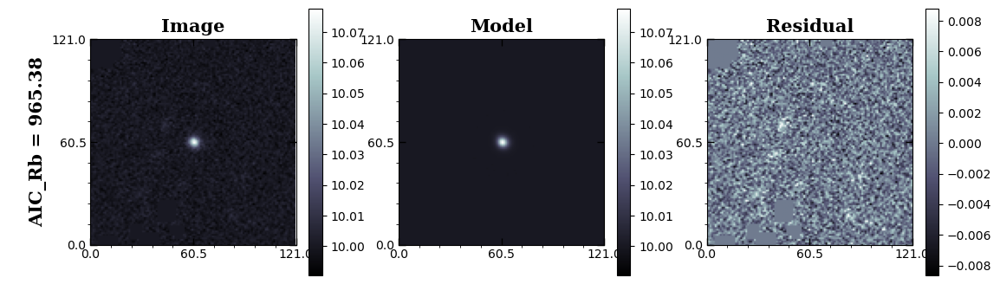

https://www.legacysurvey.org/viewer/jpeg-cutout?ra=202.3219798&dec=19.6709745&size=200&layer=ls-dr9


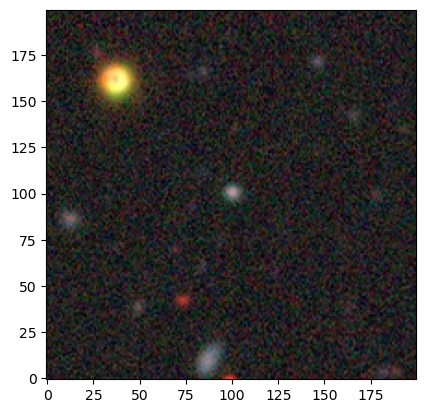

In [66]:
galid=4

ResGal=MC2_g_2comp_n_all.result(galid=galid, group_id=None)
ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=False) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]] ## avoid warning results if possible 
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]  ## Best results regardlenss of warning
print(fn)

MC2_g_2comp_n_all.drawing(galid=galid, fn=fn)
plt.show()
# MC2_g_2comp_n_all.drawing_legacy(galid=galid)

## r-band

After completing the g-band single-Sérsic fits, the same basic workflow is applied to the r-band image.

The r-band setup usually reuses the same logic as the g-band setup, but with r-band image, sigma, PSF, and mask files.

Running the one-component model in both bands allows later comparison of structural parameters and colors.

### Regular fitting

In [70]:
MC2_r_2comp=copy.deepcopy(MC2_g_2comp) ## Copy from g-band 2-comp fitting, including Runlist
MC2_r_2comp.class_update_keys(proj_folder='r_2comp/',           ## Folder name for this fit
                             fni_image = 'image_lr.fits',      ## image name (in DI.dir_work_list)
                             fni_sigma = 'sigma_lr.fits',      ## sigma name (in DI.dir_work_list)
                             fni_psf = 'psf_model_lr.fits',    ## psf name (in DI.dir_work_list)
                             re_lim_list = psf_lim_r
                             )

In [71]:
## Copy the result of the 1 component (r-band)

PrevRes_r=copy.deepcopy(ResPack_r_1Comp.params_array) # previous result. Shape: N_Target(DI), Comp, item (7)

## We will not change the parameter for the 1st component (Comp2) // Comp1 : Sky
## PrevRes_r[:,0,:] 

## For 2nd component (Comp3), we will copy the 1st component mags as the initial guess
PrevRes_r[:,1,:]=np.nan # Reset all the parameters for Comp3 (2nd comp for the gal)
PrevRes_r[:,1,0]=np.nan # By using Nan for the position, the position will be set to the center of the image
PrevRes_r[:,1,1]=np.nan # By using Nan for the position, the position will be set to the center of the image
PrevRes_r[:,1,2]=PrevRes_r[:,0,2] # Copy the mag
PrevRes_r[:,1,3] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_r[:,1,4] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_r[:,1,5:] = np.nan # Set the other values as Nan (default value)

## For the Setting class, update the Runlist, Directory information, and initial guesses
## We could use the same Runlist as the g-band one.
MC2_r_2comp.update_Class(Runlist2Comp, DIgood, 
                         base_params_array_set=PrevRes_r,  # one base parameter array per target
                         base_params_add=True            # Runlist values are offsets from PrevRes
                        )
MC2_r_2comp.run()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 716.3 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



In [72]:
### Optional - alternative starting points

PrevRes_objpos_r=copy.deepcopy(PrevRes_r) # Copy the previous setting
for i in range(len(PrevRes_objpos_r)):
    PrevRes_objpos_r[i,1,0]=objpos[i,0] # Update the X position instead of Nan
    PrevRes_objpos_r[i,1,1]=objpos[i,1] # Update the Y position instead of Nan

## Make a new Setting class
MC2_r_2comp_pos=copy.deepcopy(MC2_r_2comp)
MC2_r_2comp_pos.update_Class(Runlist2Comp_pos, DIgood, 
                                  base_params_array_set=PrevRes_objpos_r,  ## Previous GALFIT result array
                                  base_params_add=True,            ## Add the offset to the previous result
                                  skiplist=np.isnan(PrevRes_objpos_r[:,1,0]), ## skip if newpos = Nan
                                  )
## Make a combined Setting class
MC2_r_2comp_all=copy.deepcopy(MC2_r_2comp)
MC2_r_2comp_all.update_Class(Runlist2Comp_all, DIgood)

MC2_r_2comp_pos.run()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 123.6 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



In [73]:
## If you did not use MC2_r_2comp_pos, use MC2_r_2comp instead of MC2_r_2comp_all

MC2_r_2comp_all.extract()
MC2_r_2comp_all.postprocessing()
MC2_r_2comp_all.postprocessing(stat_radius_array_set=stat_radius_array_r,
                           stat_item_namelist=stat_item_name_array) ## additional Stat regions

ResPack_r_2Comp=MC2_r_2comp_all.pack_result()
pickle.dump(ResPack_r_2Comp, open(DIgood.dir_base+"ResPack_r_2Comp.pkl", "wb"))
ResPack_r_2Comp=pickle.load(open(DIgood.dir_base+"ResPack_r_2Comp.pkl", "rb"))
ResPack_r_2Comp.preset_generate_onlyval(is_mag=False)

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 12.1 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



Remove files:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.1 s
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 12.6 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 14.5 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

Pack the results
>> comp_crit: AIC_Rb
>> backend: thread
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 5.9 s
>> Get all submodels


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
ss_fo_m3m3,1.000000,0.000000,62.153900,61.479200,26.283700,10.659600,10.000000,20.552400,61.965600,61.409000,27.238000,16.562400,10.000000,20.545100,0.722615,0.722615,10064.259800,1.000000,0.751242,5804.111046,1.000000,1958.051517,0.997573,789.319122,0.000000
ss_fo_p0m3,1.000000,0.000000,62.061500,61.444500,27.905700,22.593500,10.000000,20.798600,62.077700,61.459300,25.162800,6.216100,10.000000,20.513300,0.716625,0.716625,9981.090855,1.000000,0.740294,5719.965237,1.000000,1872.689582,0.999988,713.478976,0.000001
ss_fo_p0p3,1.000000,0.000000,62.067800,61.456300,27.958300,26.273600,10.000000,20.200200,60.500000,60.500000,30.958300,10.000000,4.000000,25.478400,0.704691,0.841560,11715.942913,1.000000,0.967753,7468.211158,0.978078,3617.806416,0.000000,2465.854518,0.000000
ss_fo_p3p3,1.000000,0.000000,62.104400,61.471800,27.607100,26.427800,10.000000,20.744500,62.040800,61.431400,27.350100,23.053500,10.000000,20.318500,0.740531,0.740531,10313.041814,1.000000,0.783269,6050.264539,1.000000,2208.207944,0.134159,1044.826056,0.000000
sp_fo_p0m3,2.000000,0.000000,62.067800,61.456300,27.958300,26.273600,10.000000,20.200200,60.500000,60.500000,nan,nan,nan,24.958300,0.704366,0.833001,11592.397745,1.000000,0.952228,7344.671458,0.998674,3494.205589,0.000000,2342.327692,0.000000
sp_fo_p0p3,2.000000,0.000000,62.067800,61.456300,27.958300,26.273600,10.000000,20.200200,60.500000,60.500000,nan,nan,nan,30.958300,0.704257,0.842912,11730.069719,1.000000,0.970131,7482.343432,0.968943,3631.877563,0.000000,2480.099087,0.000000
sp_fo_p3m3,2.000000,0.000000,61.113500,60.298600,25.718000,4.673900,10.000000,21.508200,62.342100,61.794600,nan,nan,nan,21.251400,0.694812,0.694812,9672.958481,1.000000,0.702895,5427.295764,1.000000,1577.074225,1.000000,441.101070,0.999500
sp_fo_p3p3,2.000000,0.000000,62.067800,61.456300,30.958300,26.273600,10.000000,23.200200,60.500000,60.500000,nan,nan,nan,30.958300,1.091299,1.120367,15583.912612,0.000000,1.471222,11335.732855,0.000000,7483.881490,0.000000,6346.573197,0.000000
p_fo_m3,3.000000,0.000000,62.111800,61.502600,nan,nan,nan,20.956000,nan,nan,nan,nan,nan,nan,0.700199,0.700199,9738.673563,1.000000,0.712724,5493.839750,1.000000,1641.394499,1.000000,505.972116,0.796910
p_fo_p0,3.000000,0.000000,62.111800,61.502600,nan,nan,nan,20.956000,nan,nan,nan,nan,nan,nan,0.700199,0.700199,9738.673563,1.000000,0.712724,5493.839750,1.000000,1641.394499,1.000000,505.972116,0.796910


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
s_fo_m3,0.000000,0.000000,62.061800,61.442900,27.762100,33.480000,10.000000,0.806300,-64.883400,19.406000,nan,nan,nan,nan,nan,nan,nan,nan,0.750247,0.750247,10439.192120,1.000000,0.799247,6164.624600,1.000000,2317.486297,0.002352,1124.997711,0.000000
ss_fo_p0m3,1.000000,0.000000,62.061500,61.444500,27.905700,22.593500,10.000000,0.560400,56.737600,20.798600,62.077700,61.459300,25.162800,6.216100,10.000000,0.769800,-41.193100,20.513300,0.716625,0.716625,9981.090855,1.000000,0.740294,5719.965237,1.000000,1872.689582,0.999988,713.478976,0.000001
sp_fo_p3m3,2.000000,0.000000,61.113500,60.298600,25.718000,4.673900,10.000000,0.908200,42.971400,21.508200,62.342100,61.794600,nan,nan,nan,nan,nan,21.251400,0.694812,0.694812,9672.958481,1.000000,0.702895,5427.295764,1.000000,1577.074225,1.000000,441.101070,0.999500
p_fo_m3,3.000000,0.000000,62.111800,61.502600,nan,nan,nan,nan,nan,20.956000,nan,nan,nan,nan,nan,nan,nan,nan,0.700199,0.700199,9738.673563,1.000000,0.712724,5493.839750,1.000000,1641.394499,1.000000,505.972116,0.796910


./gal_out/gal0004/r_2comp/result_p_fo_m3.fits


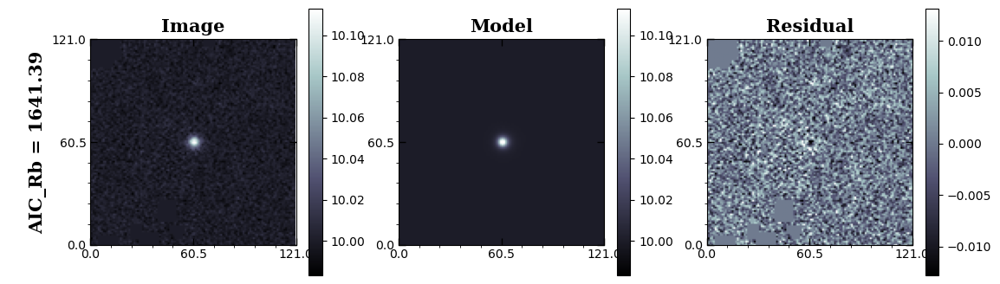

In [74]:
galid=4

ResGal=MC2_r_2comp_all.result(galid=galid, group_id=None)
ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=True) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]]
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]
print(fn)

MC2_r_2comp_all.drawing(galid=galid, fn=fn)
plt.show()
# MC2_1Comp_gm.drawing_legacy(galid=galid)

### From 1-comp central masking

In [75]:
## You might consider copying MC2_r_2comp.
## Here, I copy MC2_g_2comp_m instead.

MC2_r_2comp_m=copy.deepcopy(MC2_g_2comp_m)  ## Copy from g-band 2-comp fitting, including Runlist
MC2_r_2comp_m.class_update_keys(proj_folder='r_2comp_m/',           ## Folder name for this fit
                             fni_image = 'image_lr.fits',      ## image name (in DI.dir_work_list)
                             fni_sigma = 'sigma_lr.fits',      ## sigma name (in DI.dir_work_list)
                             fni_psf = 'psf_model_lr.fits',    ## psf name (in DI.dir_work_list)
                             re_lim_list = psf_lim_r
                             )

## Copy the result of the 1 component (r-band)
PrevRes_r_m=copy.deepcopy(ResPack_r_1Comp_m.params_array) # previous result. Shape: N_Target(DI), Comp, item (7)

## We will not change the parameter for the 1st component (Comp2) // Comp1 : Sky
## PrevRes_r_m[:,0,:] 

PrevRes_r_m[:,1,:]=np.nan # Reset the parameters for Comp3 (2nd comp for the gal)
PrevRes_r_m[:,1,0]=np.nan # By using Nan for the position, the position will be set to the center of the image
PrevRes_r_m[:,1,1]=np.nan # By using Nan for the position, the position will be set to the center of the image
PrevRes_r_m[:,1,2]=PrevRes_r_m[:,0,2] # Copy the mag
PrevRes_r_m[:,1,3] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_r_m[:,1,4] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_r_m[:,1,5:] = np.nan # Set the other values as Nan (default value)

## For the Setting class, update the Runlist, Directory information, and initial guesses
## We could use the same Runlist as the g-band one.
MC2_r_2comp_m.update_Class(Runlist2Comp_m, DIgood, 
                         base_params_array_set=PrevRes_r_m,  ## Previous GALFIT result array
                         base_params_add=True            ## Add the offset to the previous result
                         # base_params_add == False --> Replace the paremters
                        )
MC2_r_2comp_m.run()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 812.5 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



In [76]:
### Optional - alternative starting points

PrevRes_objpos_r_m=copy.deepcopy(PrevRes_r_m) # Copy the previous setting
for i in range(len(PrevRes_objpos_r_m)):
    PrevRes_objpos_r_m[i,1,0]=objpos[i,0] # Update the X position instead of Nan
    PrevRes_objpos_r_m[i,1,1]=objpos[i,1] # Update the Y position instead of Nan

## Make a new Setting class
MC2_r_2comp_m_pos=copy.deepcopy(MC2_r_2comp_m)
MC2_r_2comp_m_pos.update_Class(Runlist2Comp_m_pos, DIgood, 
                               base_params_array_set=PrevRes_objpos_r_m,  # one base parameter array per target
                               base_params_add=True,            # Runlist values are offsets from PrevRes
                               skiplist=np.isnan(PrevRes_objpos_r_m[:,1,0]), ## skip when newpos == Nan
                               )
## Make a combined Setting class
MC2_r_2comp_m_all=copy.deepcopy(MC2_r_2comp_m)
MC2_r_2comp_m_all.update_Class(Runlist2Comp_m_all, DIgood)

MC2_r_2comp_m_pos.run()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 144.8 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



In [77]:
## If you did not use MC2_r_2comp_pos, use MC2_r_2comp instead of MC2_r_2comp_all

MC2_r_2comp_m_all.extract()
MC2_r_2comp_m_all.postprocessing()
MC2_r_2comp_m_all.postprocessing(stat_radius_array_set=stat_radius_array_r,
                           stat_item_namelist=stat_item_name_array) ## additional Stat regions

ResPack_r_2Comp_m=MC2_r_2comp_m_all.pack_result()
pickle.dump(ResPack_r_2Comp_m, open(DIgood.dir_base+"ResPack_r_2Comp_m.pkl", "wb"))
ResPack_r_2Comp_m=pickle.load(open(DIgood.dir_base+"ResPack_r_2Comp_m.pkl", "rb"))
ResPack_r_2Comp_m.preset_generate_onlyval(is_mag=False)

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 11.8 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



Remove files:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.1 s
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 13.0 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 14.3 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

Pack the results
>> comp_crit: AIC_Rb
>> backend: thread
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 6.1 s
>> Get all submodels


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
ss_mo_p0m3,1.000000,0.000000,62.140200,61.491400,26.178300,8.670200,10.000000,21.856500,62.052100,61.443800,25.107300,6.287200,10.000000,20.414200,0.714202,0.714202,9947.448316,1.000000,0.736762,5692.812092,1.000000,1846.101793,0.999999,697.576489,0.000006
ss_mo_p0p3,1.000000,0.000000,61.670200,61.029100,28.424200,23.071000,10.000000,20.645200,60.500000,60.500000,31.424200,10.000000,4.000000,25.944300,0.761458,0.924213,12863.653433,1.000000,1.117152,8616.494610,0.000000,4767.822242,0.000000,3628.697020,0.000000
ss_mo_p3p3,1.000000,0.000000,62.021000,61.382700,28.394800,66.971300,10.000000,19.171000,51.000000,51.000000,87.789100,2.420000,10.000000,86.211300,0.771405,0.771405,10741.760249,1.000000,0.839781,6484.615558,1.000000,2640.811906,0.000000,1404.785925,0.000000
sp_mo_p0m3,2.000000,0.000000,61.670200,61.029100,28.424200,23.071000,10.000000,20.645200,60.500000,60.500000,nan,nan,nan,25.424200,0.758429,0.917223,12762.239684,1.000000,1.104426,8515.068297,0.000000,4666.312919,0.000000,3526.989254,0.000000
sp_mo_p0p3,2.000000,0.000000,61.670200,61.029100,28.424200,23.071000,10.000000,20.645200,60.500000,60.500000,nan,nan,nan,31.424200,0.761838,0.925373,12875.456201,1.000000,1.119148,8628.284814,0.000000,4779.529436,0.000000,3640.234643,0.000000
sp_mo_p3m3,2.000000,0.000000,60.949600,60.071800,27.297600,17.414800,10.000000,21.464300,62.327800,61.800100,nan,nan,nan,21.191700,0.695312,0.695312,9679.902289,1.000000,0.703642,5433.039319,1.000000,1584.070612,1.000000,447.733424,0.998871
sp_mo_p3p3,2.000000,0.000000,61.670200,61.029100,31.424200,23.071000,10.000000,23.645200,60.500000,60.500000,nan,nan,nan,31.424200,1.109697,1.128977,15703.511830,0.000000,1.486775,11455.331147,0.000000,7603.337113,0.000000,6465.674561,0.000000
p_mo_m3,3.000000,0.000000,62.112100,61.502700,nan,nan,nan,20.956000,nan,nan,nan,nan,nan,nan,0.700199,0.700199,9738.672358,1.000000,0.712724,5493.838545,1.000000,1641.393294,1.000000,505.972046,0.796910
p_mo_p0,3.000000,0.000000,62.112100,61.502700,nan,nan,nan,20.956000,nan,nan,nan,nan,nan,nan,0.700199,0.700199,9738.672358,1.000000,0.712724,5493.838545,1.000000,1641.393294,1.000000,505.972046,0.796910
p_mo_p3,3.000000,0.000000,62.112100,61.502700,nan,nan,nan,20.956000,nan,nan,nan,nan,nan,nan,0.700199,0.700199,9738.672358,1.000000,0.712724,5493.838545,1.000000,1641.393294,1.000000,505.972046,0.796910


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
s_mo_m3,0.000000,0.000000,62.063400,61.445000,28.197700,43.294200,10.000000,0.816600,76.246600,19.269600,nan,nan,nan,nan,nan,nan,nan,nan,0.757941,0.757941,10546.088769,1.000000,0.812095,6263.463114,1.000000,2414.331200,0.000012,1215.603016,0.000000
ss_mo_p0m3,1.000000,0.000000,62.140200,61.491400,26.178300,8.670200,10.000000,0.292600,53.549600,21.856500,62.052100,61.443800,25.107300,6.287200,10.000000,0.783300,-44.027700,20.414200,0.714202,0.714202,9947.448316,1.000000,0.736762,5692.812092,1.000000,1846.101793,0.999999,697.576489,0.000006
sp_mo_p3m3,2.000000,0.000000,60.949600,60.071800,27.297600,17.414800,10.000000,0.291800,60.099300,21.464300,62.327800,61.800100,nan,nan,nan,nan,nan,21.191700,0.695312,0.695312,9679.902289,1.000000,0.703642,5433.039319,1.000000,1584.070612,1.000000,447.733424,0.998871
p_mo_m3,3.000000,0.000000,62.112100,61.502700,nan,nan,nan,nan,nan,20.956000,nan,nan,nan,nan,nan,nan,nan,nan,0.700199,0.700199,9738.672358,1.000000,0.712724,5493.838545,1.000000,1641.393294,1.000000,505.972046,0.796910


./gal_out/gal0004/r_2comp_m/result_p_mo_m3.fits


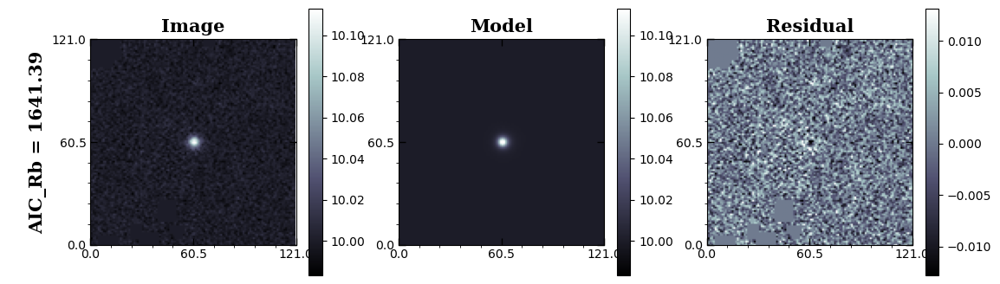

In [78]:
galid=4

ResGal=MC2_r_2comp_m_all.result(galid=galid, group_id=None)
ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=True) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]]
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]
print(fn)

MC2_r_2comp_m_all.drawing(galid=galid, fn=fn)
plt.show()
# MC2_1Comp_gm.drawing_legacy(galid=galid)

### Total

Combine all r-band two-component trials

This section does **not** rerun GALFIT. It builds a combined Runlist and creates symbolic links to results produced in the separate unmasked and central-mask branches. The combined Setting can then compare all trials through one `ResPack`.


In [79]:
MC2_r_2comp_t=copy.deepcopy(MC2_r_2comp_all)
MC2_r_2comp_t.class_update_keys(proj_folder='r_2comp_t/', re_lim_list=psf_lim_r)
MC2_r_2comp_t.update_Class(Runlist2Comp_tot, DIgood)

## Copy the data to the new folder by using symbolic links
res = dhfc.multicore_generate_link_galfit(DIgood, MC2_r_2comp_all, MC2_r_2comp_t)
res = dhfc.multicore_generate_link_galfit(DIgood, MC2_r_2comp_m_all, MC2_r_2comp_t)

## For rest of the part, use the MC2_r_2comp
ResPack_r_2Comp_t=MC2_r_2comp_t.pack_result()
pickle.dump(ResPack_r_2Comp_t, open(DIgood.dir_base+"ResPack_r_2Comp_t.pkl", "wb"))
ResPack_r_2Comp_t=pickle.load(open(DIgood.dir_base+"ResPack_r_2Comp_t.pkl", "rb"))
ResPack_r_2Comp_t.preset_generate_onlyval(is_mag=False)

Generate GALFIT links:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.1 s
Links created: 3219
Missing source files: 4521


Generate GALFIT links:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.1 s
Links created: 3214
Missing source files: 4526
Pack the results
>> comp_crit: AIC_Rb
>> backend: thread
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 10.5 s
>> Get all submodels


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
ss_fo_m3m3,1.000000,0.000000,62.153900,61.479200,26.283700,10.659600,10.000000,20.552400,61.965600,61.409000,27.238000,16.562400,10.000000,20.545100,0.722615,0.722615,10064.259800,1.000000,0.751242,5804.111046,1.000000,1958.051517,0.997573,789.319122,0.000000
ss_fo_p0m3,1.000000,0.000000,62.061500,61.444500,27.905700,22.593500,10.000000,20.798600,62.077700,61.459300,25.162800,6.216100,10.000000,20.513300,0.716625,0.716625,9981.090855,1.000000,0.740294,5719.965237,1.000000,1872.689582,0.999988,713.478976,0.000001
ss_fo_p0p3,1.000000,0.000000,62.067800,61.456300,27.958300,26.273600,10.000000,20.200200,60.500000,60.500000,30.958300,10.000000,4.000000,25.478400,0.704691,0.841560,11715.942913,1.000000,0.967753,7468.211158,0.978078,3617.806416,0.000000,2465.854518,0.000000
ss_fo_p3p3,1.000000,0.000000,62.104400,61.471800,27.607100,26.427800,10.000000,20.744500,62.040800,61.431400,27.350100,23.053500,10.000000,20.318500,0.740531,0.740531,10313.041814,1.000000,0.783269,6050.264539,1.000000,2208.207944,0.134159,1044.826056,0.000000
sp_fo_p0m3,2.000000,0.000000,62.067800,61.456300,27.958300,26.273600,10.000000,20.200200,60.500000,60.500000,nan,nan,nan,24.958300,0.704366,0.833001,11592.397745,1.000000,0.952228,7344.671458,0.998674,3494.205589,0.000000,2342.327692,0.000000
sp_fo_p0p3,2.000000,0.000000,62.067800,61.456300,27.958300,26.273600,10.000000,20.200200,60.500000,60.500000,nan,nan,nan,30.958300,0.704257,0.842912,11730.069719,1.000000,0.970131,7482.343432,0.968943,3631.877563,0.000000,2480.099087,0.000000
sp_fo_p3m3,2.000000,0.000000,61.113500,60.298600,25.718000,4.673900,10.000000,21.508200,62.342100,61.794600,nan,nan,nan,21.251400,0.694812,0.694812,9672.958481,1.000000,0.702895,5427.295764,1.000000,1577.074225,1.000000,441.101070,0.999500
sp_fo_p3p3,2.000000,0.000000,62.067800,61.456300,30.958300,26.273600,10.000000,23.200200,60.500000,60.500000,nan,nan,nan,30.958300,1.091299,1.120367,15583.912612,0.000000,1.471222,11335.732855,0.000000,7483.881490,0.000000,6346.573197,0.000000
p_fo_m3,3.000000,0.000000,62.111800,61.502600,nan,nan,nan,20.956000,nan,nan,nan,nan,nan,nan,0.700199,0.700199,9738.673563,1.000000,0.712724,5493.839750,1.000000,1641.394499,1.000000,505.972116,0.796910
p_fo_p0,3.000000,0.000000,62.111800,61.502600,nan,nan,nan,20.956000,nan,nan,nan,nan,nan,nan,0.700199,0.700199,9738.673563,1.000000,0.712724,5493.839750,1.000000,1641.394499,1.000000,505.972116,0.796910


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
s_fo_m3,0.000000,0.000000,62.061800,61.442900,27.762100,33.480000,10.000000,0.806300,-64.883400,19.406000,nan,nan,nan,nan,nan,nan,nan,nan,0.750247,0.750247,10439.192120,1.000000,0.799247,6164.624600,1.000000,2317.486297,0.002352,1124.997711,0.000000
ss_mo_p0m3,1.000000,0.000000,62.140200,61.491400,26.178300,8.670200,10.000000,0.292600,53.549600,21.856500,62.052100,61.443800,25.107300,6.287200,10.000000,0.783300,-44.027700,20.414200,0.714202,0.714202,9947.448316,1.000000,0.736762,5692.812092,1.000000,1846.101793,0.999999,697.576489,0.000006
sp_fo_p3m3,2.000000,0.000000,61.113500,60.298600,25.718000,4.673900,10.000000,0.908200,42.971400,21.508200,62.342100,61.794600,nan,nan,nan,nan,nan,21.251400,0.694812,0.694812,9672.958481,1.000000,0.702895,5427.295764,1.000000,1577.074225,1.000000,441.101070,0.999500
p_mo_m3,3.000000,0.000000,62.112100,61.502700,nan,nan,nan,nan,nan,20.956000,nan,nan,nan,nan,nan,nan,nan,nan,0.700199,0.700199,9738.672358,1.000000,0.712724,5493.838545,1.000000,1641.393294,1.000000,505.972046,0.796910


./gal_out/gal0004/r_2comp_t/result_p_mo_m3.fits


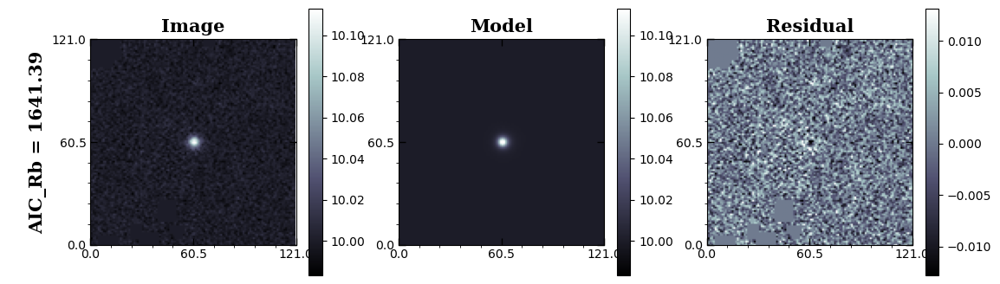

In [80]:
galid=4

ResGal=MC2_r_2comp_t.result(galid=galid, group_id=None)
ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=True) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]]
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]
print(fn)

MC2_r_2comp_t.drawing(galid=galid, fn=fn)
plt.show()
# MC2_1Comp_gm.drawing_legacy(galid=galid)

### Fixed N

In [81]:
MC2_r_2comp_n=copy.deepcopy(MC2_g_2comp_n)
MC2_r_2comp_n.class_update_keys(proj_folder='r_2comp_n/',           ## Folder name for this fit
                             fni_image = 'image_lr.fits',      ## image name (in DI.dir_work_list)
                             fni_sigma = 'sigma_lr.fits',      ## sigma name (in DI.dir_work_list)
                             fni_psf = 'psf_model_lr.fits',    ## psf name (in DI.dir_work_list)
                             re_lim_list = psf_lim_r
                             )

## Copy the result of the 1 component (r-band)
PrevRes_r_n=copy.deepcopy(ResPack_r_1Comp.params_array) # previous result. Shape: N_Target(DI), Comp, item (7)

## We will 'change' the parameter for the 1st component (Comp2) // Comp1 : Sky
PrevRes_r_n[:,0,4] = 1 ## Fix the Sersic index to 1 

PrevRes_r_n[:,1,:]=np.nan # Reset the parameters for the 3rd component (2nd comp for the gal)
PrevRes_r_n[:,1,0]=np.nan # By using Nan for the position, the position will be set to the center of the image
PrevRes_r_n[:,1,1]=np.nan # By using Nan for the position, the position will be set to the center of the image
PrevRes_r_n[:,1,2]=PrevRes_r_n[:,0,2] # Copy the mag
PrevRes_r_n[:,1,3] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_r_n[:,1,4] = 4 ## Fix the Sersic index to 4 
PrevRes_r_n[:,1,5:] = np.nan # Set the other values as Nan (default value)

## For the Setting class, update the Runlist, Directory information, and initial guesses
## We could use the same Runlist as the g-band one.
MC2_r_2comp_n.update_Class(Runlist2Comp_n, DIgood, 
                           base_params_array_set=PrevRes_r_n,  ## Previous Galfit result array
                           is_allow_vary=[True, True, True, True, False, True, True], ## Fix Sersic index
                           base_params_add = [True, True, True, True, False, True, True], # Sersic indices are replaced
                        )
MC2_r_2comp_n.run()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 580.1 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



In [82]:
MC2_r_2comp_n_m=copy.deepcopy(MC2_r_2comp_n)

## Copy the result of the 1 component (r-band)
PrevRes_r_n_m=copy.deepcopy(ResPack_r_1Comp_m.params_array) # previous result. Shape: N_Target(DI), Comp, item (7)

## We will 'change' the parameter for the 1st component (Comp2) // Comp1 : Sky
PrevRes_r_n_m[:,0,4] = 1 ## Fix the Sersic index to 1 

PrevRes_r_n_m[:,1,:]=np.nan # Reset the parameters for the 3rd component (2nd comp for the gal)
PrevRes_r_n_m[:,1,0]=np.nan # By using Nan for the position, the position will be set to the center of the image
PrevRes_r_n_m[:,1,1]=np.nan # By using Nan for the position, the position will be set to the center of the image
PrevRes_r_n_m[:,1,2]=PrevRes_r_n_m[:,0,2] # Copy the mag
PrevRes_r_n_m[:,1,3] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_r_n_m[:,1,4] = 4 ## Fix the Sersic index to 4 
PrevRes_r_n_m[:,1,5:] = np.nan # Set the other values as Nan (default value)

## For the Setting class, update the Runlist, Directory information, and initial guesses
## We could use the same Runlist as the g-band one.
MC2_r_2comp_n_m.update_Class(Runlist2Comp_n_m, DIgood, 
                           base_params_array_set=PrevRes_r_n_m,  ## Previous Galfit result array
                           is_allow_vary=[True, True, True, True, False, True, True], ## Fix Sersic index
                           base_params_add = [True, True, True, True, False, True, True], # Sersic indices are replaced
                        )
MC2_r_2comp_n_m.run()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 629.2 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



In [83]:
### Optional - alternative starting points

PrevRes_objpos_r_n=copy.deepcopy(PrevRes_r_n) # Copy the previous setting
for i in range(len(PrevRes_objpos_r_n)):
    PrevRes_objpos_r_n[i,1,0]=objpos[i,0] # Update the X position instead of Nan
    PrevRes_objpos_r_n[i,1,1]=objpos[i,1] # Update the Y position instead of Nan

## Make a new Setting class
MC2_r_2comp_n_pos=copy.deepcopy(MC2_r_2comp_n)
MC2_r_2comp_n_pos.update_Class(Runlist2Comp_n_pos, DIgood, 
                                  base_params_array_set=PrevRes_objpos_r_n,  ## Previous GALFIT result array
                                  base_params_add=True,            ## Add the offset to the previous result
                                  skiplist=np.isnan(PrevRes_objpos_r_n[:,1,0]), ## skip if newpos = Nan
                                  )
## Make a combined Setting class
MC2_r_2comp_n_all=copy.deepcopy(MC2_r_2comp_n)
MC2_r_2comp_n_all.update_Class(Runlist2Comp_n_all, DIgood)

MC2_r_2comp_n_pos.run()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 115.1 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



In [84]:
### Optional - alternative starting points

PrevRes_objpos_r_n_m=copy.deepcopy(PrevRes_r_n_m) # Copy the previous setting
for i in range(len(PrevRes_objpos_r_n_m)):
    PrevRes_objpos_r_n_m[i,1,0]=objpos[i,0] # Update the X position instead of Nan
    PrevRes_objpos_r_n_m[i,1,1]=objpos[i,1] # Update the Y position instead of Nan

## Make a new Setting class
MC2_r_2comp_n_m_pos=copy.deepcopy(MC2_r_2comp_n_m)
MC2_r_2comp_n_m_pos.update_Class(Runlist2Comp_n_m_pos, DIgood, 
                                  base_params_array_set=PrevRes_objpos_r_n_m,  ## Previous GALFIT result array
                                  base_params_add=True,            ## Add the offset to the previous result
                                  skiplist=np.isnan(PrevRes_objpos_r_n_m[:,1,0]), ## skip if newpos = Nan
                                  )
## Make a combined Setting class
MC2_r_2comp_n_m_all=copy.deepcopy(MC2_r_2comp_n_m)
MC2_r_2comp_n_m_all.update_Class(Runlist2Comp_n_all, DIgood)

MC2_r_2comp_n_m_pos.run()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 121.7 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



In [85]:
## Make a combined Setting class
MC2_r_2comp_n_all=copy.deepcopy(MC2_r_2comp_n)
MC2_r_2comp_n_all.update_Class(Runlist2Comp_n_all, DIgood)

MC2_r_2comp_n_all.extract()
MC2_r_2comp_n_all.postprocessing()
MC2_r_2comp_n_all.postprocessing(stat_radius_array_set=stat_radius_array_r,
                           stat_item_namelist=stat_item_name_array) ## additional Stat regions

ResPack_r_2Comp_n=MC2_r_2comp_n_all.pack_result()
pickle.dump(ResPack_r_2Comp_n, open(DIgood.dir_base+"ResPack_r_2Comp_n.pkl", "wb"))
ResPack_r_2Comp_n=pickle.load(open(DIgood.dir_base+"ResPack_r_2Comp_n.pkl", "rb"))
ResPack_r_2Comp_n.preset_generate_onlyval(is_mag=False)

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 25.2 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



Remove files:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.1 s
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 25.7 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 28.6 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

Pack the results
>> comp_crit: AIC_Rb
>> backend: thread
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 11.5 s
>> Get all submodels


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
ss_no_p0p3,1.000000,0.000000,51.000000,71.000000,27.104400,5.377400,1.000000,25.171900,62.075800,61.460600,22.528100,2.420000,4.000000,20.500100,0.705850,0.705850,9828.870327,1.000000,0.722463,5580.339096,1.000000,1729.709159,1.000000,593.439349,0.060469
sp_no_m3m3,2.000000,0.000000,61.620700,60.348500,22.436700,2.420000,1.000000,21.624000,62.295100,62.013100,nan,nan,nan,21.396500,0.694618,0.694618,9668.956680,1.000000,0.702661,5424.196771,1.000000,1572.725467,1.000000,437.231786,0.999646
sp_no_p0m3,2.000000,0.000000,61.588500,60.289400,22.583200,2.420000,1.000000,21.813500,62.285500,61.980200,nan,nan,nan,21.359600,0.693462,0.693462,9652.893624,1.000000,0.700572,5408.127006,1.000000,1556.656353,1.000000,421.173797,0.999964
sp_no_p0p3,2.000000,0.000000,61.577100,60.304300,22.760300,2.429000,1.000000,21.843000,62.279400,61.942600,nan,nan,nan,21.348800,0.693456,0.693456,9652.807112,1.000000,0.700560,5408.033391,1.000000,1556.576810,1.000000,421.084470,0.999965
sp_no_p3m3,2.000000,0.000000,61.580800,60.306000,22.732700,2.420000,1.000000,21.834100,62.280500,61.948400,nan,nan,nan,21.352000,0.693453,0.693453,9652.776110,1.000000,0.700556,5408.002389,1.000000,1556.546754,1.000000,421.063010,0.999965
sp_no_p3p3,2.000000,0.000000,61.585800,60.310000,22.707800,2.420000,1.000000,21.823000,62.281300,61.954200,nan,nan,nan,21.356000,0.693454,0.693454,9652.789165,1.000000,0.700557,5408.015445,1.000000,1556.559342,1.000000,421.081296,0.999965
p_no_m3,3.000000,0.000000,62.111800,61.502600,nan,nan,nan,20.956000,nan,nan,nan,nan,nan,nan,0.700199,0.700199,9738.673563,1.000000,0.712724,5493.839750,1.000000,1641.394499,1.000000,505.972116,0.796910
p_no_p0,3.000000,0.000000,62.111800,61.502600,nan,nan,nan,20.956000,nan,nan,nan,nan,nan,nan,0.700199,0.700199,9738.673563,1.000000,0.712724,5493.839750,1.000000,1641.394499,1.000000,505.972116,0.796910
p_no_p3,3.000000,0.000000,62.111800,61.502600,nan,nan,nan,20.956000,nan,nan,nan,nan,nan,nan,0.700199,0.700199,9738.673563,1.000000,0.712724,5493.839750,1.000000,1641.394499,1.000000,505.972116,0.796910
s_no_m3,0.000000,0.000000,62.063800,61.448000,21.802700,2.420000,1.000000,20.666600,nan,nan,nan,nan,nan,nan,0.708231,0.708231,9854.164393,1.000000,0.727156,5608.754708,1.000000,1757.561792,1.000000,620.895626,0.006011


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
s_no_m3,0.000000,0.000000,62.063800,61.448000,21.802700,2.420000,1.000000,0.592800,87.631700,20.666600,nan,nan,nan,nan,nan,nan,nan,nan,0.708231,0.708231,9854.164393,1.000000,0.727156,5608.754708,1.000000,1757.561792,1.000000,620.895626,0.006011
ss_No_p3m3,1.000000,0.000000,51.000000,51.000000,123.617500,3.050400,1.000000,0.200000,-8.140600,123.158400,63.393800,62.165900,25.186400,9.913300,4.000000,0.874500,-22.000000,19.871000,0.825800,0.825800,11494.738726,1.000000,0.939260,7247.079937,0.999938,3380.570006,0.000000,2091.819412,0.000000
sp_No_p0m3,2.000000,0.000000,61.573500,60.277700,22.610300,2.420000,1.000000,0.424700,74.441700,21.836200,62.287400,61.974200,nan,nan,nan,nan,nan,21.352800,0.693452,0.693452,9652.753407,1.000000,0.700554,5407.986789,1.000000,1556.517309,1.000000,421.047132,0.999965
p_No_m3,3.000000,0.000000,62.112100,61.502700,nan,nan,nan,nan,nan,20.956000,nan,nan,nan,nan,nan,nan,nan,nan,0.700199,0.700199,9738.672358,1.000000,0.712724,5493.838545,1.000000,1641.393294,1.000000,505.972046,0.796910


./gal_out/gal0004/r_2comp_n/result_sp_No_p0m3.fits


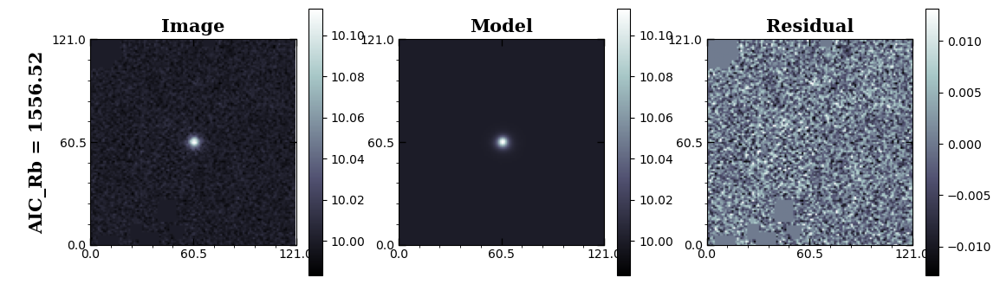

In [87]:
galid=4

ResGal=MC2_r_2comp_n_all.result(galid=galid, group_id=None)
ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=True) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]]
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]
print(fn)

MC2_r_2comp_n_all.drawing(galid=galid, fn=fn)
plt.show()
# MC2_1Comp_gm.drawing_legacy(galid=galid)

## Fit the r band using the best g-band structure

`SettingForBest` creates one r-band trial for each g-band model group. It copies the best g-band structural parameters and permits only the magnitude to change. This tests the same morphology in another band without independently refitting positions, radii, Sérsic indices, axis ratios, or position angles.

Both the normal best fit and the best warning-inclusive fit may be generated; duplicate or unavailable cases are skipped internally.

In [88]:
MC2_rg_2comp=copy.deepcopy(MC2_g_2comp)
MC2_rg_2comp.class_update_keys(proj_folder='rg_2comp/',           ## Folder name for this fit
                             fni_image = 'image_lr.fits',      ## image name (in DI.dir_work_list)
                             fni_sigma = 'sigma_lr.fits',      ## sigma name (in DI.dir_work_list)
                             fni_psf = 'psf_model_lr.fits',    ## psf name (in DI.dir_work_list)
                             re_lim_list = psf_lim_r
                             )

## Get the best results from the given ResPack, and use those as the fitting.
## All fitting parameter, except for the brightness, will be fixed.
## Only magnitude will be changed.
MC2_Pipelines_rg_2comp=dhmc2fit.SettingForBest(MC2_rg_2comp, ResPack_g_2Comp_t, DIgood) ## I will use the 'total' one

Setting completed


In [89]:
# Run one r-band fit for each selected g-band model group.
# Internally, unavailable and duplicate warning-inclusive cases are skipped.
MC2_Pipelines_rg_2comp.run_sets()



Stage 0
>> Get submodels: 0
>> Group index: 0
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 6.2 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.0 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



Stage 1
>> Get submodels: 1
>> Group index: 1
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

... (7 outputs left out)

partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.9 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.0 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



In [90]:
# Extract model images and compute both standard and aperture-specific statistics.
MC2_Pipelines_rg_2comp.extract()
MC2_Pipelines_rg_2comp.postprocessing()
MC2_Pipelines_rg_2comp.postprocessing(stat_radius_array_set=stat_radius_array_r,
                           stat_item_namelist=stat_item_name_array) ## additional Stat regions


======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 3.2 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



Remove files:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.0 s
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0226/rg_2comp/result_best_0.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0230/rg_2comp/result_best_0.fits
>> Warning! No safe_itemlist!

Loop 203: FileNotFoundError: [Errno 2] No such file or directory: './gal_out/gal0226/rg_2comp/done_post.dat'
Traceback (most recent call last):
  File "/home/donghyeon/ua/core_code/DH_multicore.py", line 117, in _multicore_worker
    return i, loop_ftn(i), None
              ~~~~~~~~^^^
  File "/home/donghyeon/ua/core_code/DH_MC2fit.py", line 2486, in _postprocessing_mulcore_loop
    return _postprocessing_mulcore_worker(
        i,
        config,
    )
  File "/home/donghyeon/ua/core_code/DH_MC2fit.py", line 2473, in _postprocessing_mulcore_worker
    np.savetxt(
    ~~~~~~~~~~^
        fn_done,
        ^^^^^^^^
        np.array(["done"]),
        ^^^^^^^^^^^^^^^^^^^
        fmt="%s",
        ^^^^^^^^^
    )
    ^
  File "/home/donghyeon/anaconda3/envs/

partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0226/rg_2comp/result_best_0.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0230/rg_2comp/result_best_0.fits
>> Warning! No safe_itemlist!

Loop 203: FileNotFoundError: [Errno 2] No such file or directory: './gal_out/gal0226/rg_2comp/done_post.dat'
Traceback (most recent call last):
  File "/home/donghyeon/ua/core_code/DH_multicore.py", line 117, in _multicore_worker
    return i, loop_ftn(i), None
              ~~~~~~~~^^^
  File "/home/donghyeon/ua/core_code/DH_MC2fit.py", line 2486, in _postprocessing_mulcore_loop
    return _postprocessing_mulcore_worker(
        i,
        config,
    )
  File "/home/donghyeon/ua/core_code/DH_MC2fit.py", line 2473, in _postprocessing_mulcore_worker
    np.savetxt(
    ~~~~~~~~~~^
        fn_done,
        ^^^^^^^^
        np.array(["done"]),
        ^^^^^^^^^^^^^^^^^^^
        fmt="%s",
        ^^^^^^^^^
    )
    ^
  File "/home/donghyeon/anaconda3/envs/

,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
best_0,0.000000,0.000000,62.090900,61.401800,26.430500,17.248800,10.000000,19.649100,nan,nan,nan,nan,nan,nan,0.728642,0.728642,10131.396429,1.000000,0.760591,5859.791224,1.000000,2009.650538,0.961051,829.214508,0.000000
best_1,10.000000,0.000000,62.035600,61.456300,25.355000,6.159900,10.000000,21.644600,62.101400,61.395700,24.309700,4.580100,10.000000,20.515000,0.705198,0.705198,9806.844307,1.000000,0.720784,5554.595261,1.000000,1707.447462,1.000000,559.499741,0.196935
best_2,20.000000,0.000000,59.393100,60.620200,29.075900,44.143400,9.903600,21.638200,62.156500,61.460800,nan,nan,nan,21.046900,0.696361,0.696361,9684.022728,1.000000,0.705576,5437.528257,1.000000,1588.453855,1.000000,453.761992,0.994200
best_3,30.000000,0.000000,62.095400,61.429000,nan,nan,nan,20.956300,nan,nan,nan,nan,nan,nan,0.700391,0.700391,9738.728503,1.000000,0.713066,5493.893067,1.000000,1641.435146,1.000000,505.977025,0.777392


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
best_0,0.000000,0.000000,62.090900,61.401800,26.430500,17.248800,10.000000,0.712300,67.958700,19.649100,nan,nan,nan,nan,nan,nan,nan,nan,0.728642,0.728642,10131.396429,1.000000,0.760591,5859.791224,1.000000,2009.650538,0.961051,829.214508,0.000000
best_1,10.000000,0.000000,62.035600,61.456300,25.355000,6.159900,10.000000,0.330100,-44.195800,21.644600,62.101400,61.395700,24.309700,4.580100,10.000000,0.645300,61.053100,20.515000,0.705198,0.705198,9806.844307,1.000000,0.720784,5554.595261,1.000000,1707.447462,1.000000,559.499741,0.196935
best_2,20.000000,0.000000,59.393100,60.620200,29.075900,44.143400,9.903600,0.200000,58.314100,21.638200,62.156500,61.460800,nan,nan,nan,nan,nan,21.046900,0.696361,0.696361,9684.022728,1.000000,0.705576,5437.528257,1.000000,1588.453855,1.000000,453.761992,0.994200
best_3,30.000000,0.000000,62.095400,61.429000,nan,nan,nan,nan,nan,20.956300,nan,nan,nan,nan,nan,nan,nan,nan,0.700391,0.700391,9738.728503,1.000000,0.713066,5493.893067,1.000000,1641.435146,1.000000,505.977025,0.777392


./gal_out/gal0004/rg_2comp/result_best_3.fits


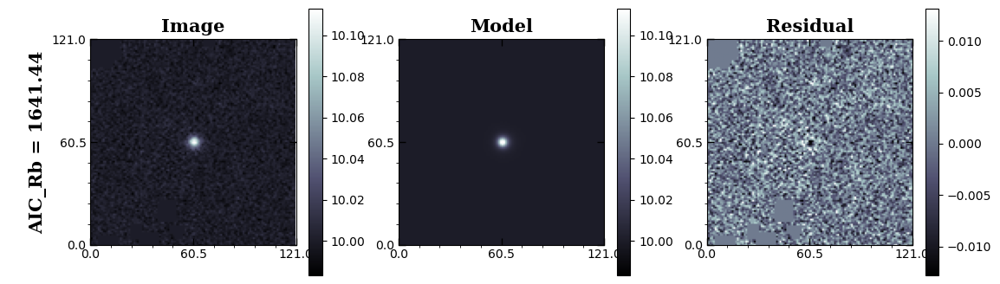

In [181]:
galid=4

ResGal=MC2_Pipelines_rg_2comp.result(galid=galid, group_id=None)
ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=True) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]]
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]
print(fn)

MC2_Pipelines_rg_2comp.drawing(galid=galid, fn=fn)
plt.show()
# MC2_Pipelines_rg_2comp.drawing_legacy(galid=galid)

In [91]:
ResPack_rg_2Comp=MC2_Pipelines_rg_2comp.pack_result()
pickle.dump(ResPack_rg_2Comp, open(DIgood.dir_base+"ResPack_rg_2Comp.pkl", "wb"))
ResPack_rg_2Comp=pickle.load(open(DIgood.dir_base+"ResPack_rg_2Comp.pkl", "rb"))
ResPack_rg_2Comp.preset_generate_onlyval(is_mag=False)

Pack the results
>> comp_crit: AIC_Rb
>> backend: thread
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0226/rg_2comp/result_best_0.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0230/rg_2comp/result_best_0.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
Done! | Time: 2.4 s
>> Get all submodels


# 3-componemt fitting

This stage extends selected two-component solutions by adding a third galaxy component. Two model families are tested:

- `sersic2 + sersic2 + psf` (`group_id=5`)
- `sersic2 + psf + psf` (`group_id=6`)

The first two galaxy components are initialized from the best corresponding two-component fit. The third component is then added with several magnitude offsets to reduce sensitivity to a single initial guess.

> **Component numbering:** the parameter arrays contain only galaxy components, so array indices `0`, `1`, and `2` correspond to the first, second, and third galaxy components. In the GALFIT configuration file, these are Components 2, 3, and 4 because Component 1 is the sky.


## Load the data

In [113]:
ResPack_g_2Comp_t=pickle.load(open(DIgood.dir_base+"ResPack_g_2Comp_t.pkl", "rb"))
ResPack_g_2Comp_t.preset_generate_onlyval(is_mag=False)

ResPack_r_2Comp_t=pickle.load(open(DIgood.dir_base+"ResPack_r_2Comp_t.pkl", "rb"))
ResPack_r_2Comp_t.preset_generate_onlyval(is_mag=False)

>> Get all submodels
>> Get all submodels


## g-band regular

In [114]:
MC2_g_3comp=dhmc2fit.Setting(proj_folder='g_3comp/',           ## Folder name for this fit
                             fni_image = 'image_lg.fits',      ## image name (in DI.dir_work_list)
                             fni_sigma = 'sigma_lg.fits',      ## sigma name (in DI.dir_work_list)
                             fni_psf = 'psf_model_lg.fits',    ## psf name (in DI.dir_work_list)
                             fni_masking= 'masking_c_nb.fits', ## mask name (in DI.dir_work_list)
                             use_sky_grad=False,               ## Gradient Sky (False: Flat sky)
                             image_size = image_size,          ## Image size
                             plate_scale=plate_scale,          ## Plate scale
                             est_sky=est_sky,                  ## Estimated sky value 
                             Ncore=Ncore,                       ## Number of cores
                             stat_itemlist=['CHI2NU', 'RChi_F', 'AIC_F', 'LIK_F', 'RChi_50', 'AIC_50', 'LIK_50',
                                            'AIC_Rb', 'LIK_Rb', 'AIC_hRb', 'LIK_hRb' ## List of statistics within Re and 0.5 Re
                                           ],
                             comp_crit='AIC_Rb',
                             re_lim_list=psf_lim_g,
                          )

Setting completed


### Runlist

Each Runlist stores offsets relative to the per-galaxy parameters supplied later through `base_params_array_set`.

The seven parameter columns are ordered as:

`[x, y, magnitude, effective radius, Sérsic index, axis ratio, position angle]`

With `base_params_add=True`, zero means “keep the previous fitted value,” while a nonzero magnitude entry is added to the previous magnitude. For the newly added component, the base array provides its absolute starting values and the Runlist supplies the trial magnitude offsets.


#### Sersic+Sersic+PSF (group_id=5)

In [115]:
## Variation in their magnitude
mag_offset3 = np.arange(-3, 4, 3) ## mag variation for Comp3 (2nd comp for the gal) ** Comp1 is the Sky
mag_offset4 = np.arange(-3, 4, 3) ## mag variation for Comp4 (3rd comp for the gal)
mag_offset4=mag_offset4[mag_offset4!=0]

## Make a name list. p is for positive, m is for negative. p3m3 means +3 and -3
mag_offset3_str = [f"p{abs(x)}" if x >= 0 else f"m{abs(x)}" for x in mag_offset3]
mag_offset4_str = [f"p{abs(x)}" if x >= 0 else f"m{abs(x)}" for x in mag_offset4]

##===========================================
for i, this_offset3 in enumerate(mag_offset3):
    ## Double Sersic + PSF
    namelist=dharray.array_attach_string(mag_offset4_str, 'ssp_fo_'+str(mag_offset3_str[i]), add_at_head=True)
    ## For the first part of the namelist, we will use the model components (here, ss is for double Sersic)
    ## For the second part, we will use the other configuration (f is for full image, o is for original)

    ## Estimated parameters are slightly different from the 1 comp case
    ## Here, I want to use the result of the 1 comp case as the initial guess. 
    ## Thus, I would like to input the "offset" value from the 1 comp case. Those values will be added to the previous fitting results.
    ## However, you can also 'replace' instead of 'add' by using base_params_add == False. See 'update_Class' later.
    est_params_array=np.array([[0, 0, 0, 0, 0, 0, 0],  ## Comp2 (1st comp for the gal): No variation
                               [0, 0, this_offset3, 0, 0, 0, 0],   ## Comp3 (2nd comp for the gal). This will be added --> All values = 0 except for est_mag.
                               [0, 0, mag_offset4, 0, 0, 0, 0],   ## Comp4 
                              ],  
                              dtype='object') 
    
    Runlist3Comp_Part_g5_raw=dhmc2fit.Runlist(namelist=namelist, complist=['sersic2','sersic2','psf'], ## Input the name list and component list.
                                            est_params_array=est_params_array,                ## Initial guess
                                            group_id=5,                                       ## Fitting group. 
                                            size_conv=image_size,                                    ## Convolution box size    
                                            lim_pos=np.array([[51, 71], [51, 71], [51, 71]]),         ## Position constraint (from - to)
                                            lim_n=[[0, 10], [0.1, 10], [0.1, 10]],                       ## Sersic index constraint (from - to)  
                                            lim_reff=None,                                    ## Effective radii constraint
                                            lim_ar=[[0.2, 1.1], [0.3, 1.1], [0.3, 1.1]],                  ## Axis ratio constraint (from - to)
                                            )
    if(i==0): Runlist3Comp_Part_g5=copy.deepcopy(Runlist3Comp_Part_g5_raw)
    else: Runlist3Comp_Part_g5.add_runlist(Runlist3Comp_Part_g5_raw)
Runlist3Comp_Part_g5.show_runlist()

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,ssp_fo_m3m3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, -3.0, -3","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5
1,ssp_fo_m3p3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, -3.0, 3.","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5
2,ssp_fo_p0m3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, -3.","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5
3,ssp_fo_p0p3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 3.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5
4,ssp_fo_p3m3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 3.0, -3.","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5
5,ssp_fo_p3p3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 3.0, 3.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5


#### Sersic+PSF+PSF (group_id=6)

In [116]:
## Variation in their magnitude
mag_offset3 = np.arange(-3, 4, 3) ## mag variation for Comp3 (2nd comp for the gal) ** Comp1 is the Sky
mag_offset4 = np.arange(-3, 4, 3) ## mag variation for Comp4 (3rd comp for the gal)
mag_offset4=mag_offset4[mag_offset4!=0]

## Make a name list. p is for positive, m is for negative. p3m3 means +3 and -3
mag_offset3_str = [f"p{abs(x)}" if x >= 0 else f"m{abs(x)}" for x in mag_offset3]
mag_offset4_str = [f"p{abs(x)}" if x >= 0 else f"m{abs(x)}" for x in mag_offset4]

##===========================================
for i, this_offset3 in enumerate(mag_offset3):
    ## Double Sersic + PSF
    namelist=dharray.array_attach_string(mag_offset4_str, 'spp_fo_'+str(mag_offset3_str[i]), add_at_head=True)
    ## For the first part of the namelist, we will use the model components (here, ss is for double Sersic)
    ## For the second part, we will use the other configuration (f is for full image, o is for original)

    ## Estimated parameters are slightly different from the 1 comp case
    ## Here, I want to use the result of the 1 comp case as the initial guess. 
    ## Thus, I would like to input the "offset" value from the 1 comp case. Those values will be added to the previous fitting results.
    ## However, you can also 'replace' instead of 'add' by using base_params_add == False. See 'update_Class' later.
    est_params_array=np.array([[0, 0, 0, 0, 0, 0, 0],  ## Comp2 (1st comp for the gal): No variation
                               [0, 0, this_offset3, 0, 0, 0, 0],   ## Comp3 (2nd comp for the gal). This will be added --> All values = 0 except for est_mag.
                               [0, 0, mag_offset4, 0, 0, 0, 0],   ## Comp4 
                              ],  
                              dtype='object') 
    
    Runlist3Comp_Part_g6_raw=dhmc2fit.Runlist(namelist=namelist, complist=['sersic2','psf','psf'], ## Input the name list and component list.
                                            est_params_array=est_params_array,                ## Initial guess
                                            group_id=6,                                       ## Fitting group. 
                                            size_conv=image_size,                                    ## Convolution box size    
                                            lim_pos=np.array([[51, 71], [51, 71], [51, 71]]),         ## Position constraint (from - to)
                                            lim_n=[[0, 10], [0.1, 10], [0.1, 10]],                       ## Sersic index constraint (from - to)  
                                            lim_reff=None,                                    ## Effective radii constraint
                                            lim_ar=[[0.2, 1.1], [0.3, 1.1], [0.3, 1.1]],                  ## Axis ratio constraint (from - to)
                                            )
    if(i==0): Runlist3Comp_Part_g6=copy.deepcopy(Runlist3Comp_Part_g6_raw)
    else: Runlist3Comp_Part_g6.add_runlist(Runlist3Comp_Part_g6_raw)
Runlist3Comp_Part_g6.show_runlist()

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,spp_fo_m3m3,"[sersic2, psf, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, -3.0, -3","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,6
1,spp_fo_m3p3,"[sersic2, psf, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, -3.0, 3.","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,6
2,spp_fo_p0m3,"[sersic2, psf, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, -3.","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,6
3,spp_fo_p0p3,"[sersic2, psf, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 3.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,6
4,spp_fo_p3m3,"[sersic2, psf, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 3.0, -3.","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,6
5,spp_fo_p3p3,"[sersic2, psf, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 3.0, 3.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,6


#### Combine all

In [117]:
Runlist3Comp = copy.deepcopy(Runlist3Comp_Part_g5)
Runlist3Comp.add_runlist(Runlist3Comp_Part_g6)
Runlist3Comp.show_runlist()
MC2_g_3comp.update_Class(Runlist3Comp, DIgood)

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,ssp_fo_m3m3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, -3.0, -3","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5
1,ssp_fo_m3p3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, -3.0, 3.","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5
2,ssp_fo_p0m3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, -3.","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5
3,ssp_fo_p0p3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 3.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5
4,ssp_fo_p3m3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 3.0, -3.","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5
5,ssp_fo_p3p3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 3.0, 3.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5
6,spp_fo_m3m3,"[sersic2, psf, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, -3.0, -3","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,6
7,spp_fo_m3p3,"[sersic2, psf, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, -3.0, 3.","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,6
8,spp_fo_p0m3,"[sersic2, psf, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, -3.","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,6
9,spp_fo_p0p3,"[sersic2, psf, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 3.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0

### Run

The two model families must be initialized separately because they come from different two-component submodels:

- `group_id=5` starts from the best `Sérsic + Sérsic` result.
- `group_id=6` starts from the best `Sérsic + PSF` result.

`preset_generate_onlyval(submodel=...)` selects the best result for one model family and exposes its parameters as `thismodel_params_array`. A new `(N_target, 3, 7)` array is then created by copying the two existing components and appending one new component.




#### Run1 : Group ID=5

In [126]:
## Select the best Sérsic + Sérsic solution for each target
## `submodel=1` selects this model family rather than the global best across all families.
ResPack_g_2Comp_t.preset_generate_onlyval(submodel=1) ## Group ID=1: Sersic + Sersic

PrevRes_ssp_temp=copy.deepcopy(ResPack_g_2Comp_t.thismodel_params_array) ## previous result. Shape: N_Target(DI), Comp, item (7)

PrevRes_ssp=np.zeros((len(PrevRes_ssp_temp), 3, 7)) ## allocate parameters for three galaxy components
## Copy the two previously fitted galaxy components
PrevRes_ssp[:,:2,:]=copy.deepcopy(PrevRes_ssp_temp) ## copy 1st and 2nd comp
# PrevRes_ssp[:,0,:] --> Comp2 (1st comp for the gal). 
# PrevRes_ssp[:,1,:] --> Comp3 (2nd comp for the gal). 

## Initialize the new third galaxy component (GALFIT Component 4)
PrevRes_ssp[:,2,:]=np.nan # Reset all parameters of the newly added third galaxy component
PrevRes_ssp[:,2,0]=np.nan # NaN is converted to the default x position, normally the image center
PrevRes_ssp[:,2,1]=np.nan # NaN is converted to the default y position, normally the image center
PrevRes_ssp[:,2,2]=PrevRes_ssp[:,0,2] # Use the first galaxy component magnitude as the reference magnitude
PrevRes_ssp[:,2,3] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_ssp[:,2,4] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_ssp[:,2,5:] = np.nan # Set the other values as Nan (default value)

>> Get submodels: 1
>> Group index: 1


In [127]:
## Make a new Setting class
MC2_g_3comp_Part_ssp=copy.deepcopy(MC2_g_3comp)
MC2_g_3comp_Part_ssp.update_Class(Runlist3Comp_Part_g5, DIgood, 
                                  base_params_array_set=PrevRes_ssp,  ## Previous Galfit result array
                                  base_params_add=True            ## Add the offset to the previous result
                                  )

## Run galfit separately
MC2_g_3comp_Part_ssp.run()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 402.4 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



#### Run2 : Group ID=6

In [128]:
## Select the best Sérsic + PSF solution for each target
## `submodel=2` selects this model family rather than the global best across all families.
ResPack_g_2Comp_t.preset_generate_onlyval(submodel=2) ## Group ID=2: Sersic + PSF

PrevRes_spp_temp=copy.deepcopy(ResPack_g_2Comp_t.thismodel_params_array) ## previous result. Shape: N_Target(DI), Comp, item (7)

PrevRes_spp=np.zeros((len(PrevRes_spp_temp), 3, 7)) ## allocate parameters for three galaxy components
## Copy the two previously fitted galaxy components
PrevRes_spp[:,:2,:]=copy.deepcopy(PrevRes_spp_temp) ## copy 1st and 2nd comp
# PrevRes_ssp[:,0,:] --> Comp2 (1st comp for the gal). 
# PrevRes_ssp[:,1,:] --> Comp3 (2nd comp for the gal). 

## Initialize the new third galaxy component (GALFIT Component 4)
PrevRes_spp[:,2,:]=np.nan # Reset all parameters of the newly added third galaxy component
PrevRes_spp[:,2,0]=np.nan # NaN is converted to the default x position, normally the image center
PrevRes_spp[:,2,1]=np.nan # NaN is converted to the default y position, normally the image center
PrevRes_spp[:,2,2]=PrevRes_spp[:,0,2] # Use the first galaxy component magnitude as the reference magnitude
PrevRes_spp[:,2,3] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_spp[:,2,4] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_spp[:,2,5:] = np.nan # Set the other values as Nan (default value)

>> Get submodels: 2
>> Group index: 2


In [129]:
## Make a new Setting class
MC2_g_3comp_Part_spp=copy.deepcopy(MC2_g_3comp)
MC2_g_3comp_Part_spp.update_Class(Runlist3Comp_Part_g6, DIgood, 
                                  base_params_array_set=PrevRes_spp,  ## Previous Galfit result array
                                  base_params_add=True            ## Add the offset to the previous result
                                  )

## Run galfit separately
MC2_g_3comp_Part_spp.run()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 151.5 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



### Extract and evaluate the regular g-band results


`extract()` converts the GALFIT image blocks into the compact result files used by the analysis classes. `postprocessing()` first calculates the default statistics and is then called again with `stat_radius_array_g` to calculate the named statistics in additional radial regions. `pack_result()` gathers the per-target best-fit information into a single object that can be saved with `pickle`.


In [130]:
## Extract GALFIT outputs, calculate statistics, and package all g-band three-component results
MC2_g_3comp.extract()
MC2_g_3comp.postprocessing()
MC2_g_3comp.postprocessing(stat_radius_array_set=stat_radius_array_g,
                           stat_item_namelist=stat_item_name_array) ## repeat the statistics calculation in the user-defined radial regions

ResPack_g_3Comp=MC2_g_3comp.pack_result()
pickle.dump(ResPack_g_3Comp, open(DIgood.dir_base+"ResPack_g_3Comp.pkl", "wb"))
ResPack_g_3Comp=pickle.load(open(DIgood.dir_base+"ResPack_g_3Comp.pkl", "rb"))
ResPack_g_3Comp.preset_generate_onlyval(is_mag=False)

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 6.1 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



Remove files:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.0 s
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0211/g_3comp/result_ssp_fo_m3m3.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0226/g_3comp/result_ssp_fo_m3m3.fits
>> Warning! No safe_itemlist!
Done! | Time: 7.1 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0211/g_3comp/result_ssp_fo_m3m3.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0226/g_3comp/result_ssp_fo_m3m3.fits
>> Warning! No safe_itemlist!
Done! | Time: 7.5 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

Pack the results
>> comp_crit: AIC_Rb
>> backend: thread
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0211/g_3comp/result_ssp_fo_m3m3.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0226/g_3comp/result_ssp_fo_m3m3.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
Done! | Time: 3.5 s
>> Get all submodels


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_MAG,4_XC,4_YC,4_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
ssp_fo_m3m3,5.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
ssp_fo_m3p3,5.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
ssp_fo_p0m3,5.000000,1.000000,59.979100,60.511500,25.659000,2.540600,10.000000,23.975600,51.000000,71.000000,29.906700,38.219200,4.388800,23.214100,62.184500,61.466700,21.624900,0.700745,0.700745,9764.495995,1.000000,0.728802,5635.475748,1.000000,981.276781,1.000000,246.503171,0.999983
ssp_fo_p0p3,5.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
ssp_fo_p3m3,5.000000,0.000000,62.326100,60.287300,26.285700,3.461500,5.486400,23.674600,51.000000,71.000000,37.490700,18.424800,10.000000,31.504900,62.114000,61.508700,21.645700,0.701922,0.701922,9780.826932,1.000000,0.730746,5650.406890,1.000000,992.865199,1.000000,249.947224,0.999964
ssp_fo_p3p3,5.000000,0.000000,59.407300,60.246600,26.875800,2.691800,10.000000,24.348100,51.000000,71.000000,47.226500,50.537200,10.000000,39.049700,62.156600,61.468200,21.602700,0.701662,0.701662,9777.219280,1.000000,0.730295,5646.944616,1.000000,989.194051,1.000000,247.513552,0.999979
spp_fo_m3m3,6.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
spp_fo_m3p3,6.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
spp_fo_p0m3,6.000000,1.000000,59.447600,60.600800,30.606800,44.176900,9.454600,23.192300,59.110800,61.115900,nan,nan,nan,26.837400,62.160200,61.460600,21.604300,0.701251,0.701251,9766.306939,1.000000,0.729683,5637.125079,1.000000,980.090947,1.000000,238.888030,0.999989
spp_fo_p0p3,6.000000,0.000000,59.439600,60.576700,30.603900,44.272100,9.992500,23.155100,62.154700,61.460900,nan,nan,nan,21.603100,51.000000,71.000000,26.063600,0.701137,0.701137,9764.713992,1.000000,0.729481,5635.572563,1.000000,978.565183,1.000000,239.082978,0.999989


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,4_XC,4_YC,4_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
ssp_fo_p0m3,5.000000,1.000000,59.979100,60.511500,25.659000,2.540600,10.000000,0.300000,-89.842400,23.975600,51.000000,71.000000,29.906700,38.219200,4.388800,0.200000,82.053400,23.214100,62.184500,61.466700,21.624900,0.700745,0.700745,9764.495995,1.000000,0.728802,5635.475748,1.000000,981.276781,1.000000,246.503171,0.999983
spp_fo_p3m3,6.000000,1.000000,51.000000,66.861200,31.035400,121.000000,3.082700,0.201100,48.352500,22.018800,61.781100,61.399600,nan,nan,nan,nan,nan,22.207600,62.497000,61.474600,22.444900,0.700622,0.700622,9757.562423,1.000000,0.728759,5630.028783,1.000000,976.017977,1.000000,240.603232,0.999984


./gal_out/gal0004/g_3comp/result_spp_fo_p3m3.fits


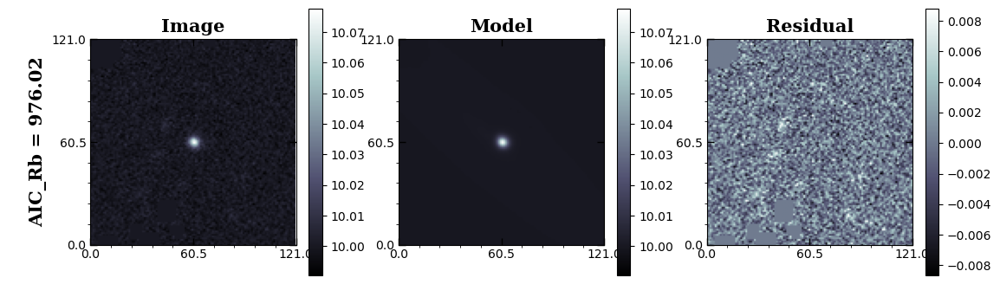

In [131]:
galid=4

ResGal=MC2_g_3comp.result(galid=galid, group_id=None)
ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=False) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]] ## avoid warning results if possible 
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]  ## Best results regardlenss of warning
print(fn)

MC2_g_3comp.drawing(galid=galid, fn=fn)
plt.show()
# MC2_g_3comp.drawing_legacy(galid=galid)

## g-band Combine

Here we will combine this result to the two-component results (and 1-comp included in the previous file as well)

In [134]:
MC2_g_3comp_t=copy.deepcopy(MC2_g_3comp)
## Create a result-only container that compares the new three-component fits with the existing lower-component fits
MC2_g_3comp_t.class_update_keys(proj_folder='g_3comp_t/', re_lim_list=psf_lim_g)

Runlist3Comp_tot = copy.deepcopy(MC2_g_3comp.RunlistClass)
Runlist3Comp_tot.add_runlist(MC2_g_2comp_t.RunlistClass) ## append the previously combined two- and one-component Runlist

## If you want to check the combined Runlist
#Runlist2Comp_tot.show_runlist() 

MC2_g_3comp_t.update_Class(Runlist3Comp_tot, DIgood)

## Link existing output files instead of rerunning GALFIT
res = dhfc.multicore_generate_link_galfit(DIgood, MC2_g_3comp, MC2_g_3comp_t)
res = dhfc.multicore_generate_link_galfit(DIgood, MC2_g_2comp_t, MC2_g_3comp_t)

Generate GALFIT links:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.0 s
Links created: 1607
Missing source files: 973


Generate GALFIT links:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.1 s
Links created: 6070
Missing source files: 5540


In [135]:
ResPack_g_3Comp_t=MC2_g_3comp_t.pack_result()
pickle.dump(ResPack_g_3Comp_t, open(DIgood.dir_base+"ResPack_g_3Comp_t.pkl", "wb"))
ResPack_g_3Comp_t=pickle.load(open(DIgood.dir_base+"ResPack_g_3Comp_t.pkl", "rb"))
ResPack_g_3Comp_t.preset_generate_onlyval(is_mag=False)

Pack the results
>> comp_crit: AIC_Rb
>> backend: thread
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0226/g_3comp_t/result_ssp_fo_m3m3.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
Done! | Time: 13.3 s
>> Get all submodels


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,4_XC,4_YC,4_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
s_fo_m3,0.000000,0.000000,61.673300,59.879900,20.419500,9.852000,1.294700,0.511300,85.654700,16.272700,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,2.519740,2.519740,35433.469835,0.000000,3.676972,28773.619349,0.000000,14797.676233,0.000000,7985.639908,0.000000
ss_mo_m3m3,1.000000,0.000000,61.578300,59.706300,20.677200,7.614100,0.473700,0.500700,85.480000,17.556200,61.740000,60.005000,21.595600,13.776600,1.909100,0.515500,85.718100,16.520000,nan,nan,nan,0.933776,0.933776,13148.650943,1.000000,1.084876,8507.282488,0.000000,2838.411176,0.000000,1637.300356,0.000000
sp_mo_p3p3,2.000000,0.000000,61.752300,59.871400,20.446100,9.864800,1.324000,0.516600,85.704100,16.274400,53.837700,60.670600,nan,nan,nan,nan,nan,21.785500,nan,nan,nan,2.344909,2.344909,32975.027244,0.000000,3.391998,26540.671428,0.000000,13322.159553,0.000000,7223.035847,0.000000
p_fo_m3,3.000000,0.000000,61.598400,59.885800,nan,nan,nan,nan,nan,18.219600,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,260.384500,260.384462,3661013.534303,0.000000,456.984757,3575913.728933,0.000000,3453547.422948,0.000000,2596879.451700,0.000000
ssp_fo_p0p3,5.000000,0.000000,61.598600,59.885700,20.545500,7.470400,0.530400,0.498600,85.549200,17.426100,61.731500,59.804600,21.753300,14.580000,1.782000,0.515900,85.694400,16.588400,61.914800,61.624900,21.613700,0.890676,0.890676,12546.485707,1.000000,1.008504,7913.508571,0.296238,2307.000279,0.000000,1308.677958,0.000000
spp_fo_m3m3,6.000000,1.000000,61.790000,59.834500,20.463300,9.929900,1.331100,0.515000,85.922400,16.278100,59.470700,63.077100,nan,nan,nan,nan,nan,22.165900,53.872200,60.802200,21.676900,2.288548,2.288549,32182.137533,0.000000,3.302357,25835.977387,0.000000,12891.919142,0.000000,6784.112632,0.000000


./gal_out/gal0012/g_3comp_t/result_ssp_fo_p0p3.fits


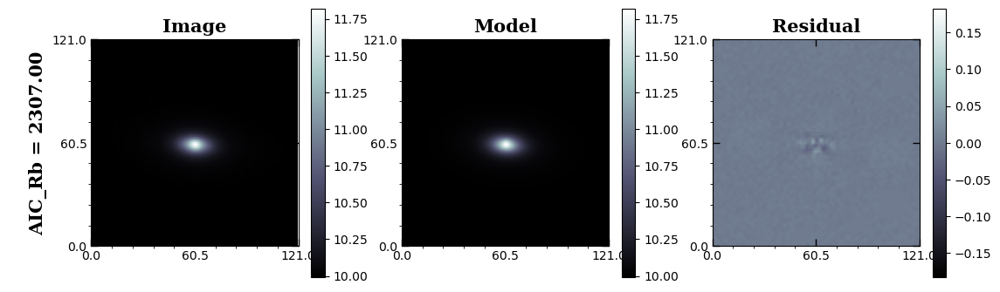

In [170]:
galid=11

ResGal=MC2_g_3comp_t.result(galid=galid, group_id=None)
#ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=False) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]] ## avoid warning results if possible 
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]  ## Best results regardlenss of warning
print(fn)

MC2_g_3comp_t.drawing(galid=galid, fn=fn)
plt.show()
# MC2_g_3comp_t.drawing_legacy(galid=galid)

## g-band fixed N

We will add a PSF to the previously N-fixed model results.

Except for the initial guesses, the overall structure is the same as the previous example.

In [145]:
ResPack_g_2Comp_n=pickle.load(open(DIgood.dir_base+"ResPack_g_2Comp_n.pkl", "rb"))
ResPack_g_2Comp_n.preset_generate_onlyval(is_mag=False)

>> Get all submodels
>> Get all submodels


In [146]:
MC2_g_3comp_n=copy.deepcopy(MC2_g_3comp)
MC2_g_3comp_n.class_update_keys(proj_folder='g_3comp_n/')

In [147]:
## Select the best Sérsic + Sérsic solution for each target
## `submodel=1` selects this model family rather than the global best across all families.
ResPack_g_2Comp_n.preset_generate_onlyval(submodel=1) ## Group ID=1: Sersic + Sersic

PrevRes_ssp_n_temp=copy.deepcopy(ResPack_g_2Comp_n.thismodel_params_array) ## previous result. Shape: N_Target(DI), Comp, item (7)

PrevRes_ssp_n=np.zeros((len(PrevRes_ssp_n_temp), 3, 7)) ## allocate parameters for three galaxy components
## Copy the two previously fitted galaxy components
PrevRes_ssp_n[:,:2,:]=copy.deepcopy(PrevRes_ssp_n_temp) ## copy 1st and 2nd comp
# PrevRes_ssp[:,0,:] --> Comp2 (1st comp for the gal). 
# PrevRes_ssp[:,1,:] --> Comp3 (2nd comp for the gal). 

## Initialize the new third galaxy component (GALFIT Component 4)
## We will add PSF, not Sersic. We don't need to fix Sersic index of 4
PrevRes_ssp_n[:,2,:]=np.nan # Reset all parameters of the newly added third galaxy component
PrevRes_ssp_n[:,2,0]=np.nan # NaN is converted to the default x position, normally the image center
PrevRes_ssp_n[:,2,1]=np.nan # NaN is converted to the default y position, normally the image center
PrevRes_ssp_n[:,2,2]=PrevRes_ssp_n[:,0,2] # Use the first galaxy component magnitude as the reference magnitude
PrevRes_ssp_n[:,2,3] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_ssp_n[:,2,4] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_ssp_n[:,2,5:] = np.nan # Set the other values as Nan (default value)

>> Get submodels: 1
>> Group index: 1


In [148]:
## Change the Runlist name
Runlist3Comp_Part_g5_n=copy.deepcopy(Runlist3Comp_Part_g5)  # Copy the Runlist class 
for i, text in enumerate(Runlist3Comp_Part_g5.runlist['name']):
    newtext=text.split("_")
    newtext[1]="n"+newtext[1][1:]   ## As an example, I used 'n' for 'sersic index (n)' instead of 'f'
    Runlist3Comp_Part_g5_n.runlist['name'][i]='_'.join(newtext)
Runlist3Comp_Part_g5_n.show_runlist()

## Make a new Setting class
MC2_g_3comp_Part_ssp_n=copy.deepcopy(MC2_g_3comp_n)
MC2_g_3comp_Part_ssp_n.update_Class(Runlist3Comp_Part_g5_n, DIgood, 
                                    base_params_array_set=PrevRes_ssp_n,  ## Previous Galfit result array
                                    is_allow_vary=[True, True, True, True, False, True, True], ## Fix Sersic indices
                                    base_params_add = [True, True, True, True, False, True, True], # Sersic indices are replaced
                                   )
## Run galfit separately
MC2_g_3comp_Part_ssp_n.run()

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,ssp_no_m3m3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, -3.0, -3","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5
1,ssp_no_m3p3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, -3.0, 3.","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5
2,ssp_no_p0m3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, -3.","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5
3,ssp_no_p0p3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 3.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5
4,ssp_no_p3m3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 3.0, -3.","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5
5,ssp_no_p3p3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 3.0, 3.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5


======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 337.8 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



In [149]:
## Select the best Sérsic + Sérsic solution for each target
## `submodel=1` selects this model family rather than the global best across all families.
ResPack_g_2Comp_n.preset_generate_onlyval(submodel=2) ## Group ID=1: Sersic + Sersic

PrevRes_spp_n_temp=copy.deepcopy(ResPack_g_2Comp_n.thismodel_params_array) ## previous result. Shape: N_Target(DI), Comp, item (7)

PrevRes_spp_n=np.zeros((len(PrevRes_spp_n_temp), 3, 7)) ## allocate parameters for three galaxy components
## Copy the two previously fitted galaxy components
PrevRes_spp_n[:,:2,:]=copy.deepcopy(PrevRes_spp_n_temp) ## copy 1st and 2nd comp
# PrevRes_ssp[:,0,:] --> Comp2 (1st comp for the gal). 
# PrevRes_ssp[:,1,:] --> Comp3 (2nd comp for the gal). 

## Initialize the new third galaxy component (GALFIT Component 4)
## We will add PSF, not Sersic. We don't need to fix Sersic index of 4
PrevRes_spp_n[:,2,:]=np.nan # Reset all parameters of the newly added third galaxy component
PrevRes_spp_n[:,2,0]=np.nan # NaN is converted to the default x position, normally the image center
PrevRes_spp_n[:,2,1]=np.nan # NaN is converted to the default y position, normally the image center
PrevRes_spp_n[:,2,2]=PrevRes_spp_n[:,0,2] # Use the first galaxy component magnitude as the reference magnitude
PrevRes_spp_n[:,2,3] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_spp_n[:,2,4] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_spp_n[:,2,5:] = np.nan # Set the other values as Nan (default value)

>> Get submodels: 2
>> Group index: 2


In [150]:
## Change the Runlist name
Runlist3Comp_Part_g6_n=copy.deepcopy(Runlist3Comp_Part_g6)  # Copy the Runlist class 
for i, text in enumerate(Runlist3Comp_Part_g6.runlist['name']):
    newtext=text.split("_")
    newtext[1]="n"+newtext[1][1:]   ## As an example, I used 'n' for 'sersic index (n)' instead of 'f'
    Runlist3Comp_Part_g6_n.runlist['name'][i]='_'.join(newtext)
Runlist3Comp_Part_g6_n.show_runlist()

## Make a new Setting class
MC2_g_3comp_Part_spp_n=copy.deepcopy(MC2_g_3comp_n)
MC2_g_3comp_Part_spp_n.update_Class(Runlist3Comp_Part_g6_n, DIgood, 
                                    base_params_array_set=PrevRes_spp_n,  ## Previous Galfit result array
                                    is_allow_vary=[True, True, True, True, False, True, True], ## Fix Sersic indices
                                    base_params_add = [True, True, True, True, False, True, True], # Sersic indices are replaced
                                   )
## Run galfit separately
MC2_g_3comp_Part_spp_n.run()

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,spp_no_m3m3,"[sersic2, psf, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, -3.0, -3","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,6
1,spp_no_m3p3,"[sersic2, psf, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, -3.0, 3.","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,6
2,spp_no_p0m3,"[sersic2, psf, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, -3.","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,6
3,spp_no_p0p3,"[sersic2, psf, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 3.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,6
4,spp_no_p3m3,"[sersic2, psf, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 3.0, -3.","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,6
5,spp_no_p3p3,"[sersic2, psf, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 3.0, 3.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,6


======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 128.6 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



In [152]:
Runlist3Comp_n = copy.deepcopy(Runlist3Comp_Part_g5_n)
Runlist3Comp_n.add_runlist(Runlist3Comp_Part_g6_n)
Runlist3Comp_n.show_runlist()
MC2_g_3comp_n.update_Class(Runlist3Comp_n, DIgood)

MC2_g_3comp_n.extract()
MC2_g_3comp_n.postprocessing()
MC2_g_3comp_n.postprocessing(stat_radius_array_set=stat_radius_array_g,
                           stat_item_namelist=stat_item_name_array) ## additional Stat regions

ResPack_g_3Comp_n=MC2_g_3comp_n.pack_result()
pickle.dump(ResPack_g_3Comp_n, open(DIgood.dir_base+"ResPack_g_3Comp_n.pkl", "wb"))
ResPack_g_3Comp_n=pickle.load(open(DIgood.dir_base+"ResPack_g_3Comp_n.pkl", "rb"))
ResPack_g_3Comp_n.preset_generate_onlyval(is_mag=False)

,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,ssp_no_m3m3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, -3.0, -3","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5
1,ssp_no_m3p3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, -3.0, 3.","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5
2,ssp_no_p0m3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, -3.","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5
3,ssp_no_p0p3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 3.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5
4,ssp_no_p3m3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 3.0, -3.","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5
5,ssp_no_p3p3,"[sersic2, sersic2, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 3.0, 3.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,5
6,spp_no_m3m3,"[sersic2, psf, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, -3.0, -3","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,6
7,spp_no_m3p3,"[sersic2, psf, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, -3.0, 3.","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,6
8,spp_no_p0m3,"[sersic2, psf, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, -3.","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(51.0 71.0), (51.0 71.0), (51.0 71.0)","(nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan)","(0.0 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan)",True,6
9,spp_no_p0p3,"[sersic2, psf, psf]",3,"0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 3.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0, 0.0, 0.0","0.0

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 6.4 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



Remove files:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.0 s
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


... (2 outputs left out)

partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0062/g_3comp_n/result_ssp_no_m3m3.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0212/g_3comp_n/result_ssp_no_m3m3.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0220/g_3comp_n/result_ssp_no_m3m3.fits
>> Warning! No safe_itemlist!
Done! | Time: 7.9 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

Pack the results
>> comp_crit: AIC_Rb
>> backend: thread
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0062/g_3comp_n/result_ssp_no_m3m3.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0212/g_3comp_n/result_ssp_no_m3m3.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0220/g_3comp_n/result_ssp_no_m3m3.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
Done! | Time: 3.6 s
>> Get all submodels


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_MAG,4_XC,4_YC,4_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
ssp_no_m3m3,5.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
ssp_no_m3p3,5.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
ssp_no_p0m3,5.000000,0.000000,61.727800,60.172400,25.460100,4.428900,1.000000,24.191300,64.282900,68.295600,27.483200,2.420000,4.000000,26.391400,62.101600,61.482400,21.622100,0.701498,0.701498,9772.334810,1.000000,0.730011,5642.209084,1.000000,983.723831,1.000000,241.820203,0.999989
ssp_no_p0p3,5.000000,0.000000,61.923500,60.827100,23.047800,2.420000,1.000000,23.038400,51.000000,71.000000,28.902200,15.674200,4.000000,23.753600,62.114200,61.557300,21.808800,0.701223,0.701223,9768.516372,1.000000,0.729660,5639.507996,1.000000,984.252153,1.000000,249.316388,0.999942
ssp_no_p3m3,5.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
ssp_no_p3p3,5.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
spp_no_m3m3,6.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
spp_no_m3p3,6.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
spp_no_p0m3,6.000000,1.000000,51.000000,71.000000,26.879400,9.714200,1.000000,23.905000,59.174500,60.914000,nan,nan,nan,24.654900,62.206700,61.445700,21.606100,0.700016,0.700016,9747.853417,1.000000,0.727453,5618.708924,1.000000,965.620495,1.000000,233.789671,0.999996
spp_no_p0p3,6.000000,1.000000,51.000000,71.000000,27.054100,10.546100,1.000000,23.901300,55.058300,56.967300,nan,nan,nan,26.343200,62.099200,61.427400,21.566500,0.700383,0.700383,9752.939497,1.000000,0.728116,5623.804451,1.000000,970.707149,1.000000,239.302495,0.999984


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,4_XC,4_YC,4_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
s_fo_m3,0.000000,0.000000,62.090900,61.401800,27.204200,17.248800,10.000000,0.712300,67.958700,20.422800,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0.761490,0.761490,10595.387334,1.000000,0.837563,6459.390277,1.000000,1787.827352,0.000000,957.047633,0.000000
ss_fo_p0m3,1.000000,0.000000,62.035600,61.456300,26.582400,6.159900,10.000000,0.330100,-44.195800,22.872000,62.101400,61.395700,24.823200,4.580100,10.000000,0.645300,61.053100,21.028500,nan,nan,nan,0.726982,0.726982,10124.902436,1.000000,0.776205,5995.971656,1.000000,1330.378576,0.123175,546.252002,0.000000
sp_mo_p3m3,2.000000,0.000000,59.393100,60.620200,30.588600,44.143400,9.903600,0.200000,58.314100,23.150900,62.156500,61.460800,nan,nan,nan,nan,nan,21.602900,nan,nan,nan,0.701118,0.701118,9760.544361,1.000000,0.729404,5631.154193,1.000000,974.351458,1.000000,232.666304,0.999994
p_mo_m3,3.000000,0.000000,62.095400,61.429000,nan,nan,nan,nan,nan,21.565500,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0.701318,0.701318,9754.218437,1.000000,0.729571,5623.512256,1.000000,965.375620,1.000000,222.192781,0.999996
ssp_fo_p0m3,5.000000,1.000000,59.979100,60.511500,25.659000,2.540600,10.000000,0.300000,-89.842400,23.975600,51.000000,71.000000,29.906700,38.219200,4.388800,0.200000,82.053400,23.214100,62.184500,61.466700,21.624900,0.700745,0.700745,9764.495995,1.000000,0.728802,5635.475748,1.000000,981.276781,1.000000,246.503171,0.999983
spp_fo_p3m3,6.000000,1.000000,51.000000,66.861200,31.035400,121.000000,3.082700,0.201100,48.352500,22.018800,61.781100,61.399600,nan,nan,nan,nan,nan,22.207600,62.497000,61.474600,22.444900,0.700622,0.700622,9757.562423,1.000000,0.728759,5630.028783,1.000000,976.017977,1.000000,240.603232,0.999984


./gal_out/gal0004/g_3comp_n/result_spp_no_p0m3.fits


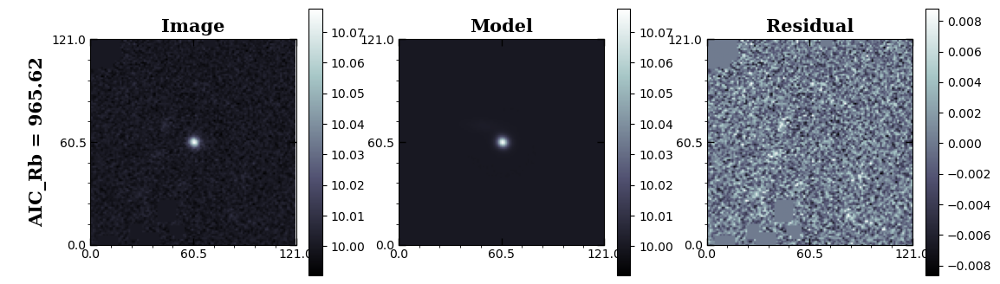

In [153]:
galid=4

ResGal=MC2_g_3comp_n.result(galid=galid, group_id=None)
ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=False) ## Show the summary
#ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]] ## avoid warning results if possible 
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]  ## Best results regardlenss of warning
print(fn)

MC2_g_3comp_n.drawing(galid=galid, fn=fn)
plt.show()
# MC2_g_3comp_n.drawing_legacy(galid=galid)

## r-band regular

In [154]:
MC2_r_3comp=copy.deepcopy(MC2_g_3comp)
MC2_r_3comp.class_update_keys(proj_folder='r_3comp/',           ## Folder name for this fit
                             fni_image = 'image_lr.fits',      ## image name (in DI.dir_work_list)
                             fni_sigma = 'sigma_lr.fits',      ## sigma name (in DI.dir_work_list)
                             fni_psf = 'psf_model_lr.fits',    ## psf name (in DI.dir_work_list)
                             re_lim_list = psf_lim_r
                             )

In [155]:
## Select the best Sérsic + Sérsic solution for each target
## `submodel=1` selects this model family rather than the global best across all families.
ResPack_r_2Comp_t.preset_generate_onlyval(submodel=1) ## Group ID=1: Sersic + Sersic

PrevRes_ssp_r_temp=copy.deepcopy(ResPack_r_2Comp_t.thismodel_params_array) ## previous result. Shape: N_Target(DI), Comp, item (7)

PrevRes_ssp_r=np.zeros((len(PrevRes_ssp_r_temp), 3, 7)) ## allocate parameters for three galaxy components
## Copy the two previously fitted galaxy components
PrevRes_ssp_r[:,:2,:]=copy.deepcopy(PrevRes_ssp_r_temp) ## copy 1st and 2nd comp
# PrevRes_ssp[:,0,:] --> Comp2 (1st comp for the gal). 
# PrevRes_ssp[:,1,:] --> Comp3 (2nd comp for the gal). 

## Initialize the new third galaxy component (GALFIT Component 4)
PrevRes_ssp_r[:,2,:]=np.nan # Reset all parameters of the newly added third galaxy component
PrevRes_ssp_r[:,2,0]=np.nan # NaN is converted to the default x position, normally the image center
PrevRes_ssp_r[:,2,1]=np.nan # NaN is converted to the default y position, normally the image center
PrevRes_ssp_r[:,2,2]=PrevRes_ssp_r[:,0,2] # Use the first galaxy component magnitude as the reference magnitude
PrevRes_ssp_r[:,2,3] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_ssp_r[:,2,4] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_ssp_r[:,2,5:] = np.nan # Set the other values as Nan (default value)

>> Get submodels: 1
>> Group index: 1


In [156]:
## Make a new Setting class
MC2_r_3comp_Part_ssp=copy.deepcopy(MC2_r_3comp)
MC2_r_3comp_Part_ssp.update_Class(Runlist3Comp_Part_g5, DIgood, 
                                  base_params_array_set=PrevRes_ssp_r,  ## Previous Galfit result array
                                  base_params_add=True            ## Add the offset to the previous result
                                  )

## Run galfit separately
MC2_r_3comp_Part_ssp.run()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 402.0 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



In [157]:
## Select the best Sérsic + PSF solution for each target
## `submodel=2` selects this model family rather than the global best across all families.
ResPack_r_2Comp_t.preset_generate_onlyval(submodel=2) ## Group ID=2: Sersic + PSF

PrevRes_spp_temp_r=copy.deepcopy(ResPack_r_2Comp_t.thismodel_params_array) ## previous result. Shape: N_Target(DI), Comp, item (7)

PrevRes_spp_r=np.zeros((len(PrevRes_spp_temp_r), 3, 7)) ## allocate parameters for three galaxy components
## Copy the two previously fitted galaxy components
PrevRes_spp_r[:,:2,:]=copy.deepcopy(PrevRes_spp_temp_r) ## copy 1st and 2nd comp
# PrevRes_ssp[:,0,:] --> Comp2 (1st comp for the gal). 
# PrevRes_ssp[:,1,:] --> Comp3 (2nd comp for the gal). 

## Initialize the new third galaxy component (GALFIT Component 4)
PrevRes_spp_r[:,2,:]=np.nan # Reset all parameters of the newly added third galaxy component
PrevRes_spp_r[:,2,0]=np.nan # NaN is converted to the default x position, normally the image center
PrevRes_spp_r[:,2,1]=np.nan # NaN is converted to the default y position, normally the image center
PrevRes_spp_r[:,2,2]=PrevRes_spp_r[:,0,2] # Use the first galaxy component magnitude as the reference magnitude
PrevRes_spp_r[:,2,3] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_spp_r[:,2,4] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_spp_r[:,2,5:] = np.nan # Set the other values as Nan (default value)

>> Get submodels: 2
>> Group index: 2


In [158]:
## Make a new Setting class
MC2_r_3comp_Part_spp=copy.deepcopy(MC2_r_3comp)
MC2_r_3comp_Part_spp.update_Class(Runlist3Comp_Part_g6, DIgood, 
                                  base_params_array_set=PrevRes_spp_r,  ## Previous Galfit result array
                                  base_params_add=True            ## Add the offset to the previous result
                                  )

## Run galfit separately
MC2_r_3comp_Part_spp.run()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 167.9 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



In [159]:
MC2_r_3comp.update_Class(Runlist3Comp, DIgood)

## Extract GALFIT outputs, calculate statistics, and package all g-band three-component results
MC2_r_3comp.extract()
MC2_r_3comp.postprocessing()
MC2_r_3comp.postprocessing(stat_radius_array_set=stat_radius_array_r,
                           stat_item_namelist=stat_item_name_array) ## repeat the statistics calculation in the user-defined radial regions

ResPack_r_3Comp=MC2_r_3comp.pack_result()
pickle.dump(ResPack_r_3Comp, open(DIgood.dir_base+"ResPack_r_3Comp.pkl", "wb"))
ResPack_r_3Comp=pickle.load(open(DIgood.dir_base+"ResPack_r_3Comp.pkl", "rb"))
ResPack_r_3Comp.preset_generate_onlyval(is_mag=False)

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 6.3 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



Remove files:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.0 s
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0226/r_3comp/result_ssp_fo_m3m3.fits
>> Warning! No safe_itemlist!
Done! | Time: 7.1 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0226/r_3comp/result_ssp_fo_m3m3.fits
>> Warning! No safe_itemlist!
Done! | Time: 7.6 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

Pack the results
>> comp_crit: AIC_Rb
>> backend: thread
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0226/r_3comp/result_ssp_fo_m3m3.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
Done! | Time: 3.6 s
>> Get all submodels


## r-band Combine

In [160]:
MC2_r_3comp_t=copy.deepcopy(MC2_r_3comp)
## Create a result-only container that compares the new three-component fits with the existing lower-component fits
MC2_r_3comp_t.class_update_keys(proj_folder='r_3comp_t/', re_lim_list=psf_lim_r)

MC2_r_3comp_t.update_Class(Runlist3Comp_tot, DIgood)

## Link existing output files instead of rerunning GALFIT
res = dhfc.multicore_generate_link_galfit(DIgood, MC2_r_3comp, MC2_r_3comp_t)
res = dhfc.multicore_generate_link_galfit(DIgood, MC2_r_2comp_t, MC2_r_3comp_t)

ResPack_r_3Comp_t=MC2_r_3comp_t.pack_result()
pickle.dump(ResPack_r_3Comp_t, open(DIgood.dir_base+"ResPack_r_3Comp_t.pkl", "wb"))
ResPack_r_3Comp_t=pickle.load(open(DIgood.dir_base+"ResPack_r_3Comp_t.pkl", "rb"))
ResPack_r_3Comp_t.preset_generate_onlyval(is_mag=False)

Generate GALFIT links:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.0 s
Links created: 1646
Missing source files: 934


Generate GALFIT links:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.1 s
Links created: 6009
Missing source files: 5601
Pack the results
>> comp_crit: AIC_Rb
>> backend: thread
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 13.8 s
>> Get all submodels


## Fit the r band using the best g-band structure

In [173]:
MC2_rg_3comp=copy.deepcopy(MC2_g_3comp)
MC2_rg_3comp.class_update_keys(proj_folder='rg_3comp/',           ## Folder name for this fit
                             fni_image = 'image_lr.fits',      ## image name (in DI.dir_work_list)
                             fni_sigma = 'sigma_lr.fits',      ## sigma name (in DI.dir_work_list)
                             fni_psf = 'psf_model_lr.fits',    ## psf name (in DI.dir_work_list)
                             re_lim_list = psf_lim_r
                             )

## Get the best results from the given ResPack, and use those as the fitting.
## All fitting parameter, except for the brightness, will be fixed.
## Only magnitude will be changed.
MC2_Pipelines_rg_3comp=dhmc2fit.SettingForBest(MC2_rg_3comp, ResPack_g_3Comp_t, DIgood) ## I will use the 'total' one

MC2_Pipelines_rg_3comp.run_sets()
MC2_Pipelines_rg_3comp.extract()
MC2_Pipelines_rg_3comp.postprocessing()
MC2_Pipelines_rg_3comp.postprocessing(stat_radius_array_set=stat_radius_array_r,
                           stat_item_namelist=stat_item_name_array) ## additional Stat regions

ResPack_rg_3Comp=MC2_Pipelines_rg_3comp.pack_result()
pickle.dump(ResPack_rg_2Comp, open(DIgood.dir_base+"ResPack_rg_3Comp.pkl", "wb"))
ResPack_rg_3Comp=pickle.load(open(DIgood.dir_base+"ResPack_rg_3Comp.pkl", "rb"))
ResPack_rg_3Comp.preset_generate_onlyval(is_mag=False)

Setting completed


Stage 0
>> Get submodels: 0
>> Group index: 0
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 7.2 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.0 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



Stage 1
>> Get submodels: 1
>> Group index: 1
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

... (25 outputs left out)

partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0226/rg_3comp/result_best_0.fits
>> Warning! No safe_itemlist!

Loop 203: FileNotFoundError: [Errno 2] No such file or directory: './gal_out/gal0226/rg_3comp/done_post.dat'
Traceback (most recent call last):
  File "/home/donghyeon/ua/core_code/DH_multicore.py", line 117, in _multicore_worker
    return i, loop_ftn(i), None
              ~~~~~~~~^^^
  File "/home/donghyeon/ua/core_code/DH_MC2fit.py", line 2486, in _postprocessing_mulcore_loop
    return _postprocessing_mulcore_worker(
        i,
        config,
    )
  File "/home/donghyeon/ua/core_code/DH_MC2fit.py", line 2473, in _postprocessing_mulcore_worker
    np.savetxt(
    ~~~~~~~~~~^
        fn_done,
        ^^^^^^^^
        np.array(["done"]),
        ^^^^^^^^^^^^^^^^^^^
        fmt="%s",
        ^^^^^^^^^
    )
    ^
  File "/home/donghyeon/anaconda3/envs/nb7-py313/lib/python3.13/site-packages/numpy/lib/_npyio_impl.py", line 1552, in savetxt
    open(fname, 'wt').close()

partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0226/rg_3comp/result_best_0.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
Done! | Time: 3.3 s
>> Get all submodels


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_MAG,4_XC,4_YC,4_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
best_0,0.000000,0.000000,62.090900,61.401800,26.430500,17.248800,10.000000,19.649100,nan,nan,nan,nan,nan,nan,nan,nan,nan,0.728642,0.728642,10131.396429,1.000000,0.760591,5859.791224,1.000000,2009.650538,0.961051,829.214508,0.000000
best_1,10.000000,0.000000,62.035600,61.456300,25.355000,6.159900,10.000000,21.644600,62.101400,61.395700,24.309700,4.580100,10.000000,20.515000,nan,nan,nan,0.705198,0.705198,9806.844307,1.000000,0.720784,5554.595261,1.000000,1707.447462,1.000000,559.499741,0.196935
best_2,20.000000,0.000000,59.393100,60.620200,29.075900,44.143400,9.903600,21.638200,62.156500,61.460800,nan,nan,nan,21.046900,nan,nan,nan,0.696361,0.696361,9684.022728,1.000000,0.705576,5437.528257,1.000000,1588.453855,1.000000,453.761992,0.994200
best_3,30.000000,0.000000,62.095400,61.429000,nan,nan,nan,20.956300,nan,nan,nan,nan,nan,nan,nan,nan,nan,0.700391,0.700391,9738.728503,1.000000,0.713066,5493.893067,1.000000,1641.435146,1.000000,505.977025,0.777392
best_4,50.000000,1.000000,59.979100,60.511500,24.324900,2.540600,10.000000,22.641500,51.000000,71.000000,29.234000,38.219200,4.388800,22.541400,62.184500,61.466700,21.073400,0.696195,0.696195,9683.030422,1.000000,0.705375,5437.278841,1.000000,1583.492746,1.000000,461.108115,0.989573
best_5,60.000000,0.000000,51.000000,66.861200,29.933300,121.000000,3.082700,20.916700,61.781100,61.399600,nan,nan,nan,21.689800,62.497000,61.474600,21.746000,0.697641,0.697641,9703.122131,1.000000,0.707405,5452.900190,1.000000,1601.379635,1.000000,476.188361,0.964273


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,4_XC,4_YC,4_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
best_0,0.000000,0.000000,62.090900,61.401800,26.430500,17.248800,10.000000,0.712300,67.958700,19.649100,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0.728642,0.728642,10131.396429,1.000000,0.760591,5859.791224,1.000000,2009.650538,0.961051,829.214508,0.000000
best_1,10.000000,0.000000,62.035600,61.456300,25.355000,6.159900,10.000000,0.330100,-44.195800,21.644600,62.101400,61.395700,24.309700,4.580100,10.000000,0.645300,61.053100,20.515000,nan,nan,nan,0.705198,0.705198,9806.844307,1.000000,0.720784,5554.595261,1.000000,1707.447462,1.000000,559.499741,0.196935
best_2,20.000000,0.000000,59.393100,60.620200,29.075900,44.143400,9.903600,0.200000,58.314100,21.638200,62.156500,61.460800,nan,nan,nan,nan,nan,21.046900,nan,nan,nan,0.696361,0.696361,9684.022728,1.000000,0.705576,5437.528257,1.000000,1588.453855,1.000000,453.761992,0.994200
best_3,30.000000,0.000000,62.095400,61.429000,nan,nan,nan,nan,nan,20.956300,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0.700391,0.700391,9738.728503,1.000000,0.713066,5493.893067,1.000000,1641.435146,1.000000,505.977025,0.777392
best_4,50.000000,1.000000,59.979100,60.511500,24.324900,2.540600,10.000000,0.300000,-89.842400,22.641500,51.000000,71.000000,29.234000,38.219200,4.388800,0.200000,82.053400,22.541400,62.184500,61.466700,21.073400,0.696195,0.696195,9683.030422,1.000000,0.705375,5437.278841,1.000000,1583.492746,1.000000,461.108115,0.989573
best_5,60.000000,0.000000,51.000000,66.861200,29.933300,121.000000,3.082700,0.201100,48.352500,20.916700,61.781100,61.399600,nan,nan,nan,nan,nan,21.689800,62.497000,61.474600,21.746000,0.697641,0.697641,9703.122131,1.000000,0.707405,5452.900190,1.000000,1601.379635,1.000000,476.188361,0.964273


./gal_out/gal0004/rg_3comp/result_best_3.fits


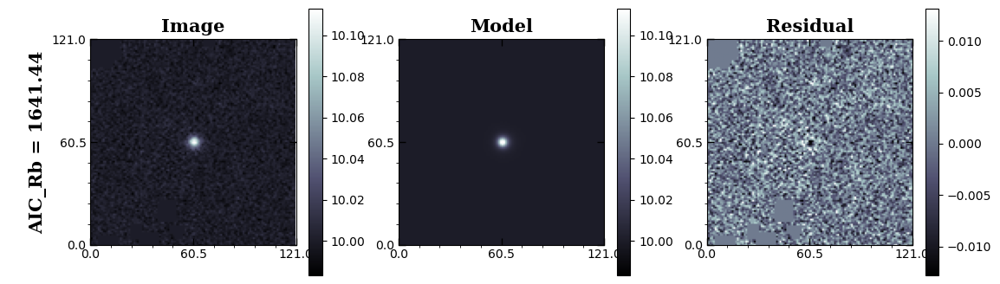

In [174]:
galid=4

ResGal=MC2_Pipelines_rg_3comp.result(galid=galid, group_id=None)
ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=True) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]]
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]
print(fn)

MC2_Pipelines_rg_3comp.drawing(galid=galid, fn=fn)
plt.show()
# MC2_Pipelines_rg_3comp.drawing_legacy(galid=galid)

## r-band fixed N

In [161]:
ResPack_r_2Comp_n=pickle.load(open(DIgood.dir_base+"ResPack_r_2Comp_n.pkl", "rb"))
ResPack_r_2Comp_n.preset_generate_onlyval(is_mag=False)

>> Get all submodels


In [162]:
MC2_r_3comp_n=copy.deepcopy(MC2_r_3comp)
MC2_r_3comp_n.class_update_keys(proj_folder='r_3comp_n/', re_lim_list=psf_lim_r)

In [164]:
## Select the best Sérsic + Sérsic solution for each target
## `submodel=1` selects this model family rather than the global best across all families.
ResPack_r_2Comp_n.preset_generate_onlyval(submodel=1) ## Group ID=1: Sersic + Sersic

PrevRes_ssp_r_n_temp=copy.deepcopy(ResPack_r_2Comp_n.thismodel_params_array) ## previous result. Shape: N_Target(DI), Comp, item (7)

PrevRes_ssp_r_n=np.zeros((len(PrevRes_ssp_r_n_temp), 3, 7)) ## allocate parameters for three galaxy components
## Copy the two previously fitted galaxy components
PrevRes_ssp_r_n[:,:2,:]=copy.deepcopy(PrevRes_ssp_r_n_temp) ## copy 1st and 2nd comp
# PrevRes_ssp[:,0,:] --> Comp2 (1st comp for the gal). 
# PrevRes_ssp[:,1,:] --> Comp3 (2nd comp for the gal). 

## Initialize the new third galaxy component (GALFIT Component 4)
## We will add PSF, not Sersic. We don't need to fix Sersic index of 4
PrevRes_ssp_r_n[:,2,:]=np.nan # Reset all parameters of the newly added third galaxy component
PrevRes_ssp_r_n[:,2,0]=np.nan # NaN is converted to the default x position, normally the image center
PrevRes_ssp_r_n[:,2,1]=np.nan # NaN is converted to the default y position, normally the image center
PrevRes_ssp_r_n[:,2,2]=PrevRes_ssp_r_n[:,0,2] # Use the first galaxy component magnitude as the reference magnitude
PrevRes_ssp_r_n[:,2,3] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_ssp_r_n[:,2,4] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_ssp_r_n[:,2,5:] = np.nan # Set the other values as Nan (default value)

>> Get submodels: 1
>> Group index: 1


In [165]:
## Make a new Setting class
MC2_r_3comp_Part_ssp_n=copy.deepcopy(MC2_r_3comp_n)
MC2_r_3comp_Part_ssp_n.update_Class(Runlist3Comp_Part_g5_n, DIgood, 
                                    base_params_array_set=PrevRes_ssp_r_n,  ## Previous Galfit result array
                                    is_allow_vary=[True, True, True, True, False, True, True], ## Fix Sersic indices
                                    base_params_add = [True, True, True, True, False, True, True], # Sersic indices are replaced
                                   )
## Run galfit separately
MC2_r_3comp_Part_ssp_n.run()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 334.9 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



In [168]:
## Select the best Sérsic + Sérsic solution for each target
## `submodel=1` selects this model family rather than the global best across all families.
ResPack_r_2Comp_n.preset_generate_onlyval(submodel=2) ## Group ID=1: Sersic + Sersic

PrevRes_spp_r_n_temp=copy.deepcopy(ResPack_r_2Comp_n.thismodel_params_array) ## previous result. Shape: N_Target(DI), Comp, item (7)

PrevRes_spp_r_n=np.zeros((len(PrevRes_spp_r_n_temp), 3, 7)) ## allocate parameters for three galaxy components
## Copy the two previously fitted galaxy components
PrevRes_spp_r_n[:,:2,:]=copy.deepcopy(PrevRes_spp_r_n_temp) ## copy 1st and 2nd comp
# PrevRes_ssp[:,0,:] --> Comp2 (1st comp for the gal). 
# PrevRes_ssp[:,1,:] --> Comp3 (2nd comp for the gal). 

## Initialize the new third galaxy component (GALFIT Component 4)
## We will add PSF, not Sersic. We don't need to fix Sersic index of 4
PrevRes_spp_r_n[:,2,:]=np.nan # Reset all parameters of the newly added third galaxy component
PrevRes_spp_r_n[:,2,0]=np.nan # NaN is converted to the default x position, normally the image center
PrevRes_spp_r_n[:,2,1]=np.nan # NaN is converted to the default y position, normally the image center
PrevRes_spp_r_n[:,2,2]=PrevRes_spp_r_n[:,0,2] # Use the first galaxy component magnitude as the reference magnitude
PrevRes_spp_r_n[:,2,3] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_spp_r_n[:,2,4] = 0 # Initial guess in the Runlist will be used (PSF will not be affected)
PrevRes_spp_r_n[:,2,5:] = np.nan # Set the other values as Nan (default value)

>> Get submodels: 2
>> Group index: 2


In [171]:
## Make a new Setting class
MC2_r_3comp_Part_spp_n=copy.deepcopy(MC2_r_3comp_n)
MC2_r_3comp_Part_spp_n.update_Class(Runlist3Comp_Part_g6_n, DIgood, 
                                    base_params_array_set=PrevRes_spp_r_n,  ## Previous Galfit result array
                                    is_allow_vary=[True, True, True, True, False, True, True], ## Fix Sersic indices
                                    base_params_add = [True, True, True, True, False, True, True], # Sersic indices are replaced
                                   )
## Run galfit separately
MC2_r_3comp_Part_spp_n.run()

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 127.0 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



In [172]:
MC2_r_3comp_n.update_Class(Runlist3Comp_n, DIgood)
MC2_r_3comp_n.extract()
MC2_r_3comp_n.postprocessing()
MC2_r_3comp_n.postprocessing(stat_radius_array_set=stat_radius_array_r,
                           stat_item_namelist=stat_item_name_array) ## additional Stat regions

ResPack_r_3Comp_n=MC2_r_3comp_n.pack_result()
pickle.dump(ResPack_r_3Comp_n, open(DIgood.dir_base+"ResPack_r_3Comp_n.pkl", "wb"))
ResPack_r_3Comp_n=pickle.load(open(DIgood.dir_base+"ResPack_r_3Comp_n.pkl", "rb"))
ResPack_r_3Comp_n.preset_generate_onlyval(is_mag=False)

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: True


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 6.4 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



Remove files:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.0 s
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0016/r_3comp_n/result_ssp_no_m3m3.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0057/r_3comp_n/result_ssp_no_m3m3.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0062/r_3comp_n/result_ssp_no_m3m3.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0182/r_3comp_n/result_ssp_no_m3m3.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0223/r_3comp_n/result_ssp_no_m3m3.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0237/r_3comp_n/result_ssp_no_m3m3.fits
>> Warning! No safe_itemlist!
Done! | Time: 7.1 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0016/r_3comp_n/result_ssp_no_m3m3.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0057/r_3comp_n/result_ssp_no_m3m3.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0062/r_3comp_n/result_ssp_no_m3m3.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0182/r_3comp_n/result_ssp_no_m3m3.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0223/r_3comp_n/result_ssp_no_m3m3.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0237/r_3comp_n/result_ssp_no_m3m3.fits
>> Warning! No safe_itemlist!
Done! | Time: 7.8 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215

Pack the results
>> comp_crit: AIC_Rb
>> backend: thread
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of 

partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0057/r_3comp_n/result_ssp_no_m3m3.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0062/r_3comp_n/result_ssp_no_m3m3.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0182/r_3comp_n/result_ssp_no_m3m3.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0223/r_3comp_n/result_ssp_no_m3m3.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0237/r_3comp_n/result_ssp_no_m3m3.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
Done! | Time: 3.6 s
>> Get all submodels


# 4 Comp fitting

In [56]:
ResPack_g_3Comp=pickle.load(open(DIgood.dir_base+"ResPack_g_3Comp.pkl", "rb"))
ResPack_g_3Comp.preset_generate_onlyval(is_mag=False)

>> Get all submodels


In [57]:
MC2_g_4comp=dhmc2fit.Setting(proj_folder='g_4comp/',           ## Folder name for this fit
                             fni_image = 'image_lg.fits',      ## image name (in DI.dir_work_list)
                             fni_sigma = 'sigma_lg.fits',      ## sigma name (in DI.dir_work_list)
                             fni_psf = 'psf_model_lg.fits',    ## psf name (in DI.dir_work_list)
                             fni_masking= 'masking_c_nb.fits', ## mask name (in DI.dir_work_list)
                             use_sky_grad=False,               ## Gradient Sky (False: Flat sky)
                             image_size = image_size,          ## Image size
                             plate_scale=plate_scale,          ## Plate scale
                             est_sky=est_sky,                  ## Estimated sky value 
                             Ncore=Ncore,                       ## Number of cores
                             stat_itemlist=['CHI2NU', 'RChi_F', 'AIC_F', 'LIK_F', 'RChi_50', 'AIC_50', 'LIK_50',
                                            'AIC_Rb', 'LIK_Rb', 'AIC_hRb', 'LIK_hRb' ## List of statistics within Re and 0.5 Re
                                           ],
                             comp_crit='AIC_hRb',
                             re_lim_list=psf_lim_g,
                                
                          )
MC2_g_4comp

Setting completed


Setting(proj_folder='g_4comp/', fn_galfit='/home/donghyeon/galfit3.0.7b/galfit', fni_image='image_lg.fits', fni_psf='psf_model_lg.fits', fni_masking='masking_c_nb.fits', fni_sigma='sigma_lg.fits', is_run_galfit_dir_work=False, est_sky=10, use_sky_grad=False, zeromag=22.5, plate_scale=array([0.262, 0.262]), image_size=array([121, 121]), re_lim_list=array([[  1.93820577, 121.        ],
       [  1.7807898 , 121.        ],
       [  2.47317867, 121.        ],
       [  2.73035869, 121.        ],
       [  2.42490034, 121.        ],
       [  2.02796205, 121.        ],
       [  1.97970105, 121.        ],
       [  2.35881189, 121.        ],
       [  2.74008628, 121.        ],
       [  2.31302999, 121.        ],
       [  2.6571365 , 121.        ],
       [  1.75111282, 121.        ],
       [  1.52491976, 121.        ],
       [  2.65014866, 121.        ],
       [  1.68864697, 121.        ],
       [  1.78237219, 121.        ],
       [  1.9183822 , 121.        ],
       [  1.81971533,

In [58]:
##================== Extended version ========================
## Variation in their magnitude
mag_offset4 = np.arange(-3, 4, 3) ## mag variation for Comp3 (2nd comp)
mag_offset5 = np.arange(-3, 4, 3) ## mag variation for Comp4 (3rd comp)
mag_offset5=mag_offset5[mag_offset5!=0]

mag_offset4_str = [f"p{abs(x)}" if x >= 0 else f"m{abs(x)}" for x in mag_offset4]
mag_offset5_str = [f"p{abs(x)}" if x >= 0 else f"m{abs(x)}" for x in mag_offset5]

for i, this_offset4 in enumerate(mag_offset4):
    ## Double Sersic + 2PSF
    namelist=dharray.array_attach_string(mag_offset5_str, 'sspp_fo_'+str(mag_offset4_str[i]), add_at_head=True)
    est_params_array=np.array([[0, 0, 0, 0, 0, 0, 0],
                               [0, 0, 0, 0, 0, 0, 0],
                               [0, 0, this_offset4, 0, 0, 0, 0],  ## This will be added --> All values = 0 except for est_mag.
                               [0, 0, mag_offset5, 0, 0, 0, 0]],  ## New data --> values = nan (default)
                              dtype='object') 
    # index                      [  0   |  1   |      2     |  3 | 4 |  5   |  6 ]
    # params                    [ xpos | ypos |     mag     |reff| n |  ar  |  pa]    
    Part_Runlist4Comp_sspp=dhmc2fit.Runlist(namelist=namelist, complist=['sersic2','sersic2','psf','psf'],
                                            est_params_array=est_params_array,
                                            group_id=7,  
                                            size_conv=201,
                                            lim_pos=np.array([[51, 71], [51, 71], [51, 71], [51, 71]]), ## position constraint (from - to)
                                            lim_n=[[0, 2], [0.1, 10], [0.1, 10], [0.1, 10]], 
                                            lim_reff=None,
                                            lim_ar=[[0.2, 1.1], [0.3, 1.1], [0.3, 1.1], [0.3, 1.1]],
                                            )
    if(i==0): Runlist4Comp_sspp=copy.deepcopy(Part_Runlist4Comp_sspp)
    else: Runlist4Comp_sspp.add_runlist(Part_Runlist4Comp_sspp)


Runlist4Comp_sspp.show_runlist()


,name,complist,ncomp,est_xpos,est_ypos,est_mag,est_reff,est_n,est_ar,est_pa,lim_xpos,lim_ypos,lim_mag,lim_reff,lim_n,lim_ar,lim_pa,use_lim,group_ID
0,sspp_fo_m3m3,"[sersic2, sersic2, psf, psf]",4,"0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","0.0, 0.0, -3.0, -3","0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0), (51.0 7...","(51.0 71.0), (51.0 71.0), (51.0 71.0), (51.0 7...","(nan nan), (nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan), (nan nan)","(0.0 2.0), (0.1 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan), (nan nan)",True,7
1,sspp_fo_m3p3,"[sersic2, sersic2, psf, psf]",4,"0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","0.0, 0.0, -3.0, 3.","0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0), (51.0 7...","(51.0 71.0), (51.0 71.0), (51.0 71.0), (51.0 7...","(nan nan), (nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan), (nan nan)","(0.0 2.0), (0.1 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan), (nan nan)",True,7
2,sspp_fo_p0m3,"[sersic2, sersic2, psf, psf]",4,"0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, -3.","0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0), (51.0 7...","(51.0 71.0), (51.0 71.0), (51.0 71.0), (51.0 7...","(nan nan), (nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan), (nan nan)","(0.0 2.0), (0.1 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan), (nan nan)",True,7
3,sspp_fo_p0p3,"[sersic2, sersic2, psf, psf]",4,"0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 3.0","0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0), (51.0 7...","(51.0 71.0), (51.0 71.0), (51.0 71.0), (51.0 7...","(nan nan), (nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan), (nan nan)","(0.0 2.0), (0.1 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan), (nan nan)",True,7
4,sspp_fo_p3m3,"[sersic2, sersic2, psf, psf]",4,"0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","0.0, 0.0, 3.0, -3.","0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0), (51.0 7...","(51.0 71.0), (51.0 71.0), (51.0 71.0), (51.0 7...","(nan nan), (nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan), (nan nan)","(0.0 2.0), (0.1 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan), (nan nan)",True,7
5,sspp_fo_p3p3,"[sersic2, sersic2, psf, psf]",4,"0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","0.0, 0.0, 3.0, 3.0","0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","0.0, 0.0, 0.0, 0.0","(51.0 71.0), (51.0 71.0), (51.0 71.0), (51.0 7...","(51.0 71.0), (51.0 71.0), (51.0 71.0), (51.0 7...","(nan nan), (nan nan), (nan nan), (nan nan)","(nan nan), (nan nan), (nan nan), (nan nan)","(0.0 2.0), (0.1 10.0), (0.1 10.0), (0.1 10.0)","(0.2 1.1), (0.3 1.1), (0.3 1.1), (0.3 1.1)","(nan nan), (nan nan), (nan nan), (nan nan)",True,7


In [59]:
ResPack_g_3Comp.preset_generate_onlyval(submodel=5) ## Sersic + Sersic + PSF
PrevRes_sspp_Temp=copy.deepcopy(ResPack_g_3Comp.thismodel_params_array) ## previous result. Shape: N_Target(DI), Comp, item (7)
PrevRes_sspp=np.zeros((len(PrevRes_sspp_Temp), 4, 7)) ## 4 components
PrevRes_sspp[:,:3,:]=copy.deepcopy(PrevRes_sspp_Temp)
# PrevRes_sspp[:,0,:] --> Comp2 (1st comp for the gal). 
# PrevRes_sspp[:,1,:] --> Comp3 (2nd comp for the gal). 
# PrevRes_sspp[:,2,:] --> Comp4 (3rd comp for the gal). 
PrevRes_sspp[:,3,:]=np.nan # Reset the parameters for Comp3 (2nd comp for the gal)
PrevRes_sspp[:,3,0]=np.nan # By using Nan for the position, the position will be set to the center of the image
PrevRes_sspp[:,3,1]=np.nan # By using Nan for the position, the position will be set to the center of the image
PrevRes_sspp[:,3,2]=PrevRes_sspp[:,0,2] # Copy the mag

## Update the Setting class
MC2_g_4comp.update_Class(Runlist4Comp_sspp, DIgood,
                         base_params_array_set=PrevRes_sspp,  ## Previous Galfit result array
                         base_params_add=True,            ## Add the offset to the previous result
                        )


>> Get submodels:  5
>> Group index:  0


In [121]:
MC2_g_4comp.run()

======== Multicore Briefing ========
● Multicore run for sub_run_process with Ncore 16
● Using Try (Ignoring Errors): True


100%|██████████████████████████████████| 215/215 [05:26<00:00,  1.52s/it]

Done! | Time :  326.44461274147034
======== Multicore summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning (w/failed): 0 / 215



In [60]:
MC2_g_4comp.extract()
MC2_g_4comp.postprocessing()
MC2_g_4comp.postprocessing(stat_radius_array_set=stat_radius_array_g,
                           stat_item_namelist=stat_item_name_array) ## additional Stat regions
ResPack_g_4Comp=MC2_g_4comp.pack_result()
pickle.dump(ResPack_g_4Comp, open(DIgood.dir_base+"ResPack_g_4Comp_hrb.pkl", "wb"))
ResPack_g_4Comp=pickle.load(open(DIgood.dir_base+"ResPack_g_4Comp_hrb.pkl", "rb"))
ResPack_g_4Comp.preset_generate_onlyval(is_mag=False)

======== Multicore Briefing ========
● Multicore run for sub_run_process with Ncore 16
● Using Try (Ignoring Errors): True


100%|█████████████████████████████████| 215/215 [00:00<00:00, 107099.21it/s]

Done! | Time :  0.12814617156982422
======== Multicore summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning (w/failed): 0 / 215



0 / 215 | Time :  0.09797406196594238
Done! | Time :  0.11709237098693848
======== Multicore Briefing ========
● Multicore run for sub_run_process with Ncore 16
● Using Try (Ignoring Errors): True


  0%|                                               | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0016/g_4comp/result_sspp_fo_m3m3.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0019/g_4comp/result_sspp_fo_m3m3.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0029/g_4comp/result_sspp_fo_m3m3.fits
>> Warning! No safe_itemlist!


... (39 outputs left out)

Done! | Time :  4.4060235023498535
======== Multicore summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning (w/failed): 0 / 215

Pack the results
>> comp_crit:  AIC_hRb
======== Multicore Briefing ========
● Multicore run for sub_getdata with Ncore 16
● Using Try (Ignoring Errors): True


>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0016/g_4comp/result_sspp_fo_m3m3.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.)>> Warning! No safe_itemlist!
 ./gal_out/gal0019/g_4comp/result_sspp_fo_m3m3.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.)
 ./gal_out/gal0029/g_4comp/result_sspp_fo_m3m3.fits>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.)
 >> Warning! No safe_itemlist!./gal_out/gal0049/g_4comp/result_sspp_fo_m3m3.fits

>> Warning! No safe_itemlist!>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.)>> Warning! No safe_itemlist!
 
./gal_out/gal0057/g_4comp/result_sspp_fo_m3m3.fits>> Warning! No safe_itemlist!

>> Warning! No safe_itemlist!>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!

>> Warning! No safe_itemlist!>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) 
./gal_out/gal0078/g_4comp/result_sspp_fo_m3m3.fits
>> ♣♣♣ Warning! ♣♣♣ No files

  3%|█                                   | 6/215 [00:00<00:00, 72315.59it/s]

Done! | Time :  0.48111939430236816
>> Get all submodels


In [123]:
done='thisisdone'

,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_MAG,4_XC,4_YC,4_MAG,5_XC,5_YC,5_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
sspp_fo_p0m3,7.000000,0.000000,71.000000,51.000000,21.810100,18.033700,0.098300,17.474200,71.000000,71.000000,22.595400,120.525200,0.840600,12.653100,54.874100,70.070000,22.617600,53.940400,61.322000,22.950000,119.644700,119.644709,1394022.579313,0.000000,172.919147,1028219.405425,0.000000,1049709.274249,0.000000,352528.049016,0.000000


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,4_XC,4_YC,4_MAG,5_XC,5_YC,5_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
sspp_fo_p0m3,7.000000,0.000000,71.000000,51.000000,21.810100,18.033700,0.098300,0.380500,23.804400,17.474200,71.000000,71.000000,22.595400,120.525200,0.840600,0.856500,22.644300,12.653100,54.874100,70.070000,22.617600,53.940400,61.322000,22.950000,119.644700,119.644709,1394022.579313,0.000000,172.919147,1028219.405425,0.000000,1049709.274249,0.000000,352528.049016,0.000000


./gal_out/gal0005/g_4comp/result_sspp_fo_p0m3.fits


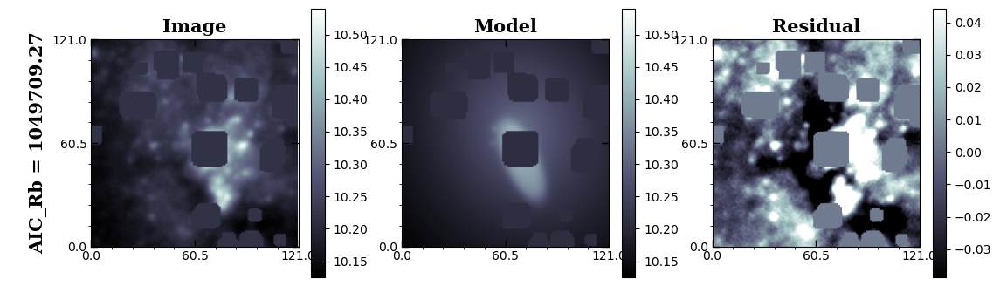

In [124]:
galid=5

ResGal=MC2_g_4comp.result(galid=galid, group_id=None)
ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=True) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]]
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]
print(fn)

MC2_g_4comp.drawing(galid=galid, fn=fn)
plt.show()
# MC2_1Comp_gm.drawing_legacy(galid=galid)

## Combine

In [61]:
MC2_g_4comp_t=copy.deepcopy(MC2_g_4comp)
## While the run will based on the previous masked result (g_1comp_m), the masking will be based on the non-center masking)
MC2_g_4comp_t.class_update_keys(proj_folder='g_4comp_t/', re_lim_list=psf_lim_g)
Runlist4Comp_tot = copy.deepcopy(MC2_g_4comp.RunlistClass)
Runlist4Comp_tot.add_runlist(MC2_g_3comp_t.RunlistClass) ## 3&2&1 comp models
#Runlist2Comp_tot.show_runlist()
MC2_g_4comp_t.update_Class(Runlist4Comp_tot, DIgood)

## Copy the data
dhfc.multicore_generate_link_galfit(DIgood, MC2_g_4comp, MC2_g_4comp_t)
dhfc.multicore_generate_link_galfit(DIgood, MC2_g_3comp_t, MC2_g_4comp_t)

0 / 215 | Time :  0.015465736389160156
Done! | Time :  0.04602670669555664
0 / 215 | Time :  0.019006729125976562
Done! | Time :  0.11389374732971191


In [62]:
ResPack_g_4Comp_t=MC2_g_4comp_t.pack_result()
pickle.dump(ResPack_g_4Comp_t, open(DIgood.dir_base+"ResPack_g_4Comp_t_hrb.pkl", "wb"))
ResPack_g_4Comp_t=pickle.load(open(DIgood.dir_base+"ResPack_g_4Comp_t_hrb.pkl", "rb"))
ResPack_g_4Comp_t.preset_generate_onlyval(is_mag=False)

Pack the results
>> comp_crit:  AIC_hRb
======== Multicore Briefing ========
● Multicore run for sub_getdata with Ncore 16
● Using Try (Ignoring Errors): True


  3%|▉                                  | 6/215 [00:00<00:00, 108473.38it/s]

Done! | Time :  1.348710298538208
>> Get all submodels


## r-band

In [127]:
MC2_r_4comp=copy.deepcopy(MC2_g_4comp)
MC2_r_4comp.class_update_keys(proj_folder='r_4comp/',           ## Folder name for this fit
                             fni_image = 'image_lr.fits',      ## image name (in DI.dir_work_list)
                             fni_sigma = 'sigma_lr.fits',      ## sigma name (in DI.dir_work_list)
                             fni_psf = 'psf_model_lr.fits',    ## psf name (in DI.dir_work_list)
                             re_lim_list = psf_lim_r
                             )

In [128]:
ResPack_r_3Comp.preset_generate_onlyval(submodel=5) ## Sersic + Sersic + PSF
PrevRes_sspp_Temp=copy.deepcopy(ResPack_r_3Comp.thismodel_params_array) ## previous result. Shape: N_Target(DI), Comp, item (7)
PrevRes_sspp=np.zeros((len(PrevRes_sspp_Temp), 4, 7)) ## 4 components
PrevRes_sspp[:,:3,:]=copy.deepcopy(PrevRes_sspp_Temp)
# PrevRes_sspp[:,0,:] --> Comp2 (1st comp for the gal). 
# PrevRes_sspp[:,1,:] --> Comp3 (2nd comp for the gal). 
# PrevRes_sspp[:,2,:] --> Comp4 (3rd comp for the gal). 
PrevRes_sspp[:,3,:]=np.nan # Reset the parameters for Comp3 (2nd comp for the gal)
PrevRes_sspp[:,3,0]=np.nan # By using Nan for the position, the position will be set to the center of the image
PrevRes_sspp[:,3,1]=np.nan # By using Nan for the position, the position will be set to the center of the image
PrevRes_sspp[:,3,2]=PrevRes_sspp[:,0,2] # Copy the mag

## Update the Setting class
MC2_r_4comp.update_Class(Runlist4Comp_sspp, DIgood,
                         base_params_array_set=PrevRes_sspp,  ## Previous Galfit result array
                         base_params_add=True,            ## Add the offset to the previous result
                        )


>> Get submodels:  5
>> Group index:  0


In [129]:
MC2_r_4comp.run()

======== Multicore Briefing ========
● Multicore run for sub_run_process with Ncore 16
● Using Try (Ignoring Errors): True


100%|██████████████████████████████████| 215/215 [05:23<00:00,  1.50s/it]

Done! | Time :  323.5434832572937
======== Multicore summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning (w/failed): 0 / 215



In [130]:
MC2_r_4comp.extract()
MC2_r_4comp.postprocessing()
MC2_r_4comp.postprocessing(stat_radius_array_set=stat_radius_array_g,
                           stat_item_namelist=stat_item_name_array) ## additional Stat regions
ResPack_r_4Comp=MC2_r_4comp.pack_result()
pickle.dump(ResPack_r_4Comp, open(DIgood.dir_base+"ResPack_r_4Comp.pkl", "wb"))
ResPack_r_4Comp=pickle.load(open(DIgood.dir_base+"ResPack_r_4Comp.pkl", "rb"))
ResPack_r_4Comp.preset_generate_onlyval(is_mag=False)

======== Multicore Briefing ========
● Multicore run for sub_run_process with Ncore 16
● Using Try (Ignoring Errors): True


100%|█████████████████████████████████| 215/215 [00:00<00:00, 368.26it/s]

Done! | Time :  0.7434914112091064
======== Multicore summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning (w/failed): 0 / 215



0  /215 | Time :  0.1152801513671875
Done! | Time :  0.14309191703796387
======== Multicore Briefing ========
● Multicore run for sub_run_process with Ncore 16
● Using Try (Ignoring Errors): True


  0%|                                            | 0/215 [00:00<?, ?it/s]

>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0016/r_4comp/result_sspp_fo_m3m3.fits
>> Warning! No safe_itemlist!


... (70 outputs left out)

Done! | Time :  4.511208534240723
======== Multicore summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning (w/failed): 0 / 215

Pack the results
>> comp_crit:  AIC_Rb
======== Multicore Briefing ========
● Multicore run for sub_getdata with Ncore 16
● Using Try (Ignoring Errors): True


>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) ./gal_out/gal0016/r_4comp/result_sspp_fo_m3m3.fits
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) 
./gal_out/gal0033/r_4comp/result_sspp_fo_m3m3.fits
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.) >> Warning! No safe_itemlist!./gal_out/gal0041/r_4comp/result_sspp_fo_m3m3.fits
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.)
 
./gal_out/gal0049/r_4comp/result_sspp_fo_m3m3.fits>> Warning! No safe_itemlist!>> Warning! No safe_itemlist!

>> Warning! No safe_itemlist!>> Warning! No safe_itemlist!

>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> Warning! No safe_itemlist!
>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.)
 ./gal_out/gal0111/r_4comp/result_sspp_fo_m3m3.fits>> Warning! No safe_itemlist!>> ♣♣♣ Warning! ♣♣♣ No files! .... e.g.)
>> Warning! No safe_itemlist! ./gal_out/gal0122/r_4comp/result_sspp_fo_m3m3.fits

>> Warning! No safe_itemlist

  3%|▉                                | 6/215 [00:00<00:00, 88612.06it/s]

Done! | Time :  0.4604458808898926
>> Get all submodels


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_MAG,4_XC,4_YC,4_MAG,5_XC,5_YC,5_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
sspp_fo_m3p3,7.000000,0.000000,71.000000,51.000000,21.843400,18.673800,0.111200,17.285600,71.000000,71.000000,21.734500,121.000000,0.719200,11.806500,54.007000,60.358900,19.859200,51.000000,51.000000,102.877200,132.961900,132.961913,1549181.329313,0.000000,172.819921,1027629.405425,0.000000,1052284.149249,0.000000,366318.174016,0.000000
sspp_fo_p0p3,7.000000,0.000000,71.000000,51.000000,21.844300,18.677000,0.112300,17.283500,71.000000,71.000000,21.734600,121.000000,0.719300,11.806400,54.616400,60.630800,20.949400,51.000000,51.000000,104.077200,124.692200,124.692205,1452830.954313,0.000000,156.609969,931245.030425,0.000000,955898.899249,0.000000,270285.049016,0.000000


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,4_XC,4_YC,4_MAG,5_XC,5_YC,5_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
sspp_fo_p0p3,7.000000,0.000000,71.000000,51.000000,21.844300,18.677000,0.112300,0.432400,26.830500,17.283500,71.000000,71.000000,21.734600,121.000000,0.719300,0.894000,3.779200,11.806400,54.616400,60.630800,20.949400,51.000000,51.000000,104.077200,124.692200,124.692205,1452830.954313,0.000000,156.609969,931245.030425,0.000000,955898.899249,0.000000,270285.049016,0.000000


./gal_out/gal0005/r_4comp/result_sspp_fo_p0p3.fits


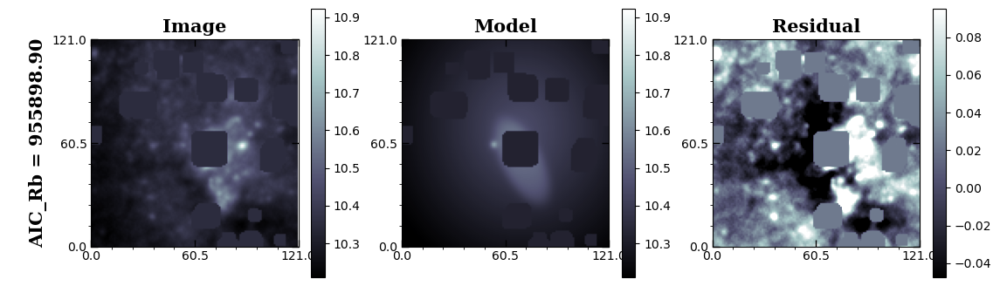

In [131]:
galid=5

ResGal=MC2_r_4comp.result(galid=galid, group_id=None)
ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=True) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]]
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]
print(fn)

MC2_r_4comp.drawing(galid=galid, fn=fn)
plt.show()
# MC2_1Comp_gm.drawing_legacy(galid=galid)

# Result

In [99]:
ResPack_g_1Comp=pickle.load(open(DIgood.dir_base+"ResPack_g_1Comp.pkl", "rb"))
ResPack_g_1Comp.preset_generate_onlyval(is_mag=False)

ResPack_g_1Comp_m=pickle.load(open(DIgood.dir_base+"ResPack_g_1Comp_m.pkl", "rb"))
ResPack_g_1Comp_m.preset_generate_onlyval(is_mag=False)

ResPack_g_2Comp_t=pickle.load(open(DIgood.dir_base+"ResPack_g_2Comp_t.pkl", "rb"))
ResPack_g_2Comp_t.preset_generate_onlyval(is_mag=False)

ResPack_g_3Comp=pickle.load(open(DIgood.dir_base+"ResPack_g_3Comp.pkl", "rb"))
ResPack_g_3Comp.preset_generate_onlyval(is_mag=False)

ResPack_g_4Comp=pickle.load(open(DIgood.dir_base+"ResPack_g_4Comp.pkl", "rb"))
ResPack_g_4Comp.preset_generate_onlyval(is_mag=False)

>> Get all submodels
>> Get all submodels
>> Get all submodels
>> Get all submodels
>> Get all submodels


In [53]:
ResPack_r_1Comp=pickle.load(open(DIgood.dir_base+"ResPack_r_1Comp.pkl", "rb"))
ResPack_r_1Comp.preset_generate_onlyval(is_mag=False)

ResPack_r_1Comp_m=pickle.load(open(DIgood.dir_base+"ResPack_r_1Comp_m.pkl", "rb"))
ResPack_r_1Comp_m.preset_generate_onlyval(is_mag=False)

ResPack_r_2Comp_t=pickle.load(open(DIgood.dir_base+"ResPack_r_2Comp_t.pkl", "rb"))
ResPack_r_2Comp_t.preset_generate_onlyval(is_mag=False)

ResPack_r_3Comp=pickle.load(open(DIgood.dir_base+"ResPack_r_3Comp.pkl", "rb"))
ResPack_r_3Comp.preset_generate_onlyval(is_mag=False)

ResPack_r_4Comp=pickle.load(open(DIgood.dir_base+"ResPack_r_4Comp.pkl", "rb"))
ResPack_r_4Comp.preset_generate_onlyval(is_mag=False)

>> Get all submodels
>> Get all submodels
>> Get all submodels
>> Get all submodels
>> Get all submodels


## g-band

,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50
s_fs_26,0.000000,0.000000,60.806600,61.219500,22.562100,9.465000,1.303300,0.634200,75.305200,18.265200,1.121909,1.121909,12878.703967,0.000000,1.202957,8324.846047,0.000000


./gal_out/gal0005/g_1comp/result_s_fs_26.fits


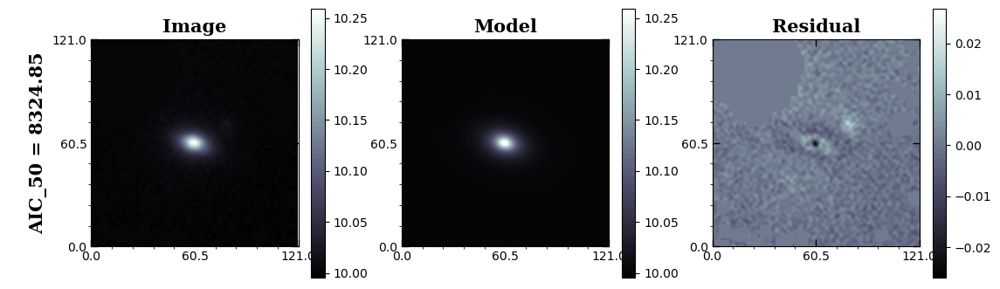

In [100]:
galid=5

ResGal=ResPack_g_1Comp.MC2fitSettingClass.result(galid=galid, group_id=None)
#ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=False) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]]
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]
print(fn)

ResPack_g_1Comp.MC2fitSettingClass.drawing(galid=galid, fn=fn)
plt.show()
# MC2_1Comp_gm.drawing_legacy(galid=galid)

,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
s_fs_26,0.000000,0.000000,60.806600,61.219500,22.562100,9.465000,1.303300,0.634200,75.305200,18.265200,nan,nan,nan,nan,nan,nan,nan,nan,1.121909,1.121909,12878.703967,0.000000,1.202957,8324.846047,0.000000,1883.586088,0.000000,797.591190,0.000000
ss_fo_p3p3,1.000000,0.000000,60.841200,61.168800,22.292800,8.188600,1.048400,0.613100,74.732300,18.451000,60.512600,71.000000,26.072300,54.660700,0.648000,0.718900,-39.999400,18.151300,0.836470,0.836470,9614.319240,1.000000,0.892896,6191.051021,1.000000,1279.773504,0.435934,427.235981,0.000231
sp_mo_p3m3,2.000000,0.000000,60.895100,61.195300,22.602400,9.520700,1.340700,0.644000,75.438400,18.262400,54.685000,62.945000,nan,nan,nan,nan,nan,23.791300,1.108181,1.108181,12723.988855,0.000000,1.184015,8196.474768,0.000000,1837.408093,0.000000,775.403660,0.000000


./gal_out/gal0005/g_2comp_t/result_ss_fo_p3p3.fits


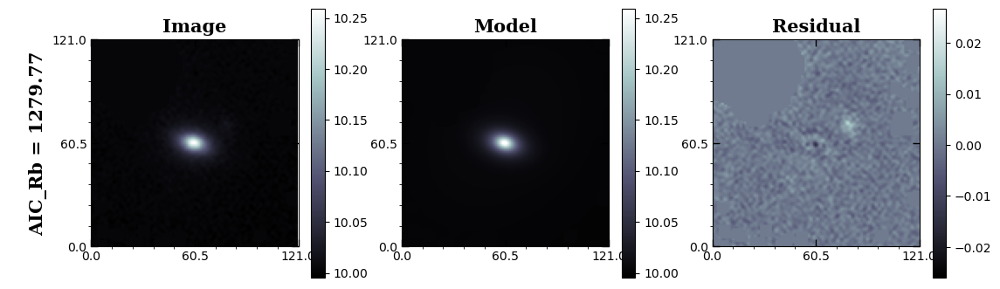

In [102]:
galid=5

ResGal=ResPack_g_2Comp_t.MC2fitSettingClass.result(galid=galid, group_id=None)
#ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=False) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]]
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]
print(fn)

ResPack_g_2Comp_t.MC2fitSettingClass.drawing(galid=galid, fn=fn)
plt.show()
# MC2_1Comp_gm.drawing_legacy(galid=galid)

,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,4_XC,4_YC,4_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
ssp_fo_p3p3,5.000000,1.000000,60.889200,61.158100,22.327800,8.261500,1.081600,0.619700,74.819200,18.440500,60.306100,71.000000,26.078400,56.792100,0.631600,0.712800,-39.960200,18.094500,54.466900,63.101800,24.500200,0.833946,0.833946,9588.915186,1.000000,0.889958,6174.136297,1.000000,1277.366225,0.480137,438.221938,0.000084
spp_fo_p3m3,6.000000,1.000000,60.953300,61.172100,22.622800,9.544100,1.353300,0.649600,75.697900,18.263500,56.406900,62.788400,nan,nan,nan,nan,nan,23.832800,52.965500,63.624800,24.125600,1.103729,1.103729,12675.665562,0.000000,1.178121,8158.271807,0.000000,1839.709990,0.000000,786.022076,0.000000


./gal_out/gal0005/g_3comp/result_ssp_fo_p3p3.fits


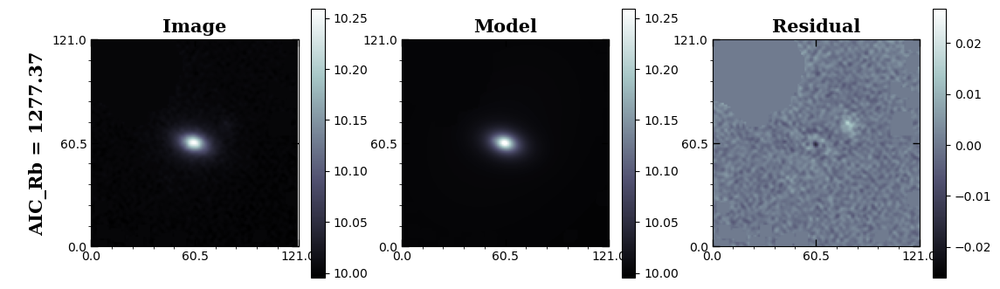

In [104]:
galid=5

ResGal=ResPack_g_3Comp.MC2fitSettingClass.result(galid=galid, group_id=None)
#ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=False) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]]
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]
print(fn)

ResPack_g_3Comp.MC2fitSettingClass.drawing(galid=galid, fn=fn)
plt.show()
# MC2_1Comp_gm.drawing_legacy(galid=galid)

,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,4_XC,4_YC,4_MAG,5_XC,5_YC,5_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
sspp_fo_p3p3,7.000000,1.000000,60.922700,61.124100,22.329800,8.245000,1.073100,0.620100,75.105500,18.449800,60.189000,71.000000,26.070100,55.788200,0.634400,0.715400,-40.108100,18.119100,54.186900,63.157700,24.395300,58.810600,63.913700,24.455600,0.831040,0.831040,9559.152957,1.000000,0.884757,6141.647233,1.000000,1250.245248,0.713728,409.406770,0.004117


./gal_out/gal0005/g_4comp/result_sspp_fo_p3p3.fits


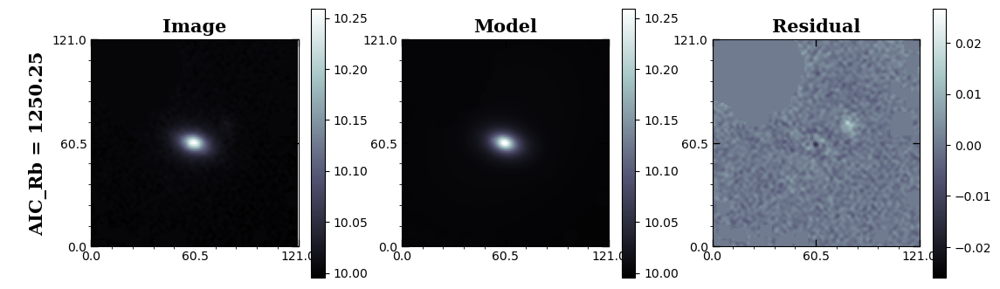

In [105]:
galid=5

ResGal=ResPack_g_4Comp.MC2fitSettingClass.result(galid=galid, group_id=None)
#ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=False) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]]
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]
print(fn)

ResPack_g_4Comp.MC2fitSettingClass.drawing(galid=galid, fn=fn)
plt.show()
# MC2_1Comp_gm.drawing_legacy(galid=galid)

## r-band

,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50
s_fl_23,0.000000,0.000000,100.570800,99.643900,21.006000,9.920900,1.629900,0.614600,54.913200,16.531500,1.389002,1.389002,35930.044632,0.000000,3.083861,23999.202112,0.000000


./gal_out/gal0002/r_1comp/result_s_fl_23.fits


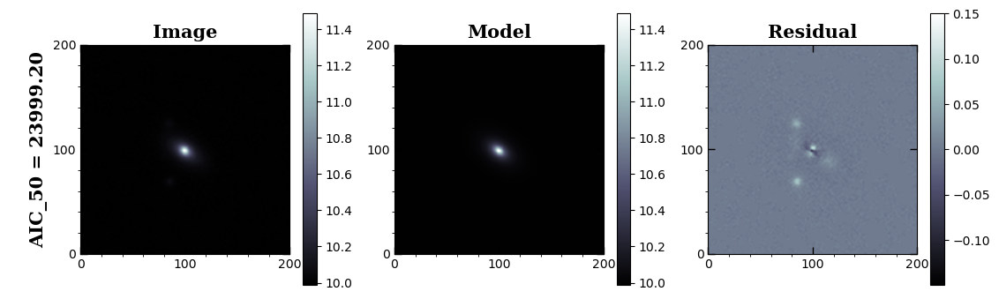

https://www.legacysurvey.org/viewer/jpeg-cutout?ra=136.3578499&dec=61.8025699&size=200&layer=ls-dr9


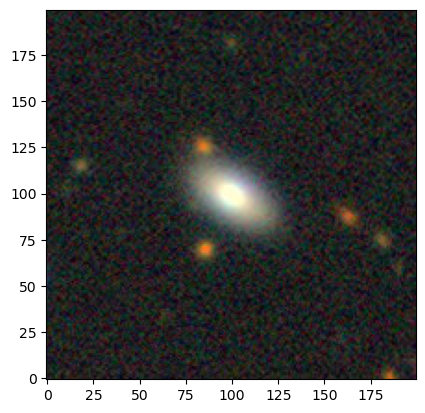

In [73]:
galid=2

ResGal=ResPack_r_1Comp.MC2fitSettingClass.result(galid=galid, group_id=None)
#ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=False) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]]
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]
print(fn)

ResPack_r_1Comp.MC2fitSettingClass.drawing(galid=galid, fn=fn)
plt.show()
ResPack_r_1Comp.MC2fitSettingClass.drawing_legacy(galid=galid)

,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
ss_fo_p0p3,1.000000,0.000000,100.676000,99.476800,21.426600,12.296800,1.139100,0.559900,55.529000,16.761300,100.492900,99.865600,20.520400,3.143700,0.788000,0.923900,30.621800,18.443000,1.218989,1.218989,31539.672867,0.000000,2.518535,19599.077409,0.000000,1317.306218,0.183005,392.930225,0.010756
sp_fo_p0p3,2.000000,0.000000,100.533800,99.533900,21.042100,10.143700,1.618400,0.603600,55.222700,16.542400,101.607300,102.397300,nan,nan,nan,nan,nan,21.358600,1.318209,1.318209,34101.654743,0.000000,2.848630,22167.280057,0.000000,3667.977673,0.000000,1779.586277,0.000000


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG
ss_fo_p0p3,1.000000,0.000000,0.009500,0.010300,0.015200,0.078200,0.015400,0.001300,0.108800,0.000000,0.011700,0.011800,0.019000,0.032300,0.010900,0.007500,5.641200,0.000000
sp_fo_p0p3,2.000000,0.000000,0.005400,0.003700,0.003100,0.018000,0.004100,0.000800,0.100200,0.000000,0.038400,0.030800,nan,nan,nan,nan,nan,0.022100


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG
ss_fo_p0p3,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
sp_fo_p0p3,2,0,0,0,0,0,0,0,0,0,0,0,nan,nan,nan,nan,nan,0


./gal_out/gal0002/r_2comp_t/result_ss_fo_p0p3.fits


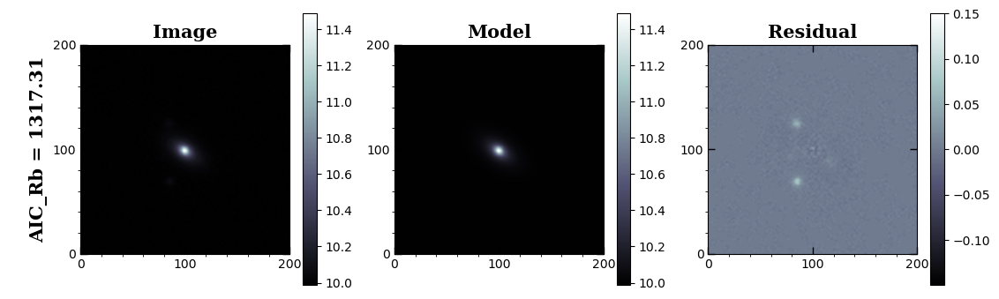

In [83]:
galid=2
ResGal=ResPack_r_2Comp_t.MC2fitSettingClass.result(galid=galid, group_id=None)
#ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=False) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=False, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]]
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]
print(fn)

ResPack_r_2Comp_t.MC2fitSettingClass.drawing(galid=galid, fn=fn)
plt.show()
# MC2_1Comp_gm.drawing_legacy(galid=galid)

,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,4_XC,4_YC,4_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
ssp_fo_p3m3,5.000000,1.000000,100.555500,98.611500,23.445100,5.611200,10.000000,0.733500,49.510000,19.070400,99.629300,102.245500,21.919800,2.820000,2.000000,0.801100,-34.251500,19.786600,100.613700,101.018900,19.595200,0.646064,0.646064,22432.463091,1.000000,0.646919,4998.603827,1.000000,828.906874,1.000000,247.431670,0.999979
spp_fo_p0m3,6.000000,1.000000,100.124900,100.250600,21.406400,3.342400,2.000000,0.777600,21.460600,18.936500,100.783000,99.411900,nan,nan,nan,nan,nan,20.465100,100.452400,101.947000,20.126800,0.653169,0.653169,22673.383208,1.000000,0.677930,5231.168988,1.000000,1022.562041,1.000000,374.721112,0.047241


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,4_XC,4_YC,4_MAG
ssp_fo_p3m3,5.000000,1.000000,0.042500,0.106500,0.523400,1.230200,1.970100,0.022900,3.458900,0.000000,0.099200,0.199600,0.125700,0.145000,0.294800,0.027000,8.887800,0.000000,0.028600,0.066400,0.033000
spp_fo_p0m3,6.000000,1.000000,0.029500,0.031000,0.126100,0.181000,0.179800,0.008700,1.925000,0.000000,0.040500,0.082800,nan,nan,nan,nan,nan,0.109900,0.028300,0.057600,0.055000


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,4_XC,4_YC,4_MAG
ssp_fo_p3m3,5,1,0,0,0,0,3,0,0,0,0,0,0,0,102,0,0,0,0,0,0
spp_fo_p0m3,6,1,0,0,0,0,2,0,0,0,0,0,nan,nan,nan,nan,nan,0,0,0,0


./gal_out/gal0006/r_3comp/result_spp_fo_p0m3.fits


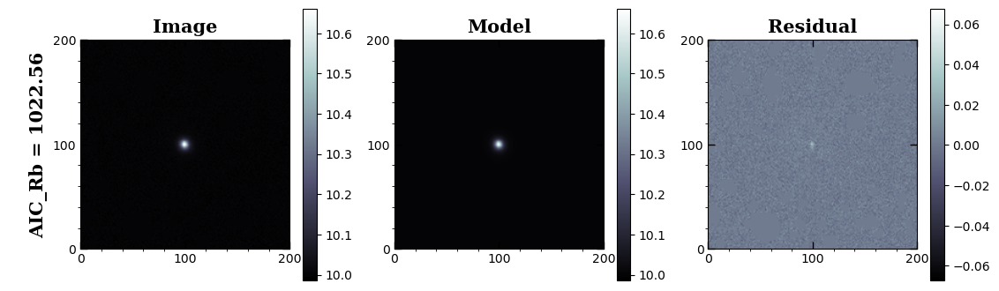

https://www.legacysurvey.org/viewer/jpeg-cutout?ra=189.7348778&dec=33.1658869&size=200&layer=ls-dr9


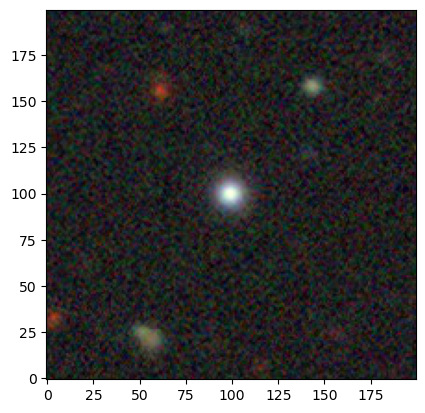

In [82]:
galid=6

ResGal=ResPack_r_3Comp.MC2fitSettingClass.result(galid=galid, group_id=None)
#ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=False) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=False, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]]
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]
print(fn)

ResPack_r_3Comp.MC2fitSettingClass.drawing(galid=galid, fn=fn)
plt.show()
ResPack_r_3Comp.MC2fitSettingClass.drawing_legacy(galid=galid)

In [63]:
ResPack_r_4Comp.MC2fitSettingClass.drawing?

,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,4_XC,4_YC,4_MAG,5_XC,5_YC,5_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
sspp_fo_p3p3,7.000000,1.000000,100.507400,98.730800,23.401100,5.427800,9.623000,0.726200,45.745900,19.130000,99.686300,101.822000,21.951800,2.820000,2.000000,0.856600,-19.555200,19.745900,100.480800,101.783800,20.412300,100.747700,100.442600,20.271700,0.645255,0.645255,22408.505173,1.000000,0.643313,4975.043368,1.000000,1162.902721,1.000000,301.181020,1.000000


./gal_out/gal0006/r_4comp/result_sspp_fo_p3p3.fits


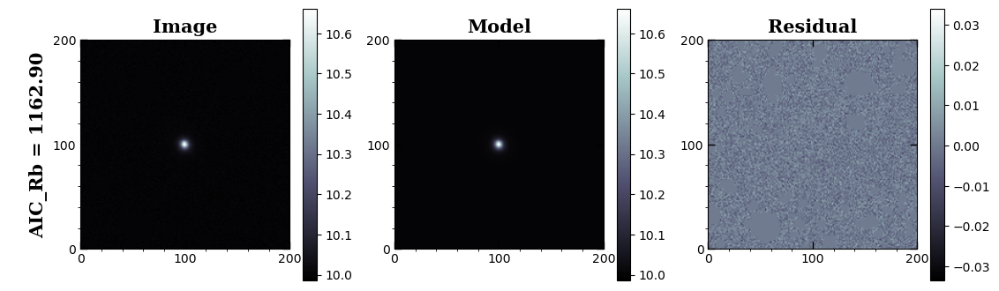

In [80]:
galid=6

ResGal=ResPack_r_4Comp.MC2fitSettingClass.result(galid=galid, group_id=None)
#ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=False) ## Show the summary
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False) ## Show the summary (Only best result for each group)

# fn=ResGal.Data.fnlist[ResGal.best[0]]
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]
print(fn)

ResPack_r_4Comp.MC2fitSettingClass.drawing(galid=galid, fn=fn, resi_scale=0.1)
plt.show()
# MC2_1Comp_gm.drawing_legacy(galid=galid)

## Fixed N

,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
ss_fon_p3p3,1.000000,0.000000,99.724600,100.085000,22.965000,8.250400,1.000000,0.696000,80.434000,18.991300,100.754600,100.618300,20.968900,2.860000,4.000000,0.315100,4.954900,19.461000,0.645101,0.645101,21958.147426,1.000000,0.737284,5783.496326,1.000000,1637.002557,0.000000,825.602626,0.000000
sp_fon_p0p3,2.000000,0.000000,100.118700,100.143000,22.418500,6.527200,1.000000,0.879300,54.193800,18.699700,100.833300,100.733900,nan,nan,nan,nan,nan,20.377300,0.664935,0.664935,22628.449830,1.000000,0.824060,6457.581876,1.000000,2364.743948,0.000000,1529.555136,0.000000


./gal_out/gal0005/g_2comp_n/result_ss_fon_p3p3.fits


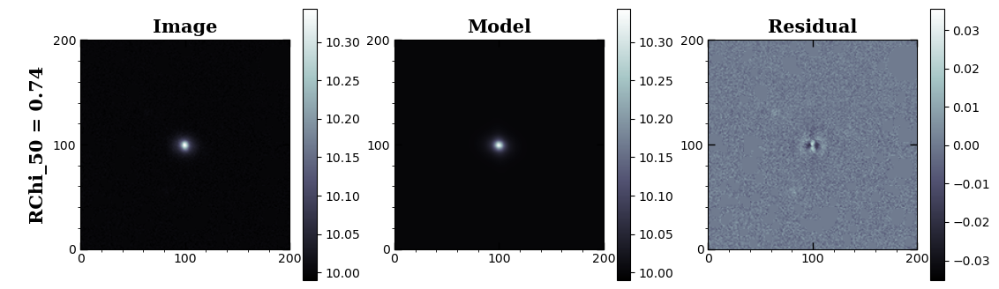

In [ ]:
galid=5
ResGal=MC2_2Comp_gn.result(galid=galid,
                          group_id=None, 
                          comp_autoswap=True, ## Higher Sersic -> comp 3
                           comp_crit='AIC_hRb', 
                           chi2_itemlist=['CHI2NU', 'RChi_F', 'AIC_F', 'LIK_F', 'RChi_50', 'AIC_50', 'LIK_50',
                                    'AIC_Rb', 'LIK_Rb', 'AIC_hRb', 'LIK_hRb'
                                           ], 
                   
                   
                   )
#ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=True)
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False)

# fn=ResGal.Data.fnlist[ResGal.best[0]]
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]
print(fn)

MC2_2Comp_gn.drawing(galid=galid, fn=fn)
plt.show()
#MC2_2Comp_gtot.drawing_legacy(galid=galid)

In [ ]:
!pwd

/home/donghyeon/ua/udg/galfit/galfit/Galfit_Run/Brandon_200


,group_ID,is_swap,2_XC,2_YC,2_MU_E,2_RE,2_N,2_AR,2_PA,2_MAG,3_XC,3_YC,3_MU_E,3_RE,3_N,3_AR,3_PA,3_MAG,4_XC,4_YC,4_MAG,CHI2NU,RChi_F,AIC_F,LIK_F,RChi_50,AIC_50,LIK_50,AIC_Rb,LIK_Rb,AIC_hRb,LIK_hRb
ssp_fon_p3p3,5.000000,0.000000,99.723500,100.606400,22.913900,8.003600,1.000000,0.756300,81.117300,18.915900,100.857500,98.616000,21.610900,2.860000,4.000000,0.300000,7.624300,20.156400,100.789100,101.678900,20.631200,0.638555,0.638555,21739.685925,1.000000,0.709048,5566.901730,1.000000,1438.744618,0.000700,659.356363,0.000000
spp_fon_p0p3,6.000000,0.000000,100.120600,100.142700,22.419300,6.528500,1.000000,0.879500,54.252900,18.699900,100.829400,100.733700,nan,nan,nan,nan,nan,20.376700,113.641300,87.438900,53.672700,0.664995,0.664995,22634.495082,1.000000,0.824379,6463.619861,1.000000,2370.872918,0.000000,1536.385768,0.000000


./gal_out/gal0005/g_3comp_n/result_ssp_fon_p3p3.fits


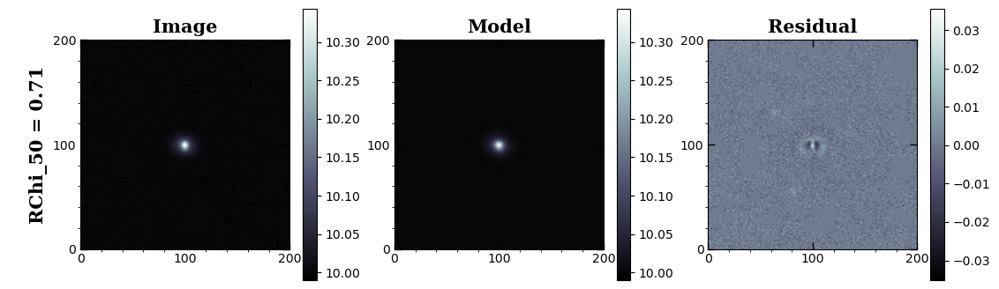

In [ ]:
galid=5
ResGal=MC2_3Comp_gn.result(galid=galid,
                          group_id=None, 
                          comp_autoswap=True, ## Higher Sersic -> comp 3
                           comp_crit='AIC_hRb', 
                           chi2_itemlist=['CHI2NU', 'RChi_F', 'AIC_F', 'LIK_F', 'RChi_50', 'AIC_50', 'LIK_50',
                                    'AIC_Rb', 'LIK_Rb', 'AIC_hRb', 'LIK_hRb'
                                           ], 
                   
                   
                   )
#ResGal.show_data(only_val=True, hide_PA=True, hide_fail_read=True)
ResBest=dhmc2fit.ResultBest(ResGal, include_warn=True, get_single=True)
ResBest.show_data(only_val=True, hide_PA=False)

# fn=ResGal.Data.fnlist[ResGal.best[0]]
fn=ResGal.Data.fnlist[ResGal.best_warn[0]]
print(fn)

MC2_3Comp_gn.drawing(galid=galid, fn=fn)
plt.show()
#MC2_2Comp_gtot.drawing_legacy(galid=galid)